In [1]:
import matplotlib.pyplot as plt
import os
import pandas as pd
import numpy as np
import geopandas as gpd


LOADING FLOW | SINGLE OBJECTIVE
Reading: Furey | HBV_capillary | flow | Single

LOADING FLOW | MULTI OBJECTIVE
Reading: Furey | HBV_capillary | flow | Multi

LOADING BASEFLOW | SINGLE OBJECTIVE
Reading: Furey | HBV_capillary | baseflow | Single

LOADING BASEFLOW | MULTI OBJECTIVE
Reading: Furey | HBV_capillary | baseflow | Multi

FINAL NSE SUMMARY
Flow - Single            : N =   531, Median = 0.6214, Mean = 0.3388
Flow - Multi             : N =   531, Median = 0.6349, Mean = 0.3477
Baseflow - Single        : N =   531, Median = 0.3803, Mean = -0.0348
Baseflow - Multi         : N =   531, Median = 0.6210, Mean = -0.0067


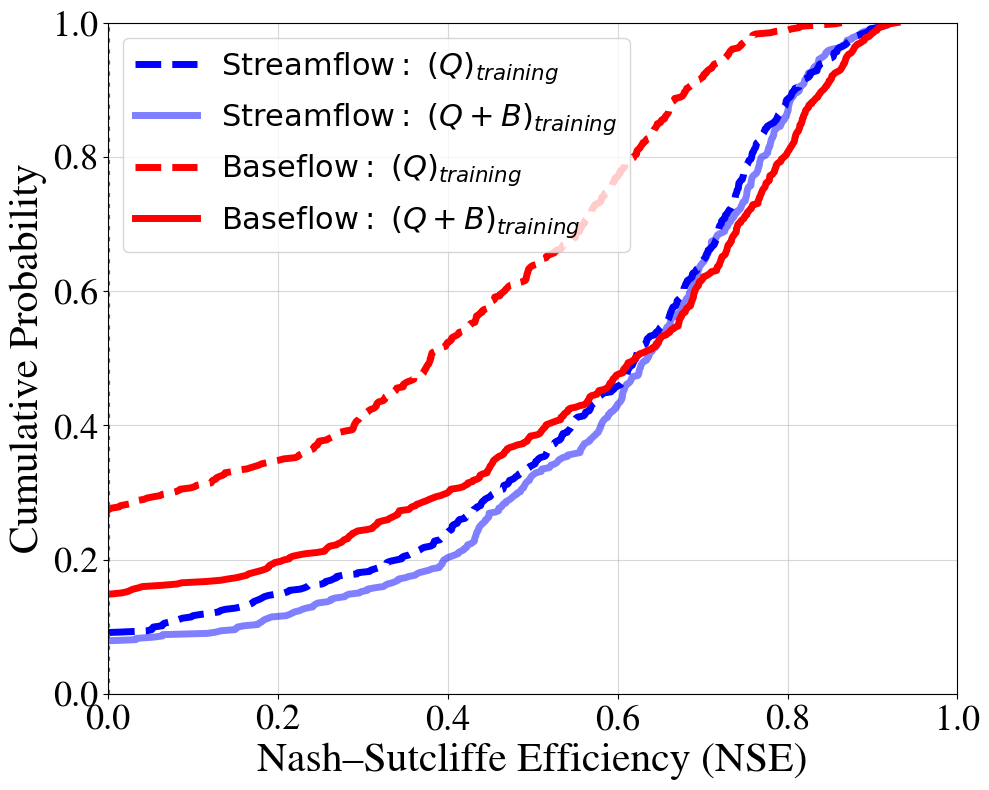

In [ ]:
## NSE CDF for HBV_GW2SM and Furey
import numpy as np
import os
import matplotlib.pyplot as plt
loss= 'NSE'
plt.rcParams['font.family'] = 'Nimbus Roman'


# ============================================================
# SETTINGS
# ============================================================
test= 'PUR'
methods = [
    # 'USGS',
    'Furey',
    'Eckhardt',
    'LocalHYSEP'
]

methods= ['Furey']

models = [
    'HBV',
    'HBV_capillary',
    'marrmot_PRMS'
]

models= ['HBV_capillary']

fold_numbers = range(1, 8)


# ============================================================
# PUB BASE DIRECTORY
# ============================================================

BASE_DIR = (
    "/home/s0shar47/scratch/"
    f"OUTPUTS_Paper1v2/{test}"
)


# ============================================================
# DYNAMIC PARAMETER FOLDER
# ============================================================

def get_dyn(model):

    if model == 'HBV':
        return 'parBETA_parBETAET_'

    elif model == 'HBV_capillary':
        return 'parBETA_parBETAET_parK0_parUZL_'

    elif model == 'marrmot_PRMS':
        return 'alpha_cgw_scx_tt_'

    else:
        raise ValueError(
            f"Unknown model: {model}"
        )


# ============================================================
# NSE
# ============================================================

def calc_nse(obs, sim):

    mask = (
        np.isfinite(obs)
        &
        np.isfinite(sim)
    )

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    denominator = np.sum(
        (obs - np.mean(obs)) ** 2
    )

    if denominator == 0:
        return np.nan

    numerator = np.sum(
        (obs - sim) ** 2
    )

    return 1 - numerator / denominator


# ============================================================
# GET NSE
#
# component:
#     flow
#     baseflow
#
# objective:
#     Single
#     Multi
# ============================================================

def get_all_nse(component, objective):

    all_nse = []

    print("\n" + "=" * 80)
    print(
        f"LOADING {component.upper()} | "
        f"{objective.upper()} OBJECTIVE"
    )
    print("=" * 80)

    # ========================================================
    # LOOP METHODS
    # ========================================================

    for method in methods:

        # ====================================================
        # LOOP MODELS
        # ====================================================

        for model in models:

            dyn = get_dyn(model)

            print(
                f"Reading: {method} | "
                f"{model} | "
                f"{component} | "
                f"{objective}"
            )

            # =================================================
            # LOOP 10 PUB FOLDS
            # =================================================

            for fold in fold_numbers:

                region = f'Region_{fold}'

                # ====================================================
                # FOLDER DEFINITIONS
                # ====================================================

                single_folder = os.path.join(
                    BASE_DIR,
                    f"Single/NSE/{model}",
                    region
                )

                multi_folder = os.path.join(
                    BASE_DIR,
                    f"{method}_Multi/NSE/{model}",
                    region
                )


                # ====================================================
                # SIMULATION FOLDER
                # ====================================================

                if objective == 'Single':

                    simulation_folder = (
                        single_folder
                    )

                elif objective == 'Multi':

                    simulation_folder = (
                        multi_folder
                    )

                else:

                    raise ValueError(
                        f"Unknown objective: {objective}"
                    )


                # ====================================================
                # RUN FOLDER
                # ====================================================

                run_folder = (
                    f"LSTM_{model}_E50_R365_B100_H256_"
                    f"tr1989_1999_n16_111111"
                )


                # ====================================================
                # BASE RUN DIRECTORY
                # ====================================================

                run_dir = os.path.join(
                    run_folder,
                    dyn,
                    "ts1989_1999"
                )


                # ====================================================
                # FLOW
                # ====================================================

                if component == 'flow':

                    obs_file = os.path.join(
                        simulation_folder,
                        run_dir,
                        "00060_Mean.npy"
                    )

                    sim_file = os.path.join(
                        simulation_folder,
                        run_dir,
                        "flow_sim.npy"
                    )


                # ====================================================
                # BASEFLOW
                # ====================================================

                elif component == 'baseflow':

                    # ------------------------------------------------
                    # IMPORTANT:
                    #
                    # Observed baseflow ALWAYS comes from Multi
                    # because Single does not contain baseflow.npy.
                    # ------------------------------------------------

                    obs_file = os.path.join(
                        multi_folder,
                        run_dir,
                        "baseflow.npy"
                    )

                    # ------------------------------------------------
                    # Simulated groundwater flow depends on objective
                    # ------------------------------------------------

                    sim_file = os.path.join(
                        simulation_folder,
                        run_dir,
                        "gwflow.npy"
                    )


                else:

                    raise ValueError(
                        f"Unknown component: {component}"
                    )


                # ====================================================
                # CHECK FILES
                # ====================================================

                if not os.path.exists(obs_file):

                    print(
                        f"  Missing OBS: "
                        f"{method}, {model}, "
                        f"{component}, {objective}, "
                        f"fold {fold}"
                    )

                    print(
                        f"  --> {obs_file}"
                    )

                    continue


                if not os.path.exists(sim_file):

                    print(
                        f"  Missing SIM: "
                        f"{method}, {model}, "
                        f"{component}, {objective}, "
                        f"fold {fold}"
                    )

                    print(
                        f"  --> {sim_file}"
                    )

                    continue


                # ====================================================
                # LOAD
                # ====================================================

                obs = np.load(obs_file)
                sim = np.load(sim_file)

                obs = np.squeeze(obs)
                sim = np.squeeze(sim)


                # ====================================================
                # SHAPE CHECK
                # ====================================================

                if obs.shape != sim.shape:

                    print(
                        f"  Shape mismatch: "
                        f"{method}, {model}, "
                        f"{component}, {objective}, "
                        f"fold {fold}"
                    )

                    print(
                        f"  OBS shape = {obs.shape}"
                    )

                    print(
                        f"  SIM shape = {sim.shape}"
                    )

                    continue


                # ====================================================
                # BASIN-WISE NSE
                # ====================================================

                for basin in range(
                    obs.shape[1]
                ):

                    obs_basin = obs[:, basin]

                    sim_basin = sim[:, basin]

                    nse = calc_nse(
                        obs_basin,
                        sim_basin
                    )

                    if np.isfinite(nse):

                        all_nse.append(nse)


    return np.asarray(
        all_nse,
        dtype=float
    )


# ============================================================
# LOAD FLOW
# ============================================================

nse_flow_single = get_all_nse(
    component='flow',
    objective='Single'
)

nse_flow_multi = get_all_nse(
    component='flow',
    objective='Multi'
)


# ============================================================
# LOAD BASEFLOW
# ============================================================

nse_baseflow_single = get_all_nse(
    component='baseflow',
    objective='Single'
)

nse_baseflow_multi = get_all_nse(
    component='baseflow',
    objective='Multi'
)


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FINAL NSE SUMMARY")
print("=" * 80)

def print_summary(name, values):

    if len(values) == 0:

        print(
            f"{name:25s}: N = 0"
        )

    else:

        print(
            f"{name:25s}: "
            f"N = {len(values):5d}, "
            f"Median = {np.median(values):.4f}, "
            f"Mean = {np.mean(values):.4f}"
        )


print_summary(
    "Flow - Single",
    nse_flow_single
)

print_summary(
    "Flow - Multi",
    nse_flow_multi
)

print_summary(
    "Baseflow - Single",
    nse_baseflow_single
)

print_summary(
    "Baseflow - Multi",
    nse_baseflow_multi
)


# ============================================================
# EMPIRICAL CDF
# ============================================================

def empirical_cdf(values):

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:

        return (
            np.array([]),
            np.array([])
        )

    values = np.sort(values)

    y = (
        np.arange(1, len(values) + 1)
        / len(values)
    )

    return values, y


# ============================================================
# CDFS
# ============================================================

x_flow_single, y_flow_single = empirical_cdf(
    nse_flow_single
)

x_flow_multi, y_flow_multi = empirical_cdf(
    nse_flow_multi
)

x_baseflow_single, y_baseflow_single = empirical_cdf(
    nse_baseflow_single
)

x_baseflow_multi, y_baseflow_multi = empirical_cdf(
    nse_baseflow_multi
)


# ============================================================
# PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)


# ------------------------------------------------------------
# FLOW — SINGLE
# ------------------------------------------------------------

if len(x_flow_single) > 0:

    plt.plot(
        x_flow_single,
        y_flow_single,
        linewidth=5,
        linestyle='--',
        label=r'$\mathrm{Streamflow:}\ (Q)_{\mathit{training}}$'
        ,color= 'blue'
    )


# ------------------------------------------------------------
# FLOW — MULTI
# ------------------------------------------------------------

if len(x_flow_multi) > 0:

    plt.plot(
        x_flow_multi,
        y_flow_multi,
        linewidth=5,
        linestyle='-',
        label= r'$\mathrm{Streamflow:}\ (Q+B)_{\mathit{training}}$'
        ,color= 'blue',
        alpha=0.5
    )


# ------------------------------------------------------------
# BASEFLOW — SINGLE
# ------------------------------------------------------------

if len(x_baseflow_single) > 0:

    plt.plot(
        x_baseflow_single,
        y_baseflow_single,
        linewidth=5,
        linestyle='--',
        label= r'$\mathrm{Baseflow:}\ (Q)_{\mathit{training}}$'
        ,color= 'red'
    )


# ------------------------------------------------------------
# BASEFLOW — MULTI
# ------------------------------------------------------------

if len(x_baseflow_multi) > 0:

    plt.plot(
        x_baseflow_multi,
        y_baseflow_multi,
        linewidth=5,
        linestyle='-',
        label= r'$\mathrm{Baseflow:}\ (Q+B)_{\mathit{training}}$'
        ,color= 'red'
    )


# ============================================================
# NSE = 0
# ============================================================

plt.axvline(
    x=0,
    linestyle=':',
    linewidth=3
)


# ============================================================
# AXES
# ============================================================

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)


# ============================================================
# LABELS
# ============================================================

plt.xlabel(
    'Nash–Sutcliffe Efficiency (NSE)',
    fontsize=30
)

plt.ylabel(
    'Cumulative Probability',
    fontsize=30
)


# ============================================================
# TITLE
# ============================================================

# plt.title(
#     f'{test} TEST: NSE CDF',
#     fontsize=32
# )


# ============================================================
# TICKS
# ============================================================

plt.xticks(
    fontsize=26
)

plt.yticks(
    fontsize=26
)


# ============================================================
# GRID
# ============================================================

plt.grid(
    True,
    alpha=0.5
)


# ============================================================
# LEGEND
# ============================================================

plt.legend(
    fontsize=22,
    frameon=True,
    loc='upper left'
)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# SHOW
# ============================================================
# plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures_NSE/{loss}_loss_NSE_CDF_HBVcapFurey.jpg", dpi= 400)
plt.show()

HUC2 CRS before assignment: None
HUC2 bounds before transformation:
[-7783576.02289802  2187575.63815253  3619690.05690435 10257816.27458091]
HUC2 CRS after assignment: EPSG:26915
HUC2 CRS after transformation: EPSG:4326
HUC2 bounds after transformation:
[-179.96928239   17.67456073  179.91556688   71.39676244]

HUC2 columns:
['HUC2', 'COUNT', 'REG_NAME', 'ACRES', 'geometry']

Using HUC2 column: HUC2

HUC2 codes found:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']

The following HUC2 regions were not assigned:
['19', '20', '21']

PUR REGION SUMMARY
   PUR_region                                           geometry
0           1  MULTIPOLYGON (((-75.90469 37.11406, -75.91338 ...
1           2  MULTIPOLYGON (((-83.07339 29.09564, -83.07442 ...
2           3  MULTIPOLYGON (((-77.85699 41.82669, -77.85942 ...
3           4  POLYGON ((-105.67422 40.27259, -105.6871 40.28...
4           5  MULTIPOLYGON (((-97.2193

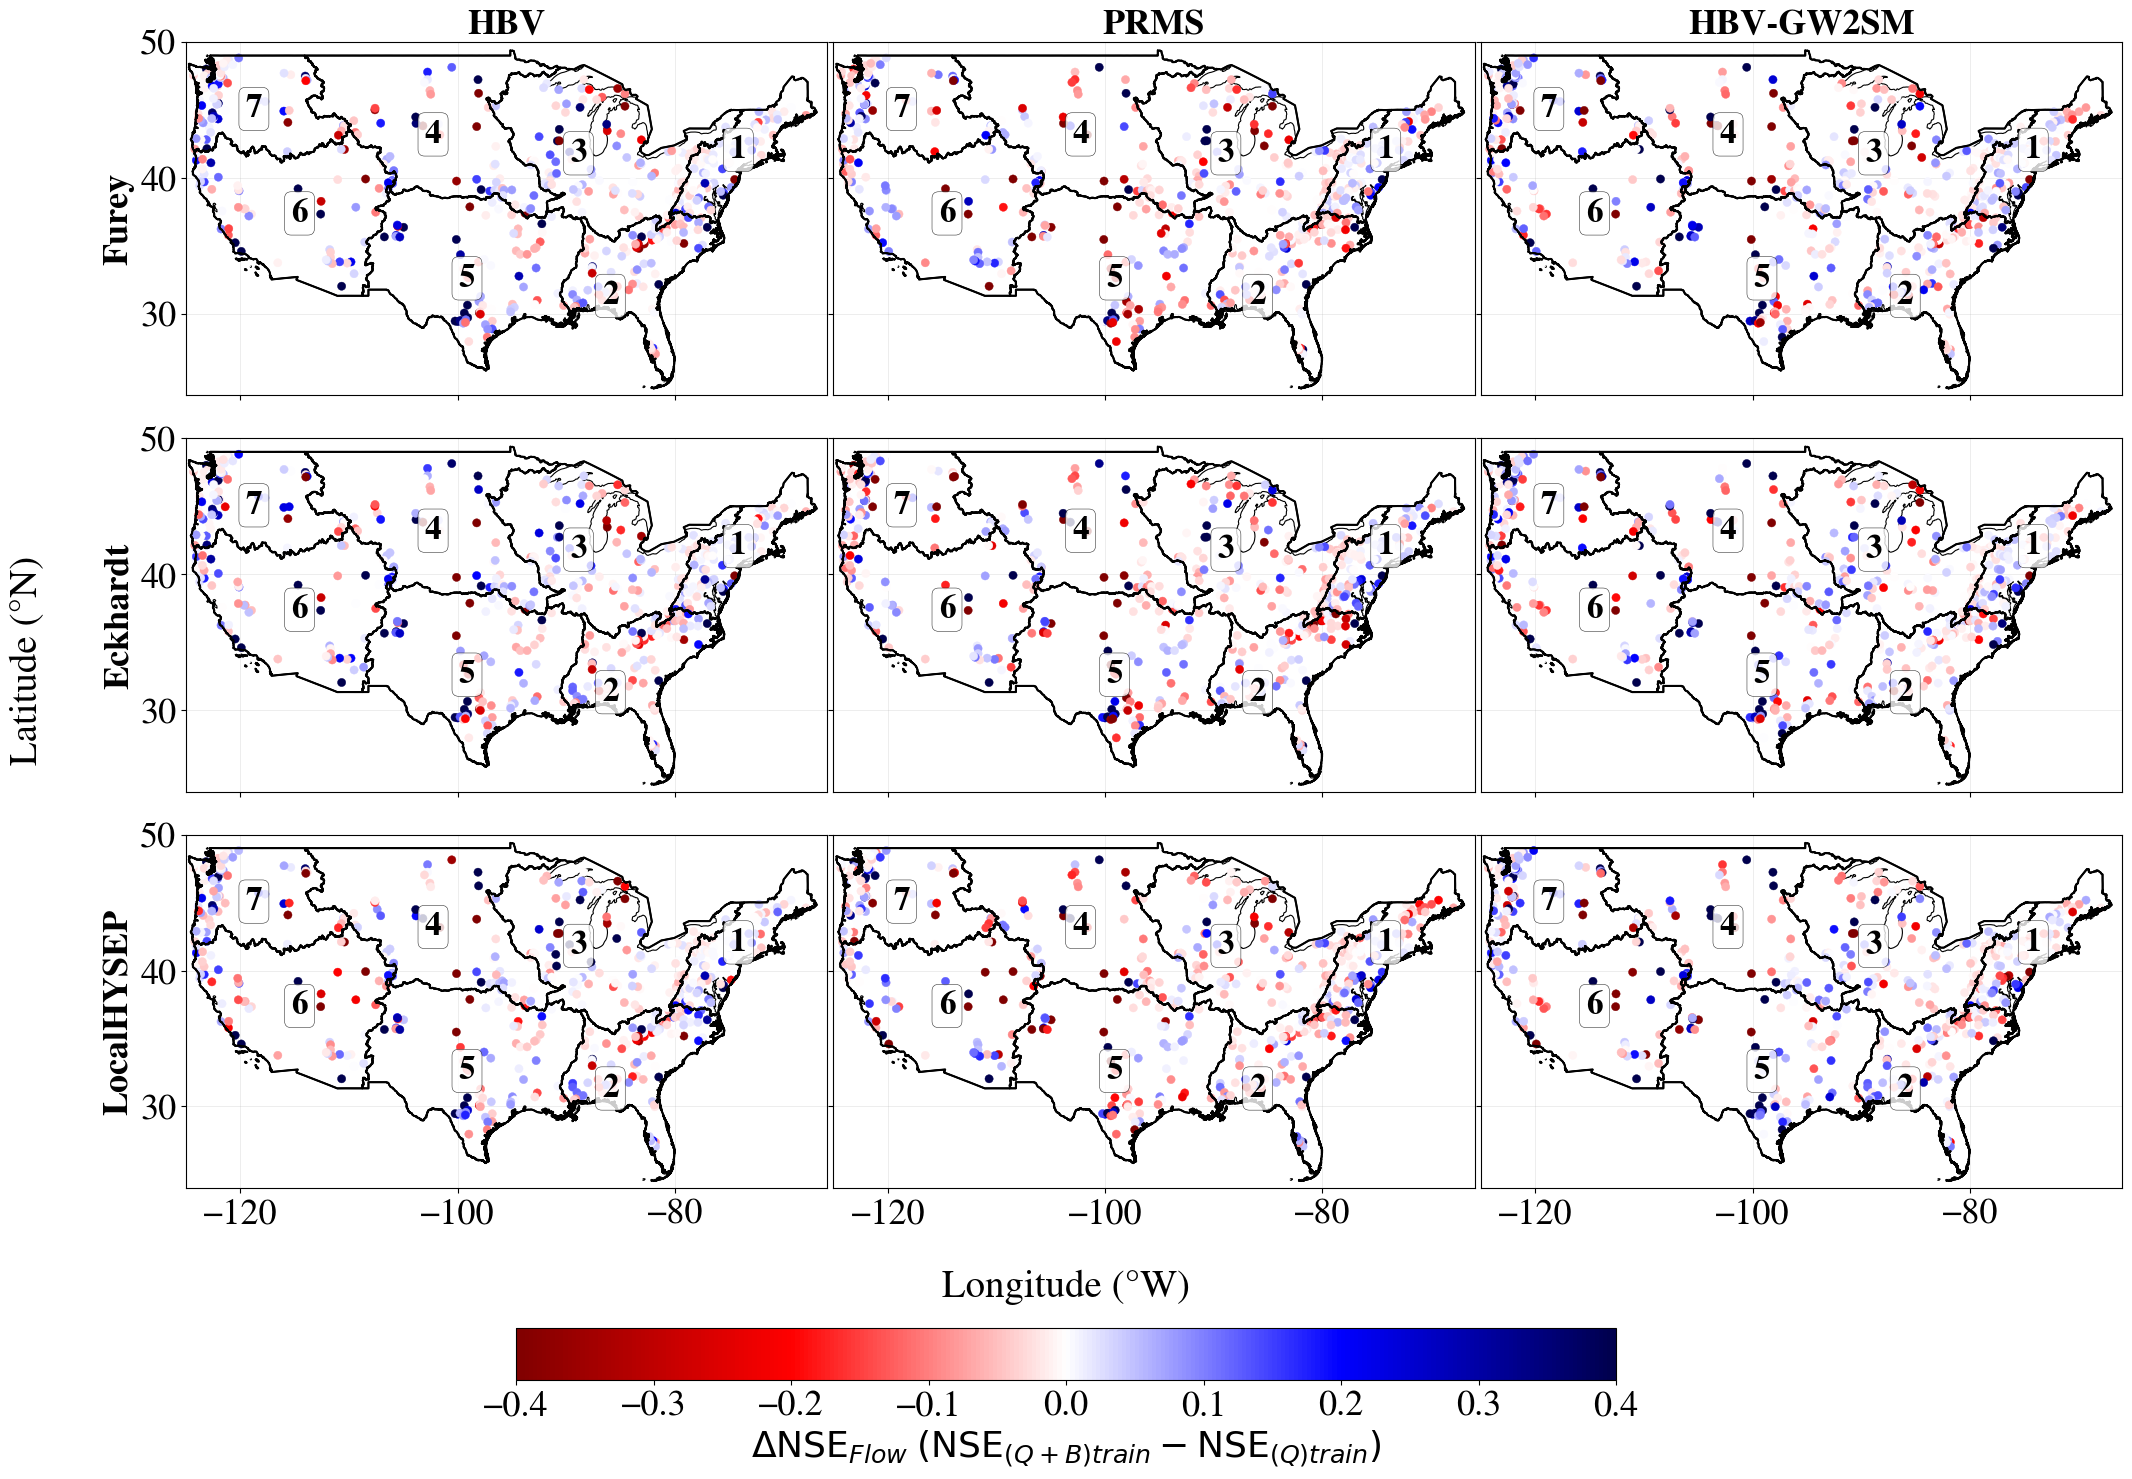

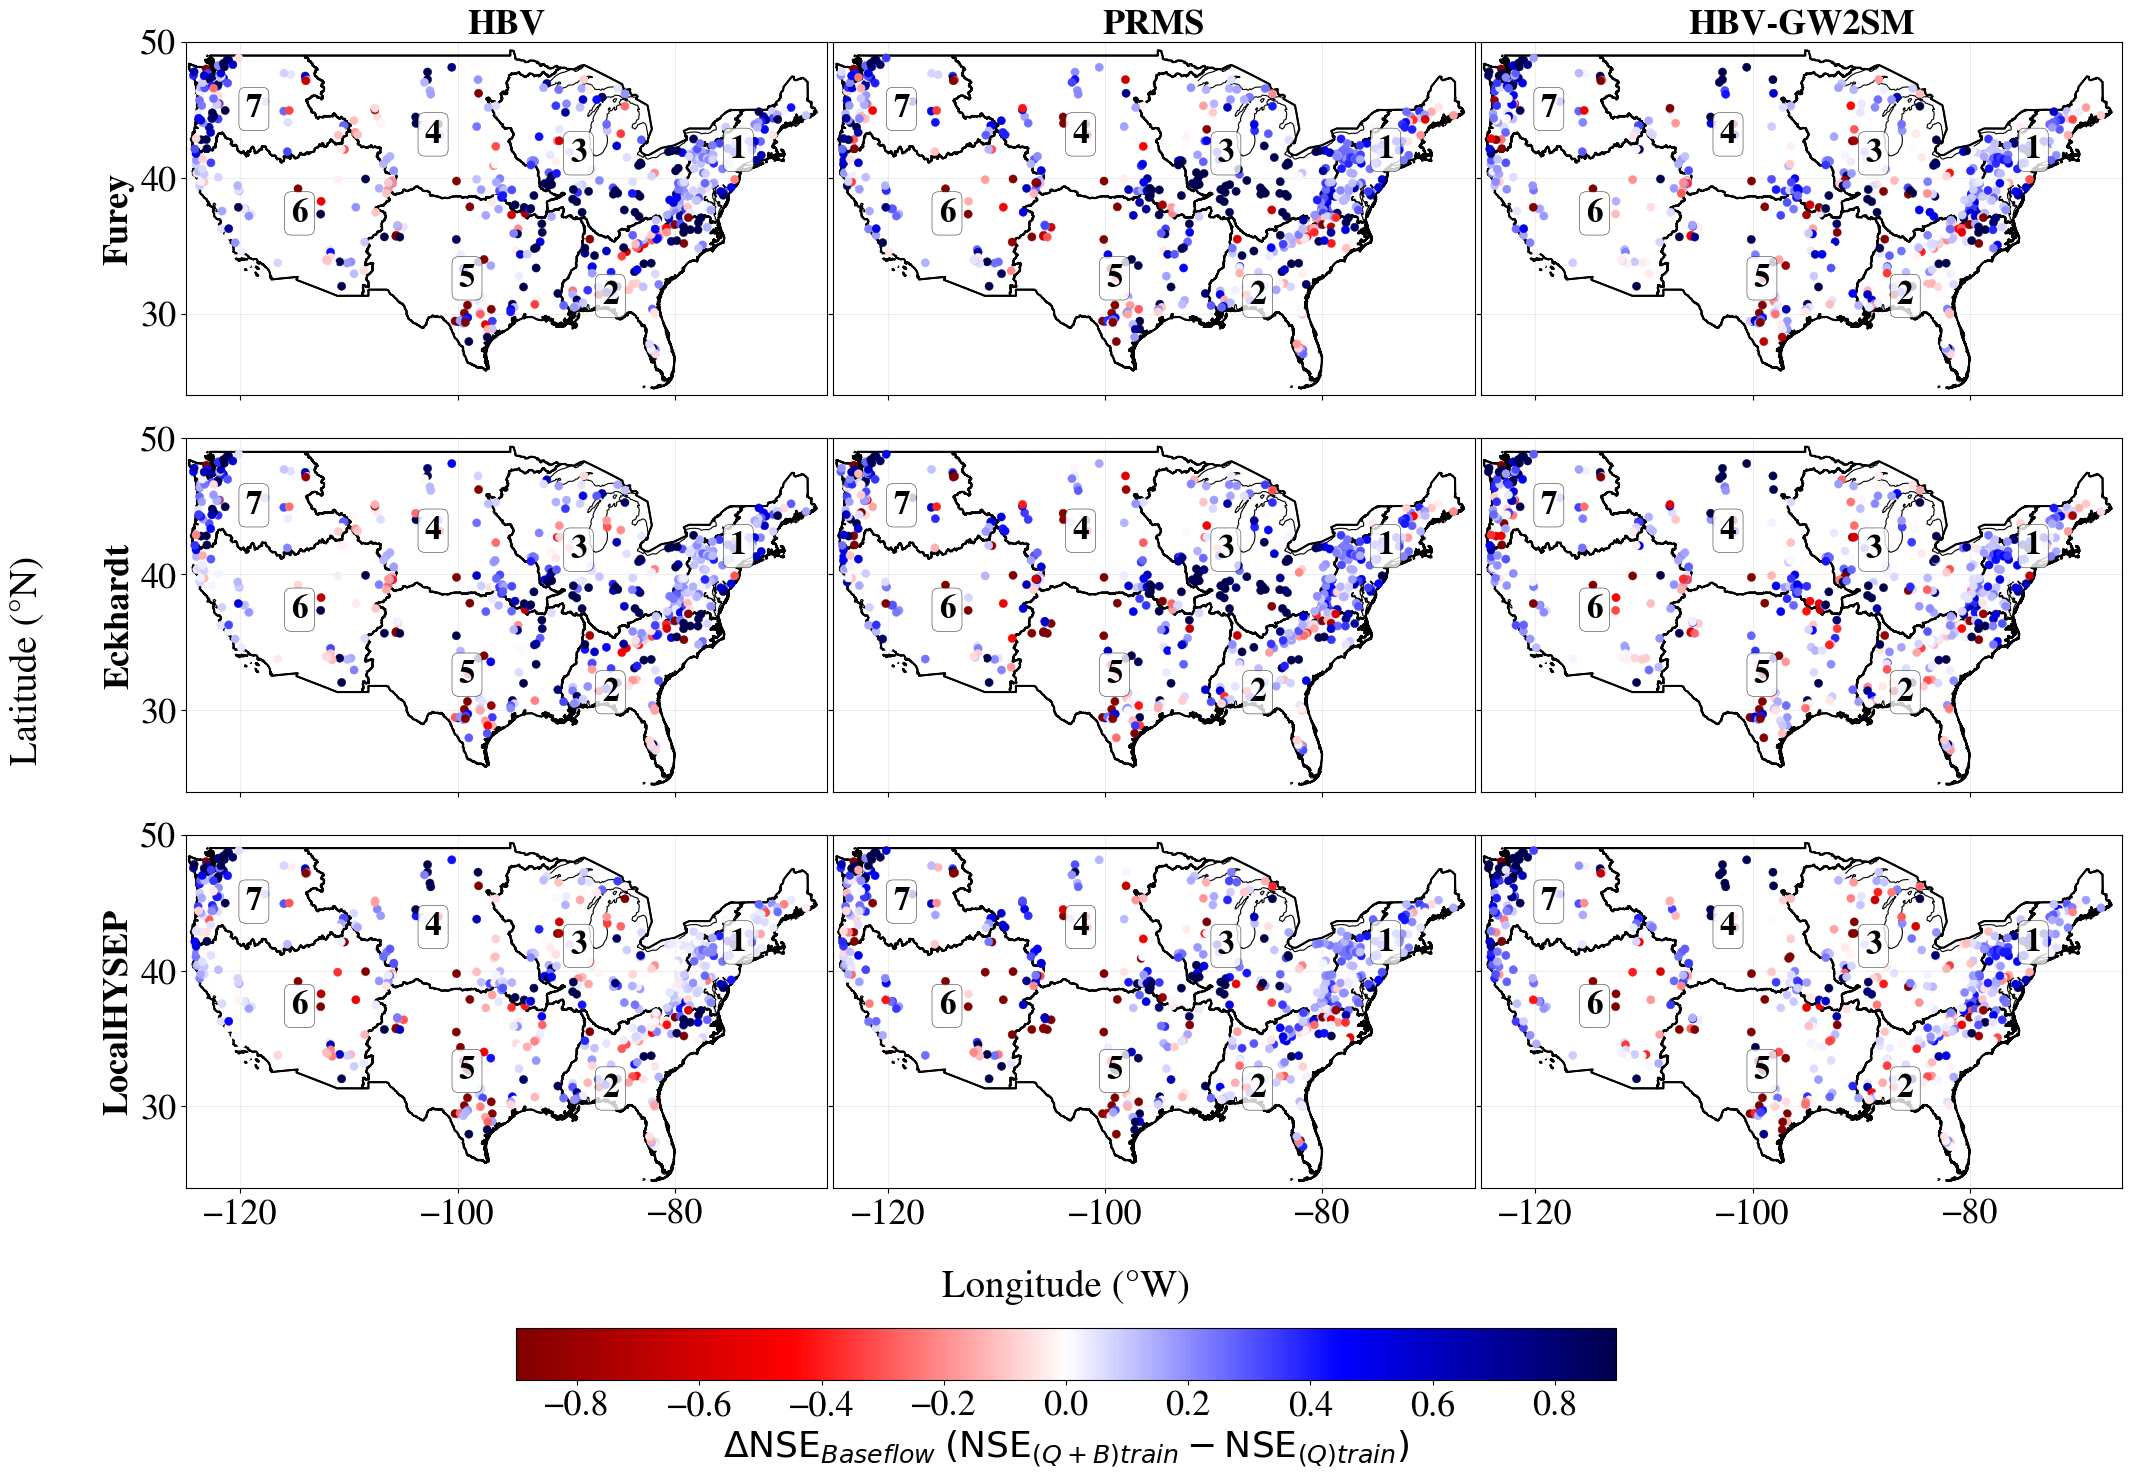

In [9]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box


loss= 'NSE'
# ============================================================
# FUNCTION TO PLOT PUR REGIONS AND REGION NUMBERS
# ============================================================

def add_pur_regions(ax, gdf_pur_regions):

    # Plot PUR region boundaries
    gdf_pur_regions.boundary.plot(
        ax=ax,
        edgecolor="black",
        linewidth=1.5,
        zorder=3
    )

    # Add region numbers
    for _, row in gdf_pur_regions.iterrows():

        label_point = row.geometry.representative_point()

        ax.text(
            label_point.x,
            label_point.y,
            f"{int(row['PUR_region'])}",
            fontsize=24,
            fontweight='bold',
            ha="center",
            va="center",
            color="black",
            zorder=5,
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                linewidth=0.4,
                alpha=0.8,
                boxstyle="round,pad=0.2"
            )
        )


plt.rcParams['font.family']= 'Nimbus Roman'

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)


# ============================================================
# PUR REGION DEFINITION FROM FENG ET AL.
# ============================================================

pur_groups = {
    1: ['01', '02'],
    2: ['03', '06'],
    3: ['04', '05', '07'],
    4: ['09', '10'],
    5: ['08', '11', '12', '13'],
    6: ['14', '15', '16', '18'],
    7: ['17']
}

# [ [1,2], [3,6], [4,5,7], [9,10], [8,11,12,13], [14,15,16,18], [17] ]

# ------------------------------------------------------------
# Make sure HUC2 codes are strings with leading zero
# ------------------------------------------------------------

gdf_huc2 = gpd.read_file("/home/s0shar47/scratch/huc_02/huc_02.shp")

print("HUC2 CRS before assignment:", gdf_huc2.crs)
print("HUC2 bounds before transformation:")
print(gdf_huc2.total_bounds)
gdf_huc2 = gdf_huc2.set_crs(
    "EPSG:26915"
)

print("HUC2 CRS after assignment:", gdf_huc2.crs)


# ============================================================
# TRANSFORM HUC2 TO WGS84
# ============================================================

gdf_huc2 = gdf_huc2.to_crs(
    "EPSG:4326"
)

print("HUC2 CRS after transformation:", gdf_huc2.crs)
print("HUC2 bounds after transformation:")
print(gdf_huc2.total_bounds)


# ============================================================
# CHECK HUC2 COLUMNS
# ============================================================

print("\nHUC2 columns:")
print(gdf_huc2.columns.tolist())


possible_huc_columns = [
    "HUC2",
    "HUC_2",
    "HUC2_CODE",
    "HUC_02",
    "HUC_02_",
    "HUC2_",
    "HUC"
]

huc_column = None

for col in possible_huc_columns:

    if col in gdf_huc2.columns:
        huc_column = col
        break

if huc_column is None:

    raise ValueError(
        "\nCould not identify the HUC2 column.\n"
        "Available columns are:\n"
        + str(gdf_huc2.columns.tolist())
    )

print("\nUsing HUC2 column:", huc_column)


# ============================================================
# STANDARDIZE HUC2 CODES
# ============================================================

gdf_huc2["HUC2_CODE"] = (
    gdf_huc2[huc_column]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
    .str.zfill(2)
)

print("\nHUC2 codes found:")
print(
    sorted(
        gdf_huc2["HUC2_CODE"].unique()
    )
)


# ============================================================
# CREATE HUC2 -> PUR REGION LOOKUP
# ============================================================

huc_to_region = {}

for region, hucs in pur_groups.items():

    for huc in hucs:

        huc_to_region[huc] = region


# ============================================================
# ASSIGN PUR REGION
# ============================================================

gdf_huc2["PUR_region"] = (
    gdf_huc2["HUC2_CODE"]
    .map(huc_to_region)
)


# Check whether any HUC2 was not assigned
unassigned = gdf_huc2[
    gdf_huc2["PUR_region"].isna()
]

if len(unassigned) > 0:

    print("\nWARNING:")
    print("The following HUC2 regions were not assigned:")
    print(
        unassigned["HUC2_CODE"]
        .tolist()
    )


# ============================================================
# KEEP PUR REGIONS
# ============================================================

gdf_pur = gdf_huc2.dropna(
    subset=["PUR_region"]
).copy()

gdf_pur["PUR_region"] = (
    gdf_pur["PUR_region"]
    .astype(int)
)


# ============================================================
# DISSOLVE HUC2 INTO PUR REGIONS
# ============================================================

gdf_pur_regions = (
    gdf_pur
    .dissolve(
        by="PUR_region"
    )
    .reset_index()
)


print("\n" + "=" * 70)
print("PUR REGION SUMMARY")
print("=" * 70)

print(
    gdf_pur_regions[
        ["PUR_region", "geometry"]
    ]
)


# ============================================================
# CREATE BASIN POINTS
# ============================================================

print("\n" + "=" * 70)
print("CREATING BASIN POINTS")
print("=" * 70)


## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'

# ============================================================
# CREATE BOTH 3 x 3 FIGURES BEFORE THE LOOPS
# ============================================================

fig_flow, axes_flow = plt.subplots(
    3, 3,
    figsize=(22, 15),
    sharex=True,
    sharey=True
)

fig_baseflow, axes_baseflow = plt.subplots(
    3, 3,
    figsize=(22, 15),
    sharex=True,
    sharey=True
)


# Keep scatter objects so we can create shared colorbars later
scatter_flow = None
scatter_baseflow = None


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================


for i,method in enumerate(methods):
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/Single/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/Single/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)


        ax = axes_flow[i, j]

        # CONUS boundary
        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )

        # --------------------------------------------
        # Delta Flow NSE
        # --------------------------------------------

        delta_flow_nse = (
            table['NSE-Flow (Multi-Objective)']
            - table['NSE-Flow (Single-Objective)']
        )

        scatter_flow = ax.scatter(
            table['lon'],
            table['lat'],
            marker='o',
            s=35,
            c=delta_flow_nse,
            cmap='seismic_r',
            vmin=-0.4,
            vmax=0.4,
            linewidth=0.3,
            zorder=2
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        gdf_pur_regions.boundary.plot(
                    ax=ax,
                    edgecolor="black",
                    linewidth=1.2,
                    zorder=3
                )
        if i == 0:
            # --------------------------------------------
            # Subplot title
            # --------------------------------------------
            ax.set_title(
                            f"{model_name}",
                            fontsize=26,
                            fontweight='bold'
                        )
            # ax.set_title(
            #     f"{method} | {model_name}",
            #     fontsize=13,
            #     fontweight='bold'
            # )

        if j== 0:

            ax.set_ylabel(f"{method}",
                            fontsize=26,
                            fontweight='bold')



        # --------------------------------------------
        # Map limits
        # --------------------------------------------

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        # --------------------------------------------
        # Grid
        # --------------------------------------------

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=26,
            which= 'major'
        )


        # ====================================================
        # FIGURE 2:
        # DELTA BASEFLOW NSE
        # ====================================================

        ax = axes_baseflow[i, j]

        # --------------------------------------------
        # CONUS boundary
        # --------------------------------------------

        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        # --------------------------------------------
        # PUR Region boundaries
        # --------------------------------------------

        gdf_pur_regions.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=1.2,
            zorder=3
        )

        # --------------------------------------------
        # Delta Baseflow NSE
        # --------------------------------------------

        delta_baseflow_nse = (
            table['NSE-Baseflow (Multi-Objective)']
            - table['NSE-Baseflow (Single-Objective)']
        )

        scatter_baseflow = ax.scatter(
            table['lon'],
            table['lat'],
            marker='o',
            s=35,
            c=delta_baseflow_nse,
            cmap='seismic_r',
            vmin=-0.9,
            vmax=0.9,
            linewidth=0.3,
            zorder=4
        )


        # --------------------------------------------
        # Subplot title
        # --------------------------------------------

        # ax.set_title(
        #     f"{method} | {model}",
        #     fontsize=13,
        #     fontweight='bold'
        # )

        # --------------------------------------------
        # Map limits
        # --------------------------------------------


        if i == 0:
                    # --------------------------------------------
                    # Subplot title
                    # --------------------------------------------
                    ax.set_title(
                                    f"{model_name}",
                                    fontsize=26,
                                    fontweight='bold'
                                )
                    # ax.set_title(
                    #     f"{method} | {model_name}",
                    #     fontsize=13,
                    #     fontweight='bold'
                    # )
        
        if j== 0:
        
                    ax.set_ylabel(f"{method}",
                                    fontsize=26,
                                    fontweight='bold')
        

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=26,
            which= 'major'
        )

        print(i, j, method, model)


# ============================================================
# FIGURE 1 FORMATTING
# DELTA FLOW NSE
# ============================================================

# fig_flow.suptitle(
#     "Change in Streamflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


# ------------------------------------------------------------
# Shared X/Y labels
# ------------------------------------------------------------

fig_flow.supxlabel(
    "Longitude (°W)",
    fontsize=28,
    y=0.07
)

fig_flow.supylabel(
    "Latitude (°N)",
    fontsize=28,
    x=0.02
)


# ------------------------------------------------------------
# Make room for colorbar
# ------------------------------------------------------------

fig_flow.subplots_adjust(
    left=0.1,
    right=0.98,
    top=0.92,
    bottom=0.14,
    wspace=0.01,
    hspace=0.05
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

cbar_ax_flow = fig_flow.add_axes([
    0.25,   # left
    0.02,   # bottom
    0.50,   # width
    0.035   # height
])

cbar_flow = fig_flow.colorbar(
    scatter_flow,
    cax=cbar_ax_flow,
    orientation='horizontal'
)

cbar_flow.set_label(
    r'$\Delta \mathrm{NSE}_{Flow}$ '
    r'$(\mathrm{NSE}_{(Q+B)train} - \mathrm{NSE}_{(Q)train})$',
    fontsize=26
)

cbar_flow.ax.tick_params(
    labelsize=26
)


# ============================================================
# FIGURE 2 FORMATTING
# DELTA BASEFLOW NSE
# ============================================================

# fig_baseflow.suptitle(
#     "Change in Baseflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


fig_baseflow.supxlabel(
    "Longitude (°W)",
    fontsize=28,
    y=0.07
)

fig_baseflow.supylabel(
    "Latitude (°N)",
    fontsize=28,
    x=0.02
)


fig_baseflow.subplots_adjust(
    left=0.1,
    right=0.98,
    top=0.92,
    bottom=0.14,
    wspace=0.01,
    hspace=0.05
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

cbar_ax_baseflow = fig_baseflow.add_axes([
    0.25,
    0.02,
    0.50,
    0.035
])

cbar_baseflow = fig_baseflow.colorbar(
    scatter_baseflow,
    cax=cbar_ax_baseflow,
    orientation='horizontal'
)

cbar_baseflow.set_label(
    r'$\Delta \mathrm{NSE}_{Baseflow}$ '
    r'$(\mathrm{NSE}_{(Q+B)train} - \mathrm{NSE}_{(Q)train})$',
    fontsize=26
)

cbar_baseflow.ax.tick_params(
    labelsize=26
)

output_dir = "/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures_NSE/"

########################################################################
fig_flow.savefig(
    f"{output_dir}/{loss}_loss_Delta_Flow_NSE_3x3.jpg",
    dpi=400,
    bbox_inches="tight"
)

########################################################################
fig_baseflow.savefig(
    f"{output_dir}/{loss}_loss_Delta_Baseflow_NSE_3x3.jpg",
    dpi=400,
    bbox_inches="tight"
)
# # ============================================================
# SHOW ONLY AFTER ALL 9 SUBPLOTS HAVE BEEN CREATED
# ============================================================
plt.show()

HUC2 CRS before assignment: None
HUC2 bounds before transformation:
[-7783576.02289802  2187575.63815253  3619690.05690435 10257816.27458091]
HUC2 CRS after assignment: EPSG:26915
HUC2 CRS after transformation: EPSG:4326
HUC2 bounds after transformation:
[-179.96928239   17.67456073  179.91556688   71.39676244]

HUC2 columns:
['HUC2', 'COUNT', 'REG_NAME', 'ACRES', 'geometry']

Using HUC2 column: HUC2

HUC2 codes found:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']

The following HUC2 regions were not assigned:
['19', '20', '21']

PUR REGION SUMMARY
   PUR_region                                           geometry
0           1  MULTIPOLYGON (((-75.90469 37.11406, -75.91338 ...
1           2  MULTIPOLYGON (((-83.07339 29.09564, -83.07442 ...
2           3  MULTIPOLYGON (((-77.85699 41.82669, -77.85942 ...
3           4  POLYGON ((-105.67422 40.27259, -105.6871 40.28...
4           5  MULTIPOLYGON (((-97.2193

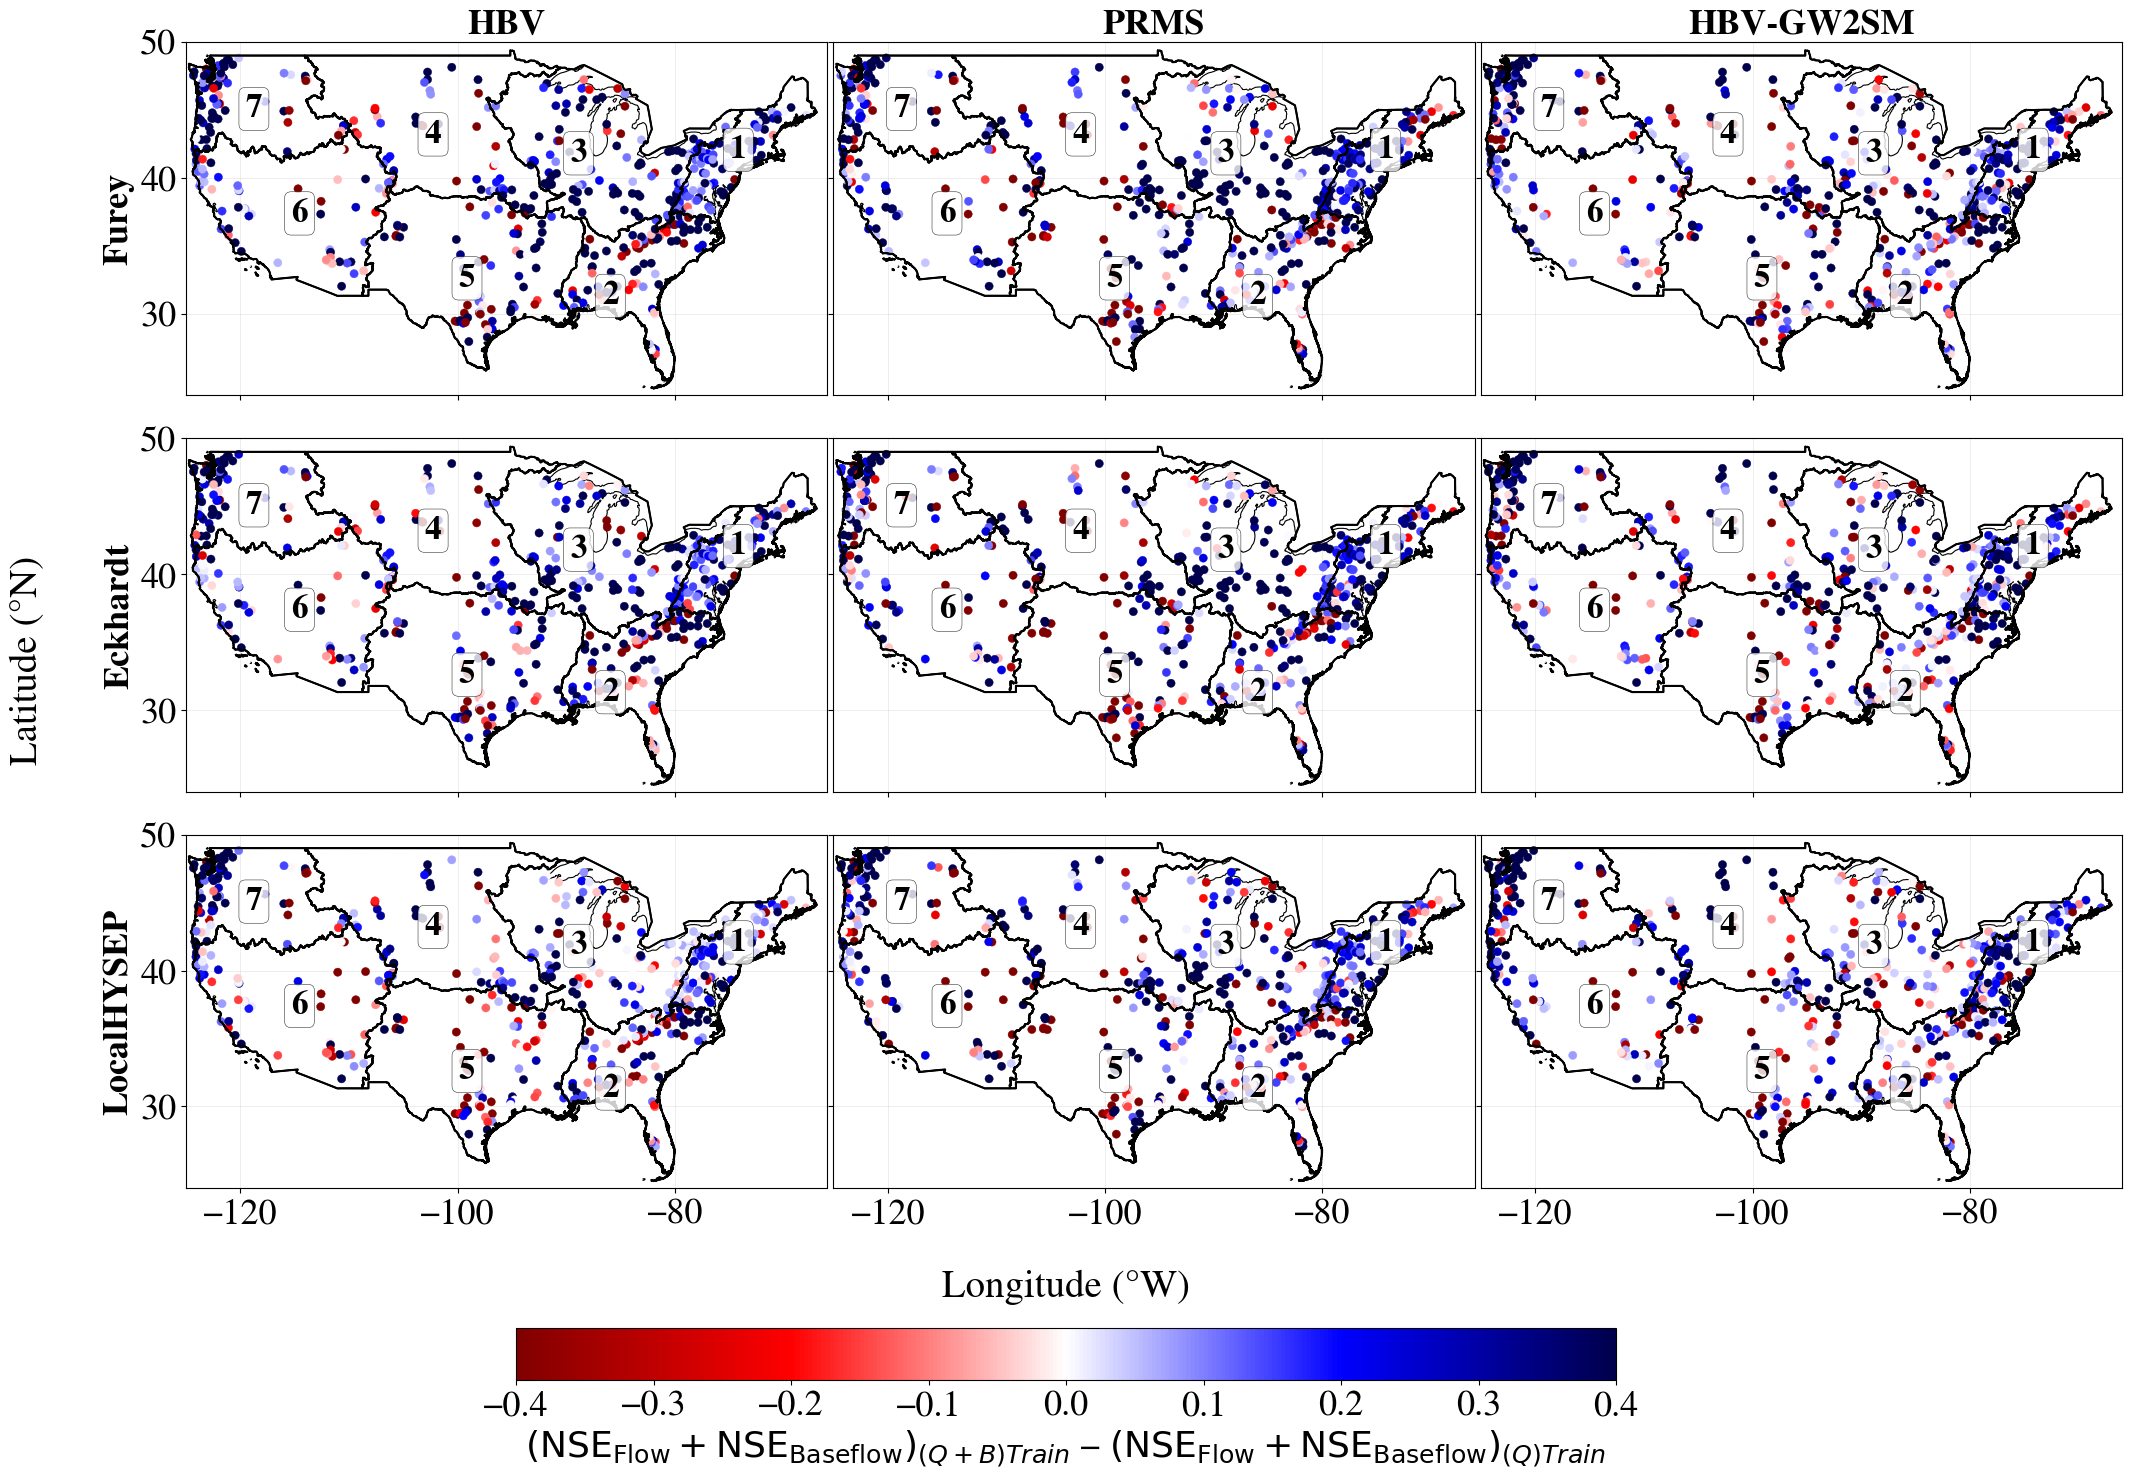

In [63]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box


loss= 'NSE'
# ============================================================
# FUNCTION TO PLOT PUR REGIONS AND REGION NUMBERS
# ============================================================

def add_pur_regions(ax, gdf_pur_regions):

    # Plot PUR region boundaries
    gdf_pur_regions.boundary.plot(
        ax=ax,
        edgecolor="black",
        linewidth=1.5,
        zorder=3
    )

    # Add region numbers
    for _, row in gdf_pur_regions.iterrows():

        label_point = row.geometry.representative_point()

        ax.text(
            label_point.x,
            label_point.y,
            f"{int(row['PUR_region'])}",
            fontsize=24,
            fontweight='bold',
            ha="center",
            va="center",
            color="black",
            zorder=5,
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                linewidth=0.4,
                alpha=0.8,
                boxstyle="round,pad=0.2"
            )
        )


plt.rcParams['font.family']= 'Nimbus Roman'

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)


# ============================================================
# PUR REGION DEFINITION FROM FENG ET AL.
# ============================================================

pur_groups = {
    1: ['01', '02'],
    2: ['03', '06'],
    3: ['04', '05', '07'],
    4: ['09', '10'],
    5: ['08', '11', '12', '13'],
    6: ['14', '15', '16', '18'],
    7: ['17']
}

# [ [1,2], [3,6], [4,5,7], [9,10], [8,11,12,13], [14,15,16,18], [17] ]

# ------------------------------------------------------------
# Make sure HUC2 codes are strings with leading zero
# ------------------------------------------------------------

gdf_huc2 = gpd.read_file("/home/s0shar47/scratch/huc_02/huc_02.shp")

print("HUC2 CRS before assignment:", gdf_huc2.crs)
print("HUC2 bounds before transformation:")
print(gdf_huc2.total_bounds)
gdf_huc2 = gdf_huc2.set_crs(
    "EPSG:26915"
)

print("HUC2 CRS after assignment:", gdf_huc2.crs)


# ============================================================
# TRANSFORM HUC2 TO WGS84
# ============================================================

gdf_huc2 = gdf_huc2.to_crs(
    "EPSG:4326"
)

print("HUC2 CRS after transformation:", gdf_huc2.crs)
print("HUC2 bounds after transformation:")
print(gdf_huc2.total_bounds)


# ============================================================
# CHECK HUC2 COLUMNS
# ============================================================

print("\nHUC2 columns:")
print(gdf_huc2.columns.tolist())


possible_huc_columns = [
    "HUC2",
    "HUC_2",
    "HUC2_CODE",
    "HUC_02",
    "HUC_02_",
    "HUC2_",
    "HUC"
]

huc_column = None

for col in possible_huc_columns:

    if col in gdf_huc2.columns:
        huc_column = col
        break

if huc_column is None:

    raise ValueError(
        "\nCould not identify the HUC2 column.\n"
        "Available columns are:\n"
        + str(gdf_huc2.columns.tolist())
    )

print("\nUsing HUC2 column:", huc_column)


# ============================================================
# STANDARDIZE HUC2 CODES
# ============================================================

gdf_huc2["HUC2_CODE"] = (
    gdf_huc2[huc_column]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
    .str.zfill(2)
)

print("\nHUC2 codes found:")
print(
    sorted(
        gdf_huc2["HUC2_CODE"].unique()
    )
)


# ============================================================
# CREATE HUC2 -> PUR REGION LOOKUP
# ============================================================

huc_to_region = {}

for region, hucs in pur_groups.items():

    for huc in hucs:

        huc_to_region[huc] = region


# ============================================================
# ASSIGN PUR REGION
# ============================================================

gdf_huc2["PUR_region"] = (
    gdf_huc2["HUC2_CODE"]
    .map(huc_to_region)
)


# Check whether any HUC2 was not assigned
unassigned = gdf_huc2[
    gdf_huc2["PUR_region"].isna()
]

if len(unassigned) > 0:

    print("\nWARNING:")
    print("The following HUC2 regions were not assigned:")
    print(
        unassigned["HUC2_CODE"]
        .tolist()
    )


# ============================================================
# KEEP PUR REGIONS
# ============================================================

gdf_pur = gdf_huc2.dropna(
    subset=["PUR_region"]
).copy()

gdf_pur["PUR_region"] = (
    gdf_pur["PUR_region"]
    .astype(int)
)


# ============================================================
# DISSOLVE HUC2 INTO PUR REGIONS
# ============================================================

gdf_pur_regions = (
    gdf_pur
    .dissolve(
        by="PUR_region"
    )
    .reset_index()
)


print("\n" + "=" * 70)
print("PUR REGION SUMMARY")
print("=" * 70)

print(
    gdf_pur_regions[
        ["PUR_region", "geometry"]
    ]
)


# ============================================================
# CREATE BASIN POINTS
# ============================================================

print("\n" + "=" * 70)
print("CREATING BASIN POINTS")
print("=" * 70)


## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'

# ============================================================
# CREATE BOTH 3 x 3 FIGURES BEFORE THE LOOPS
# ============================================================

fig_flow, axes_flow = plt.subplots(
    3, 3,
    figsize=(22, 15),
    sharex=True,
    sharey=True
)

scatter_flow = None


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================


for i,method in enumerate(methods):
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/Single/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/Single/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)
        table['NSEsum(Qtrain)']= table['NSE-Flow (Single-Objective)']+ table['NSE-Baseflow (Single-Objective)']
        table['NSEsum(Q+Btrain)']= table['NSE-Flow (Multi-Objective)']+ table['NSE-Baseflow (Multi-Objective)']


        ax = axes_flow[i, j]

        # CONUS boundary
        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )

        # --------------------------------------------
        # Delta Flow NSE
        # --------------------------------------------

        delta_flow_nse = (
            table['NSEsum(Q+Btrain)']
            - table['NSEsum(Qtrain)']
        )

        scatter_flow = ax.scatter(
            table['lon'],
            table['lat'],
            marker='o',
            s=35,
            c=delta_flow_nse,
            cmap='seismic_r',
            vmin=-0.4,
            vmax=0.4,
            linewidth=0.3,
            zorder=2
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        gdf_pur_regions.boundary.plot(
                    ax=ax,
                    edgecolor="black",
                    linewidth=1.2,
                    zorder=3
                )
        if i == 0:
            # --------------------------------------------
            # Subplot title
            # --------------------------------------------
            ax.set_title(
                            f"{model_name}",
                            fontsize=26,
                            fontweight='bold'
                        )
            # ax.set_title(
            #     f"{method} | {model_name}",
            #     fontsize=13,
            #     fontweight='bold'
            # )

        if j== 0:

            ax.set_ylabel(f"{method}",
                            fontsize=26,
                            fontweight='bold')



        # --------------------------------------------
        # Map limits
        # --------------------------------------------

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        # --------------------------------------------
        # Grid
        # --------------------------------------------

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=26,
            which= 'major'
        )

fig_flow.supxlabel(
    "Longitude (°W)",
    fontsize=28,
    y=0.07
)

fig_flow.supylabel(
    "Latitude (°N)",
    fontsize=28,
    x=0.02
)


# ------------------------------------------------------------
# Make room for colorbar
# ------------------------------------------------------------

fig_flow.subplots_adjust(
    left=0.1,
    right=0.98,
    top=0.92,
    bottom=0.14,
    wspace=0.01,
    hspace=0.05
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

cbar_ax_flow = fig_flow.add_axes([
    0.25,   # left
    0.02,   # bottom
    0.50,   # width
    0.035   # height
])

cbar_flow = fig_flow.colorbar(
    scatter_flow,
    cax=cbar_ax_flow,
    orientation='horizontal'
)

# cbar_flow.set_label(
#     r'$\Delta  \mathrm{NSE}_{Flow}+\mathrm{NSE}_{Baseflow}$ '
#     r'$(\mathrm{NSE}_{(Q+B)Train} - \mathrm{NSE}_{(Q)Train})$',
#     fontsize=26
# )

cbar_flow.set_label(
    r'$\mathrm{(\mathrm{NSE}_{Flow} + \mathrm{NSE}_{Baseflow})}_{(Q+B)Train}$ − '

    r'$\mathrm{(\mathrm{NSE}_{Flow} + \mathrm{NSE}_{Baseflow})}_{(Q)Train}$'
    ,fontsize=26
)

# cbar_flow.set_label(
#     r'$\mathrm{(NSE_{Flow} + NSE_{Baseflow})}_{\mathrm{Q+B},\,\text{Train}}$',
#     fontsize=26
# )

cbar_flow.ax.tick_params(
    labelsize=26
)

plt.show()


HUC2 CRS before assignment: None
HUC2 bounds before transformation:
[-7783576.02289802  2187575.63815253  3619690.05690435 10257816.27458091]
HUC2 CRS after assignment: EPSG:26915
HUC2 CRS after transformation: EPSG:4326
HUC2 bounds after transformation:
[-179.96928239   17.67456073  179.91556688   71.39676244]

HUC2 columns:
['HUC2', 'COUNT', 'REG_NAME', 'ACRES', 'geometry']

Using HUC2 column: HUC2

HUC2 codes found:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']

The following HUC2 regions were not assigned:
['19', '20', '21']

PUR REGION SUMMARY
   PUR_region                                           geometry
0           1  MULTIPOLYGON (((-75.90469 37.11406, -75.91338 ...
1           2  MULTIPOLYGON (((-83.07339 29.09564, -83.07442 ...
2           3  MULTIPOLYGON (((-77.85699 41.82669, -77.85942 ...
3           4  POLYGON ((-105.67422 40.27259, -105.6871 40.28...
4           5  MULTIPOLYGON (((-97.2193

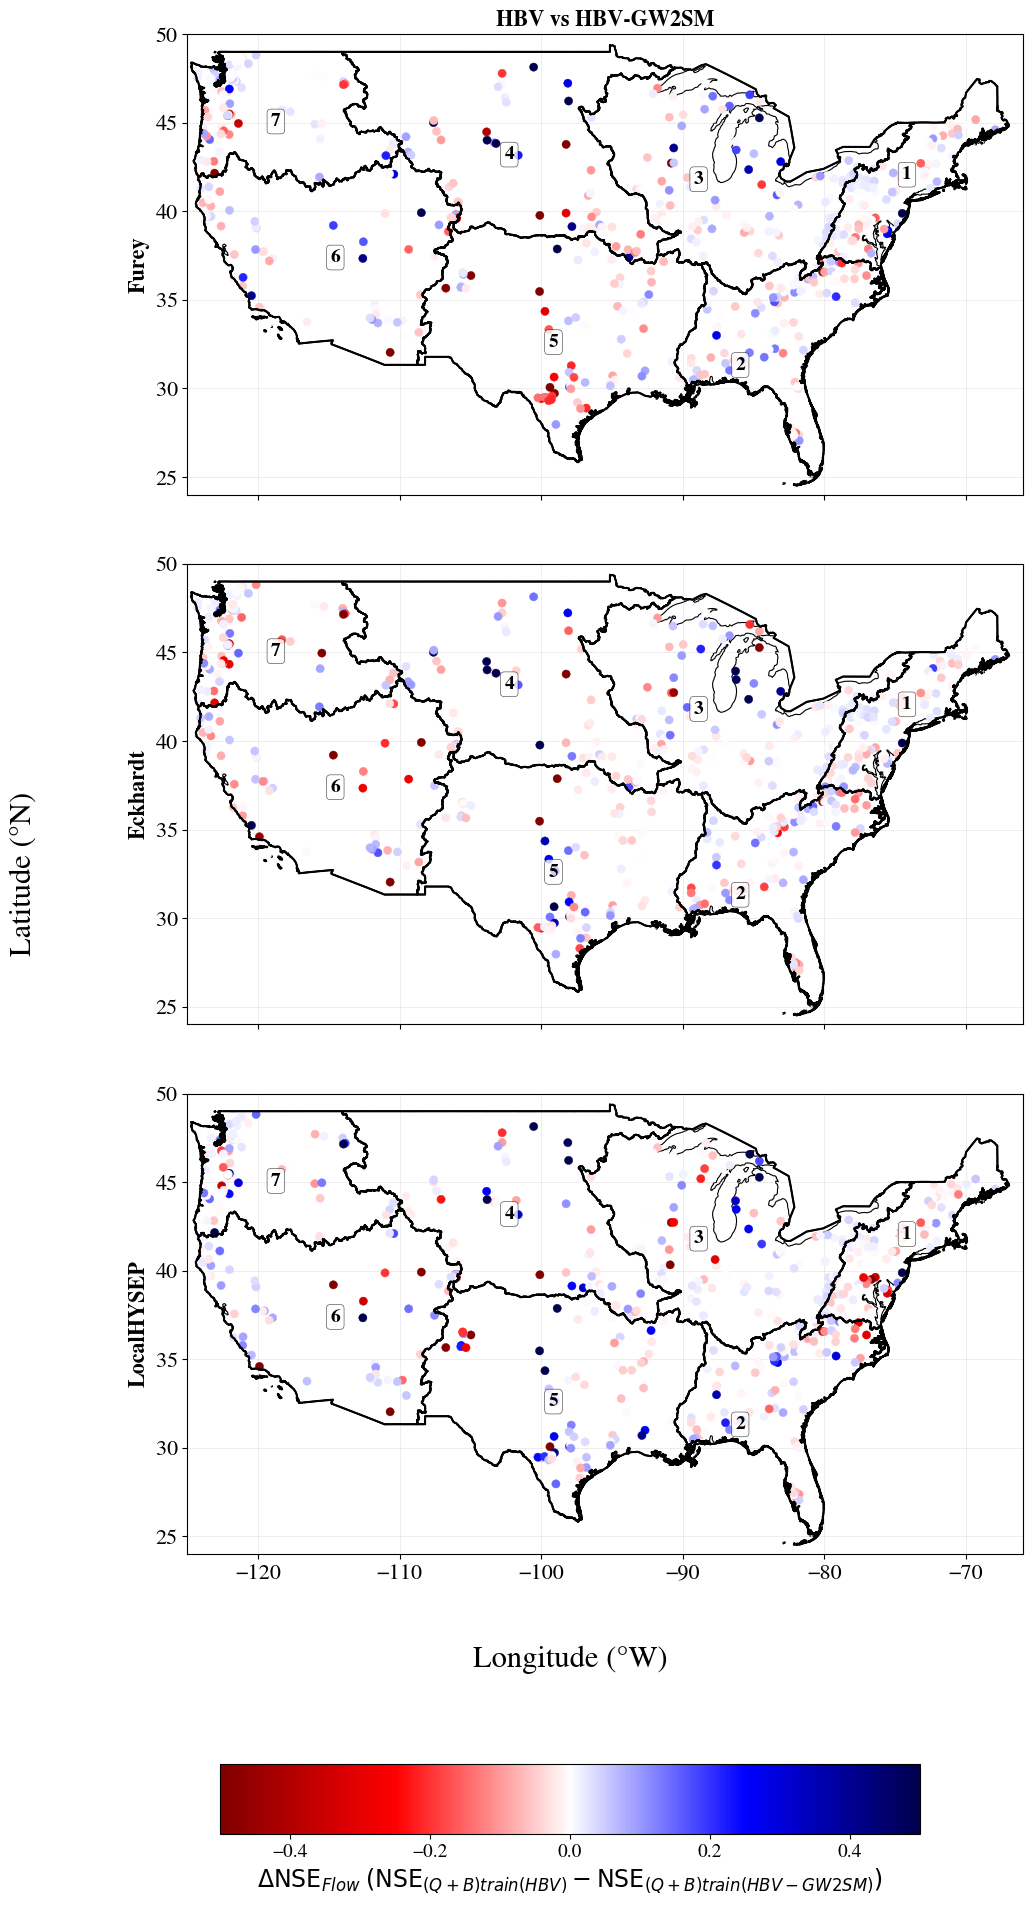

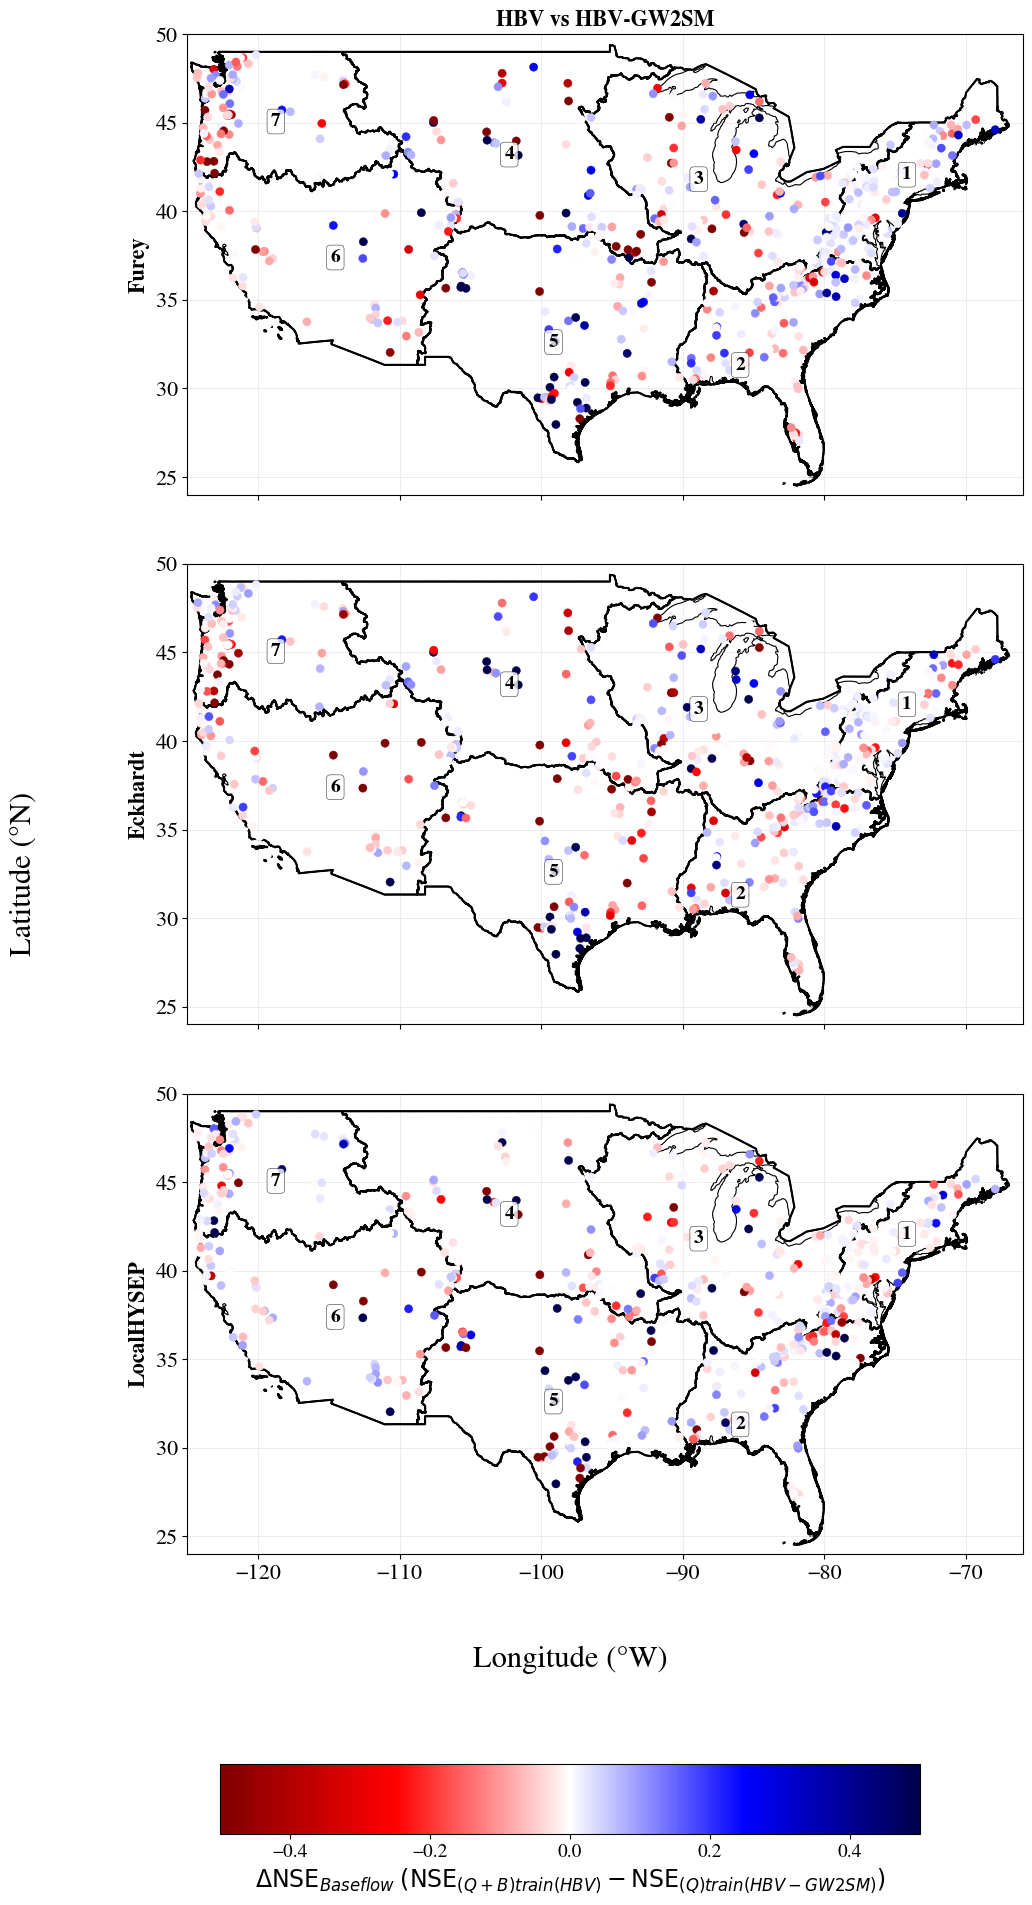

In [31]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

# ============================================================
# FUNCTION TO PLOT PUR REGIONS AND REGION NUMBERS
# ============================================================

def add_pur_regions(ax, gdf_pur_regions):

    # Plot PUR region boundaries
    gdf_pur_regions.boundary.plot(
        ax=ax,
        edgecolor="black",
        linewidth=1.5,
        zorder=3
    )

    # Add region numbers
    for _, row in gdf_pur_regions.iterrows():

        label_point = row.geometry.representative_point()

        ax.text(
            label_point.x,
            label_point.y,
            f"{int(row['PUR_region'])}",
            fontsize=14,
            fontweight='bold',
            ha="center",
            va="center",
            color="black",
            zorder=5,
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                linewidth=0.4,
                alpha=0.8,
                boxstyle="round,pad=0.2"
            )
        )


plt.rcParams['font.family']= 'Nimbus Roman'

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)


# ============================================================
# PUR REGION DEFINITION FROM FENG ET AL.
# ============================================================

pur_groups = {
    1: ['01', '02'],
    2: ['03', '06'],
    3: ['04', '05', '07'],
    4: ['09', '10'],
    5: ['08', '11', '12', '13'],
    6: ['14', '15', '16', '18'],
    7: ['17']
}

# [ [1,2], [3,6], [4,5,7], [9,10], [8,11,12,13], [14,15,16,18], [17] ]

# ------------------------------------------------------------
# Make sure HUC2 codes are strings with leading zero
# ------------------------------------------------------------

gdf_huc2 = gpd.read_file("/home/s0shar47/scratch/huc_02/huc_02.shp")

print("HUC2 CRS before assignment:", gdf_huc2.crs)
print("HUC2 bounds before transformation:")
print(gdf_huc2.total_bounds)
gdf_huc2 = gdf_huc2.set_crs(
    "EPSG:26915"
)

print("HUC2 CRS after assignment:", gdf_huc2.crs)


# ============================================================
# TRANSFORM HUC2 TO WGS84
# ============================================================

gdf_huc2 = gdf_huc2.to_crs(
    "EPSG:4326"
)

print("HUC2 CRS after transformation:", gdf_huc2.crs)
print("HUC2 bounds after transformation:")
print(gdf_huc2.total_bounds)


# ============================================================
# CHECK HUC2 COLUMNS
# ============================================================

print("\nHUC2 columns:")
print(gdf_huc2.columns.tolist())


possible_huc_columns = [
    "HUC2",
    "HUC_2",
    "HUC2_CODE",
    "HUC_02",
    "HUC_02_",
    "HUC2_",
    "HUC"
]

huc_column = None

for col in possible_huc_columns:

    if col in gdf_huc2.columns:
        huc_column = col
        break

if huc_column is None:

    raise ValueError(
        "\nCould not identify the HUC2 column.\n"
        "Available columns are:\n"
        + str(gdf_huc2.columns.tolist())
    )

print("\nUsing HUC2 column:", huc_column)


# ============================================================
# STANDARDIZE HUC2 CODES
# ============================================================

gdf_huc2["HUC2_CODE"] = (
    gdf_huc2[huc_column]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
    .str.zfill(2)
)

print("\nHUC2 codes found:")
print(
    sorted(
        gdf_huc2["HUC2_CODE"].unique()
    )
)


# ============================================================
# CREATE HUC2 -> PUR REGION LOOKUP
# ============================================================

huc_to_region = {}

for region, hucs in pur_groups.items():

    for huc in hucs:

        huc_to_region[huc] = region


# ============================================================
# ASSIGN PUR REGION
# ============================================================

gdf_huc2["PUR_region"] = (
    gdf_huc2["HUC2_CODE"]
    .map(huc_to_region)
)


# Check whether any HUC2 was not assigned
unassigned = gdf_huc2[
    gdf_huc2["PUR_region"].isna()
]

if len(unassigned) > 0:

    print("\nWARNING:")
    print("The following HUC2 regions were not assigned:")
    print(
        unassigned["HUC2_CODE"]
        .tolist()
    )


# ============================================================
# KEEP PUR REGIONS
# ============================================================

gdf_pur = gdf_huc2.dropna(
    subset=["PUR_region"]
).copy()

gdf_pur["PUR_region"] = (
    gdf_pur["PUR_region"]
    .astype(int)
)


# ============================================================
# DISSOLVE HUC2 INTO PUR REGIONS
# ============================================================

gdf_pur_regions = (
    gdf_pur
    .dissolve(
        by="PUR_region"
    )
    .reset_index()
)


print("\n" + "=" * 70)
print("PUR REGION SUMMARY")
print("=" * 70)

print(
    gdf_pur_regions[
        ["PUR_region", "geometry"]
    ]
)


# ============================================================
# CREATE BASIN POINTS
# ============================================================

print("\n" + "=" * 70)
print("CREATING BASIN POINTS")
print("=" * 70)


## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
# models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']
models= ['HBV']



if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'

# ============================================================
# CREATE BOTH 3 x 1 FIGURES BEFORE THE LOOPS
# ============================================================

fig_flow, axes_flow = plt.subplots(
    3, 1,
    figsize=(14, 20),
    sharex=True,
    sharey=True
)

fig_baseflow, axes_baseflow = plt.subplots(
    3, 1,
    figsize=(14, 20),
    sharex=True,
    sharey=True
)

scatter_flow = None
scatter_baseflow = None

# ============================================================
# YOUR 3 x 1 LOOPS
# ============================================================


for i,method in enumerate(methods):
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/HBV_capillary/{region}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/HBV_capillary/{region}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)


        # ax = axes_flow[i, j]
        ax = axes_flow[i]

        # CONUS boundary
        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )

        # --------------------------------------------
        # Delta Flow NSE
        # --------------------------------------------

        delta_flow_nse = (
            table['NSE-Flow (Multi-Objective)']
            - table['NSE-Flow (Single-Objective)']
        )

        scatter_flow = ax.scatter(
            table['lon'],
            table['lat'],
            marker='o',
            s=35,
            c=delta_flow_nse,
            cmap='seismic_r',
            vmin=-0.5,
            vmax=0.5,
            linewidth=0.3,
            zorder=2
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        gdf_pur_regions.boundary.plot(
                    ax=ax,
                    edgecolor="black",
                    linewidth=1.2,
                    zorder=3
                )
        if i == 0:
            # --------------------------------------------
            # Subplot title
            # --------------------------------------------
            ax.set_title(
                            f"{model_name} vs HBV-GW2SM",
                            fontsize=16,
                            fontweight='bold'
                        )
            # ax.set_title(
            #     f"{method} | {model_name}",
            #     fontsize=13,
            #     fontweight='bold'
            # )

        if j== 0:

            ax.set_ylabel(f"{method}",
                            fontsize=16,
                            fontweight='bold')



        # --------------------------------------------
        # Map limits
        # --------------------------------------------

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        # --------------------------------------------
        # Grid
        # --------------------------------------------

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=16,
            which= 'major'
        )


        # ====================================================
        # FIGURE 2:
        # DELTA BASEFLOW NSE
        # ====================================================

        # ax = axes_baseflow[i, j]
        ax = axes_baseflow[i]

        # --------------------------------------------
        # CONUS boundary
        # --------------------------------------------

        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        # --------------------------------------------
        # PUR Region boundaries
        # --------------------------------------------

        gdf_pur_regions.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=1.2,
            zorder=3
        )

        # --------------------------------------------
        # Delta Baseflow NSE
        # --------------------------------------------

        delta_baseflow_nse = (
            table['NSE-Baseflow (Multi-Objective)']
            - table['NSE-Baseflow (Single-Objective)']
        )

        scatter_baseflow = ax.scatter(
            table['lon'],
            table['lat'],
            marker='o',
            s=35,
            c=delta_baseflow_nse,
            cmap='seismic_r',
            vmin=-0.5,
            vmax=0.5,
            linewidth=0.3,
            zorder=4
        )


        # --------------------------------------------
        # Subplot title
        # --------------------------------------------

        # ax.set_title(
        #     f"{method} | {model}",
        #     fontsize=13,
        #     fontweight='bold'
        # )

        # --------------------------------------------
        # Map limits
        # --------------------------------------------


        if i == 0:
                    # --------------------------------------------
                    # Subplot title
                    # --------------------------------------------
                    ax.set_title(
                                    f"{model_name} vs HBV-GW2SM",
                                    fontsize=16,
                                    fontweight='bold'
                                )
                    # ax.set_title(
                    #     f"{method} | {model_name}",
                    #     fontsize=13,
                    #     fontweight='bold'
                    # )
        
        if j== 0:
        
                    ax.set_ylabel(f"{method}",
                                    fontsize=16,
                                    fontweight='bold')
        

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=16,
            which= 'major'
        )

        print(i, j, method, model)


# ============================================================
# FIGURE 1 FORMATTING
# DELTA FLOW NSE
# ============================================================

# fig_flow.suptitle(
#     "Change in Streamflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


# ------------------------------------------------------------
# Shared X/Y labels
# ------------------------------------------------------------

fig_flow.supxlabel(
    "Longitude (°W)",
    fontsize=22,
    y=0.1
)

fig_flow.supylabel(
    "Latitude (°N)",
    fontsize=22,
    x=0.1
)


# ------------------------------------------------------------
# Make room for colorbar
# ------------------------------------------------------------

fig_flow.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.16,
    wspace=0.05,
    hspace=0.15
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

cbar_ax_flow = fig_flow.add_axes([
    0.25,   # left
    0.02,   # bottom
    0.50,   # width
    0.035   # height
])

cbar_flow = fig_flow.colorbar(
    scatter_flow,
    cax=cbar_ax_flow,
    orientation='horizontal'
)

cbar_flow.set_label(
    r'$\Delta \mathrm{NSE}_{Flow}$ '
    r'$(\mathrm{NSE}_{(Q+B)train(HBV)} - \mathrm{NSE}_{(Q+B)train(HBV-GW2SM)})$',
    fontsize=17
)

cbar_flow.ax.tick_params(
    labelsize=14
)


# ============================================================
# FIGURE 2 FORMATTING
# DELTA BASEFLOW NSE
# ============================================================

# fig_baseflow.suptitle(
#     "Change in Baseflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


fig_baseflow.supxlabel(
    "Longitude (°W)",
    fontsize=22,
    y=0.1
)

fig_baseflow.supylabel(
    "Latitude (°N)",
    fontsize=22,
    x=0.1
)


fig_baseflow.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.16,
    wspace=0.05,
    hspace=0.15
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

cbar_ax_baseflow = fig_baseflow.add_axes([
    0.25,
    0.02,
    0.50,
    0.035
])

cbar_baseflow = fig_baseflow.colorbar(
    scatter_baseflow,
    cax=cbar_ax_baseflow,
    orientation='horizontal'
)

cbar_baseflow.set_label(
    r'$\Delta \mathrm{NSE}_{Baseflow}$ '
    r'$(\mathrm{NSE}_{(Q+B)train(HBV)} - \mathrm{NSE}_{(Q)train(HBV-GW2SM)})$',
    fontsize=17
)

cbar_baseflow.ax.tick_params(
    labelsize=14
)


# ============================================================
# SHOW ONLY AFTER ALL 9 SUBPLOTS HAVE BEEN CREATED
# ============================================================
output_dir = "/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures/"

fig_flow.savefig(
    f"{output_dir}/Delta_Flow_NSE_HBV_vs_HBVgw2sm.jpg",
    dpi=400,
    bbox_inches="tight")

fig_baseflow.savefig(
    f"{output_dir}/Delta_Baseflow_NSE_HBV_vs_HBVgw2sm.jpg",
    dpi=400,
    bbox_inches="tight")

plt.show()

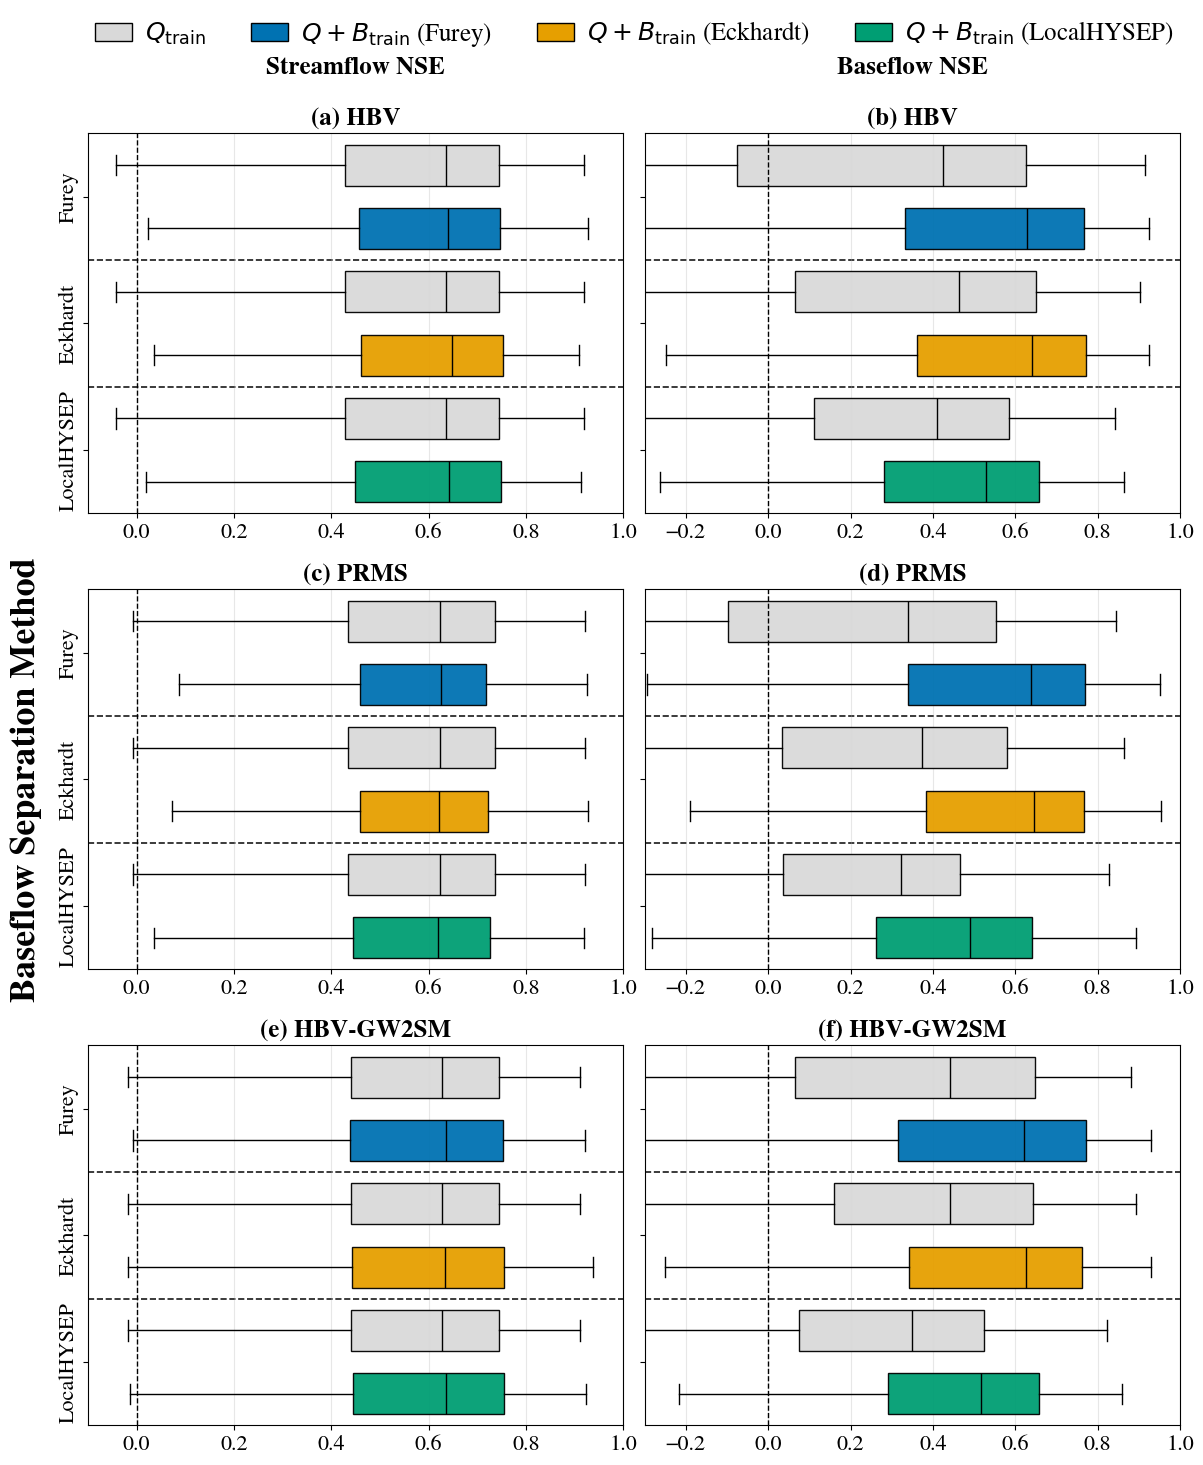

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

loss= 'NSE'
plt.rcParams['font.family']= 'Nimbus Roman'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================

all_tables = {}

for i,method in enumerate(methods):
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/Single/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/Single/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)

        # print(method,model)
        # print(table.columns)
        all_tables[(method, model)] = table.copy()

# ============================================================
# CREATE 3 x 2 BOXPLOT FIGURE
# Single-Objective above Multi-Objective
# ============================================================
# gray #D9D9D9
# Furey: blue #0072B2
# Eckhardt: orange #E69F00
# LocalHYSEP: bluish green #009E73
# Colors: lighter = Single, darker = Multi
method_colors = {
    'Furey': {
        'Single': '#D9D9D9',
        'Multi':  '#0072B2'
    },
    'Eckhardt': {
        'Single': '#D9D9D9',
        'Multi':  '#E69F00'
    },
    'LocalHYSEP': {
        'Single': '#D9D9D9',
        'Multi':  '#009E73'
    }
}

model_names = {
    'HBV': 'HBV',
    'marrmot_PRMS': 'PRMS',
    'HBV_capillary': 'HBV-GW2SM'
}

flow_col = 'NSE-Flow (Multi-Objective)'
baseflow_col = 'NSE-Baseflow (Multi-Objective)'

flow_single = 'NSE-Flow (Single-Objective)'
baseflow_single = 'NSE-Baseflow (Single-Objective)'

median_props = {
    'color': 'black',
    'linestyle': '-',
    'linewidth': 1
}

# ============================================================
# BOXPLOT POSITIONS
# ============================================================

# Each method has two boxes:
# Single-Objective above Multi-Objective

positions = [6, 5, 4, 3, 2, 1]

# Method labels centered between each pair
tick_positions = [5.5, 3.5, 1.5]

# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(13, 17),
    # sharex=True,
    sharex=False
)

# ============================================================
# LOOP OVER MODELS
# ============================================================

for i, model in enumerate(models):

    # ========================================================
    # STREAMFLOW NSE
    # ========================================================

    flow_data = []
    flow_colors = []

    for method in methods:

        # Single-Objective values
        values_single = all_tables[(method, model)][flow_single].to_numpy()
        values_single = values_single[np.isfinite(values_single)]

        # Multi-Objective values
        values_multi = all_tables[(method, model)][flow_col].to_numpy()
        values_multi = values_multi[np.isfinite(values_multi)]

        # Append Single first, then Multi
        flow_data.extend([
            values_single,
            values_multi
        ])

        flow_colors.extend([
            method_colors[method]['Single'],
            method_colors[method]['Multi']
        ])

    # Create boxplots
    bp = axes[i, 0].boxplot(
        flow_data,
        positions=positions,
        vert=False,
        widths=0.65,
        patch_artist=True,
        showfliers=False,
        # whis=(5, 95),
        medianprops=median_props
    )
    lab0= ['(a)','(c)', '(e)']
    # axes[i,0].set_xlabel(lab0[i],fontsize=20)
    # Apply colors
    for patch, color in zip(bp['boxes'], flow_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.95)

    # Center method labels between Single and Multi
    axes[i, 0].set_yticks(tick_positions)
    axes[i, 0].set_yticklabels(methods)

    if i==0: # Titles and axes formatting 
        axes[i, 0].set_title( f'Streamflow NSE\n \n{lab0[i]} {model_names[model]}', fontsize=18, fontweight='bold' ) 
    else: 
          axes[i, 0].set_title( f'{lab0[i]} {model_names[model]}', fontsize=18, fontweight='bold' )

    axes[i, 0].axvline(
        0,
        color='black',
        linestyle='--',
        linewidth=1
    )

    axes[i, 0].grid(
        axis='x',
        alpha=0.3
    )
    
    
    # ========================================================
    # BASEFLOW NSE
    # ========================================================

    baseflow_data = []
    baseflow_colors = []

    for method in methods:

        # Single-Objective values
        values_single = all_tables[(method, model)][baseflow_single].to_numpy()
        values_single = values_single[np.isfinite(values_single)]

        # Multi-Objective values
        values_multi = all_tables[(method, model)][baseflow_col].to_numpy()
        values_multi = values_multi[np.isfinite(values_multi)]

        # Append Single first, then Multi
        baseflow_data.extend([
            values_single,
            values_multi
        ])

        baseflow_colors.extend([
            method_colors[method]['Single'],
            method_colors[method]['Multi']
        ])

    # Create boxplots
    bp = axes[i, 1].boxplot(
        baseflow_data,
        positions=positions,
        vert=False,
        widths=0.65,
        patch_artist=True,
        showfliers=False,
        # whis=(5, 95),
        medianprops=median_props
    )

    # Apply colors
    for patch, color in zip(bp['boxes'], baseflow_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.95)

    # Center method labels between Single and Multi
    axes[i, 1].set_yticks(tick_positions)
    axes[i, 1].set_yticklabels(methods)


    lab1= ['(b)','(d)', '(f)']
    # axes[i,1].set_xlabel(lab1[i],fontsize=20)

    if i==0: # Titles and axes formatting 
        axes[i, 1].set_title( f'Baseflow NSE\n \n{lab1[i]} {model_names[model]}', fontsize=18, fontweight='bold' ) 
    else: 
          axes[i, 1].set_title( f'{lab1[i]} {model_names[model]}', fontsize=18, fontweight='bold' )

    axes[i, 1].axvline(
        0,
        color='black',
        linestyle='--',
        linewidth=1
    )

    axes[i, 1].grid(
        axis='x',
        alpha=0.3
    )


    axes[i,0].set_xlim(-0.1,1)
    axes[i,1].set_xlim(-0.3,1)
    



    # ============================================================
    # DASHED LINES BETWEEN BASEFLOW SEPARATION METHODS
    # ============================================================

    for j in range(2):  # Streamflow and Baseflow columns

        ax = axes[i, j]

        # Draw separators between methods
        for k in range(len(methods) - 1):

            y_sep = (tick_positions[k] + tick_positions[k + 1]) / 2

            ax.axhline(
                y_sep,
                color='black',
                linestyle='--',
                linewidth=1.2,
                alpha=0.9,
                zorder=0
            )
    # ========================================================
    # Y-AXIS FORMATTING
    # ========================================================

    for j in range(2):
        axes[i, j].tick_params( 
            axis='y',
            pad=10
        )

        plt.setp(
            axes[i, j].get_yticklabels(),
            rotation=90,
            ha='center',
            va='center',
            fontsize=16,
        )

        plt.setp(
            axes[i, j].get_xticklabels(),
            # rotation=90,
            # ha='center',
            # va='center',
            fontsize=16,
        )

        axes[i, j].set_ylim(0.5, 6.5)

        axes[i, 1].set_yticklabels([])
# ============================================================
# COMMON LABELS
# ============================================================

# fig.supxlabel(
#     'Nash–Sutcliffe Efficiency (NSE)',
#     fontsize=24,
#     # fontweight='bold',
#     y=0.04
# )

fig.supylabel(
    'Baseflow Separation Method',
    fontsize=26,
    fontweight='bold',
    x=0.08
)

# ============================================================
# SPACING
# ============================================================

# plt.subplots_adjust(
#     left=0.14,
#     right=0.98,
#     bottom=0.13,
#     top=0.94,
#     wspace=0.12,
#     hspace=0.35
# )

plt.subplots_adjust(
    left=0.14,
    right=0.98,
    bottom=0.12,
    top=0.88,
    wspace=0.04,
    hspace=0.2
)

# plt.suptitle("\t       NSE of Withheld Regions: Streamflow only vs Joint training",fontsize=24)#, fontweight='bold')


from matplotlib.patches import Patch

# ============================================================
# LEGEND
# ============================================================

legend_handles = [
    Patch(
        facecolor='#D9D9D9',
        edgecolor='black',
        label=r'$Q_{\mathrm{train}}$'
    ),
    Patch(
        facecolor='#0072B2',
        edgecolor='black',
        label=r'$Q+B_{\mathrm{train}}$ (Furey)'
    ),
    Patch(
        facecolor='#E69F00',
        edgecolor='black',
        label=r'$Q+B_{\mathrm{train}}$ (Eckhardt)'
    ),
    Patch(
        facecolor='#009E73',
        edgecolor='black',
        label= r'$Q+B_{\mathrm{train}}$ (LocalHYSEP)'
    )
]

fig.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.56, 0.96),
    ncol=4,
    fontsize=18,
    frameon=False,
    handlelength=1.5,
    columnspacing=1.8,
    handletextpad=0.5
)


# plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures_{loss}/10192026_Reducedspace_{loss}_loss_Boxplots_standard_whiskers.jpg", dpi= 400)
plt.show()

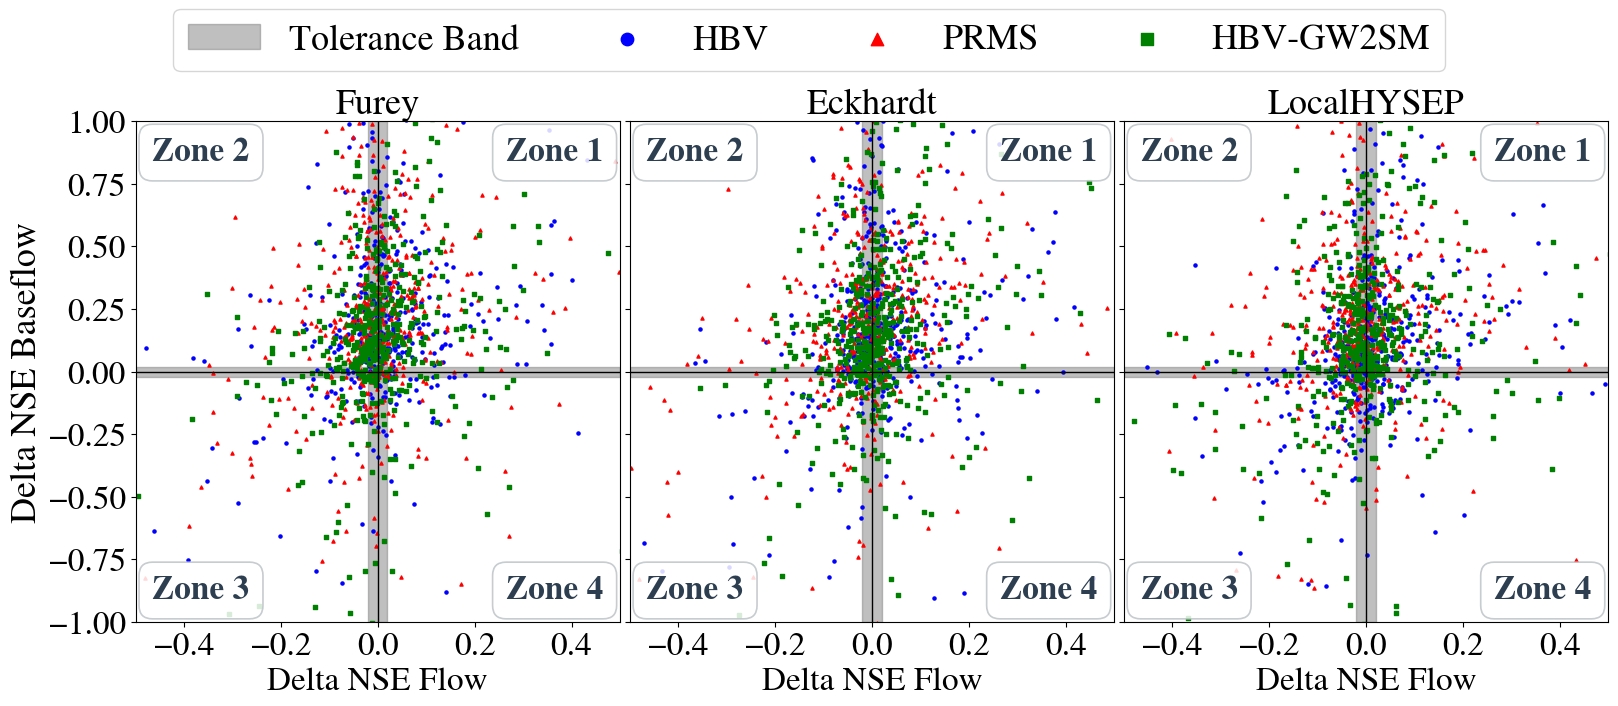

In [46]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

loss= 'NSE'
plt.rcParams['font.family']= 'Nimbus Roman'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================

all_tables = {}
plt.figure(figsize=(19,6.5))

for i,method in enumerate(methods):
    tables = []
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/Single/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/Single/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)
        table['NSE-DeltaFlow']= table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']
        table['NSE-DeltaBaseflow']= table['NSE-Baseflow (Multi-Objective)'] - table['NSE-Baseflow (Single-Objective)']


        tables.append(table)
        # print(method,model)
        # print(table.columns)
        all_tables[(method, model)] = table.copy()

    plt.subplot(1,3,i+1)
    # Add shaded tolerance areas (alpha=0.5 gray)
    plt.axvspan(-0.02, 0.02, color="gray", alpha=0.5, label='Tolerance Band')
    plt.axhspan(-0.02, 0.02, color="gray", alpha=0.5)
    plt.axhline(0, color="black", linestyle="-", linewidth=1)
    plt.axvline(0, color="black", linestyle="-", linewidth=1)
    # plt.axhline(0, color="gray", linestyle="--", linewidth=1)
    # plt.axvline(0, color="gray", linestyle="--", linewidth=1)
    plt.scatter(tables[0]['NSE-DeltaFlow'],tables[0]['NSE-DeltaBaseflow'], label=model_names[models[0]], marker='o', color= 'blue', s=5)
    plt.scatter(tables[1]['NSE-DeltaFlow'],tables[1]['NSE-DeltaBaseflow'], label=model_names[models[1]], marker='^', color= 'red', s=5)
    plt.scatter(tables[2]['NSE-DeltaFlow'],tables[2]['NSE-DeltaBaseflow'], label=model_names[models[2]], marker='s', color= 'green', s=5)
    plt.xlabel(f'Delta NSE Flow', fontsize= 24)

    # plt.text(0.3,0.55, 'Zone 1', fontsize= 22,)
    # plt.text(-0.4,0.55, 'Zone 2', fontsize= 22,)
    # plt.text(-0.4,-0.55, 'Zone 3', fontsize= 22,)
    # plt.text(0.3,-0.55, 'Zone 4', fontsize= 22,)
    zones = [
    (0.365, 0.875, 'Zone 1'),
    (-0.365, 0.875, 'Zone 2'),
    (-0.365, -0.875, 'Zone 3'),
    (0.365, -0.875, 'Zone 4')
    ]

    for x, y, text in zones:
        plt.text(
            x, y, text,
            fontsize=24,
            fontweight='bold',
            color='#2c3e50',  # Soft dark slate instead of harsh pure black
            ha='center',      # Center-align horizontally on the coordinate
            va='center',      # Center-align vertically on the coordinate
            bbox=dict(
                boxstyle='round,pad=0.4', 
                facecolor='white', 
                edgecolor='#bdc3c7', 
                alpha=0.85,       # Semi-transparent background
                linewidth=1.2
            )
        )
    plt.title(method, fontsize=26)
    if i==0:
        plt.ylabel('Delta NSE Baseflow', fontsize= 26)
        plt.yticks(fontsize=24)
    else:
        plt.tick_params(labelleft=False)
    plt.xlim(-0.5, 0.5)
    plt.ylim(-1, 1)

    plt.xticks(fontsize=24)
plt.subplots_adjust(wspace=0.02)

# plt.text(0.01,0.55, 'Zone 1', fontsize= 22,)
# plt.text(0.02,0.55, 'Zone 1', fontsize= 22,)
# plt.text(0.3,0.55, 'Zone 1', fontsize= 22,)


# plt.text(-0.4,0.55, 'Zone 2', fontsize= 22,)
# plt.text(-0.4,-0.55, 'Zone 3', fontsize= 22,)
# plt.text(0.3,-0.55, 'Zone 4', fontsize= 22,)


# plt.text(0.3,0.55, 'Zone 2', fontsize= 22,)
# plt.text(0.3,0.55, 'Zone 2', fontsize= 22,)

# plt.text(0.3,0.55, 'Zone 3', fontsize= 22,)
# plt.text(0.3,0.55, 'Zone 3', fontsize= 22,)
# plt.text(0.3,0.55, 'Zone 3', fontsize= 22,)


# Place legend at the top middle, arranged horizontally (3 columns)
plt.legend(loc="upper right", bbox_to_anchor=(0.7, 1.26), ncol=4, frameon=True, fontsize=26, markerscale=4.0)

# plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures_{loss}/Zonal{loss}_losss_Flow_Baseflow_scatterplot.jpg",bbox_inches='tight' , dpi= 400)
plt.show()

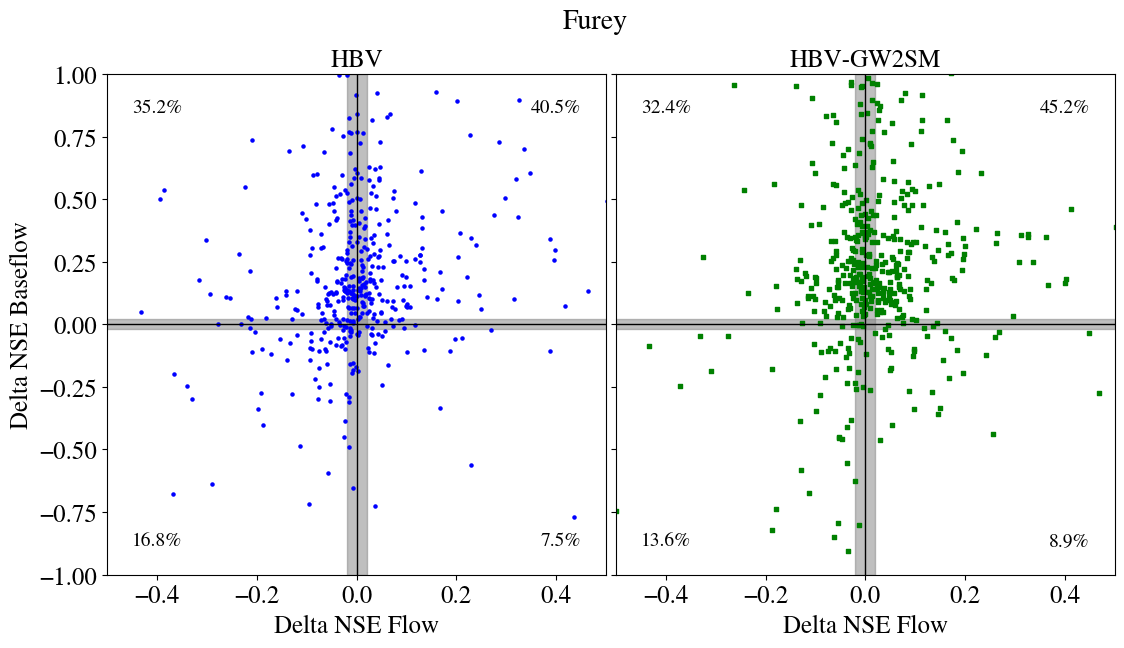

In [5]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

loss= 'NSE'
plt.rcParams['font.family']= 'Nimbus Roman'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']
methods=['Furey']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================

all_tables = {}

tables = []
for i,model in enumerate(models):
   
    for j,method in enumerate(methods):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)
        table['NSE-DeltaFlow']= table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']
        table['NSE-DeltaBaseflow']= table['NSE-Baseflow (Multi-Objective)'] - table['NSE-Baseflow (Single-Objective)']


        tables.append(table)
        # print(method,model)
        # print(table.columns)
        all_tables[(method, model)] = table.copy()

import numpy as np

plt.figure(figsize=(13, 6.5))

# Loop for the two subplots (index 0 for tables[0], index 1 for tables[2])
plot_configs = [(1, 0, "blue", "o"), (2, 2, "green", "s")]

for subplot_idx, table_idx, color, marker in plot_configs:
  plt.subplot(1, 2, subplot_idx)

  # Shaded tolerance areas & origin lines
  plt.axvspan(-0.02, 0.02, color="gray", alpha=0.5)
  plt.axhspan(-0.02, 0.02, color="gray", alpha=0.5)
  plt.axhline(0, color="black", linestyle="-", linewidth=1)
  plt.axvline(0, color="black", linestyle="-", linewidth=1)

  # Data
  x = tables[table_idx]["NSE-DeltaFlow"]
  y = tables[table_idx]["NSE-DeltaBaseflow"]

  plt.scatter(
      x,
      y,
      label=model_names[models[table_idx]],
      marker=marker,
      color=color,
      s=5,
  )

  # --- Calculate Quadrant Percentages ---
  total_points = len(x)
  if total_points > 0:
    # Quadrant 1: x > 0, y > 0 (Top-Right)
    q1 = np.sum((x > 0) & (y > 0)) / total_points * 100
    # Quadrant 2: x < 0, y > 0 (Top-Left)
    q2 = np.sum((x < 0) & (y > 0)) / total_points * 100
    # Quadrant 3: x < 0, y < 0 (Bottom-Left)
    q3 = np.sum((x < 0) & (y < 0)) / total_points * 100
    # Quadrant 4: x > 0, y < 0 (Bottom-Right)
    q4 = np.sum((x > 0) & (y < 0)) / total_points * 100

    # Display percentages as text in each corner
    # (x_pos, y_pos, text, horizontalalignment, verticalalignment)
    text_kwargs = dict(
        fontsize=14,
        color="black",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7),
    )

    plt.text(0.45, 0.9, f"{q1:.1f}%", ha="right", va="top", **text_kwargs)  # TR
    plt.text(
        -0.45, 0.9, f"{q2:.1f}%", ha="left", va="top", **text_kwargs
    )  # TL
    plt.text(
        -0.45, -0.9, f"{q3:.1f}%", ha="left", va="bottom", **text_kwargs
    )  # BL
    plt.text(
        0.45, -0.9, f"{q4:.1f}%", ha="right", va="bottom", **text_kwargs
    )  # BR

  # Plot styling
  plt.xlabel("Delta NSE Flow", fontsize=18)
  plt.title(model_names[models[table_idx]], fontsize=18)
  plt.xlim(-0.5, 0.5)
  plt.ylim(-1, 1)
  plt.xticks(fontsize=18)
  plt.yticks(fontsize=18)

  if subplot_idx == 1:
    plt.ylabel("Delta NSE Baseflow", fontsize=18)
  else:
    plt.tick_params(labelleft=False)

plt.subplots_adjust(wspace=0.02)
plt.suptitle("Furey", fontsize=20)
plt.show()

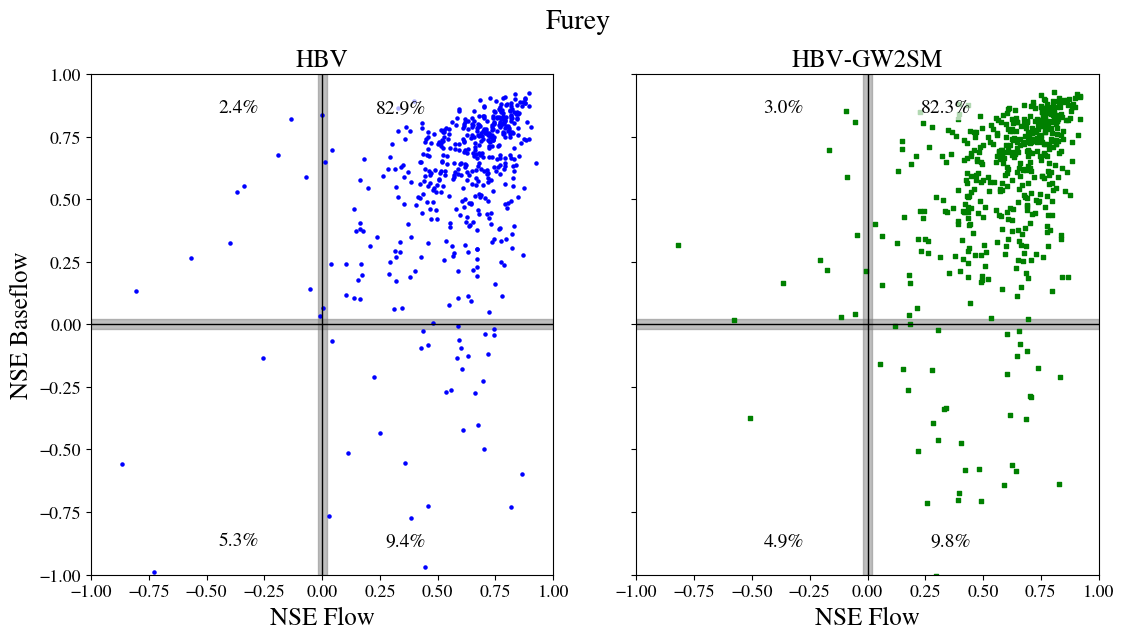

In [6]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

loss= 'NSE'
plt.rcParams['font.family']= 'Nimbus Roman'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']
methods=['Furey']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================

all_tables = {}

tables = []
for i,model in enumerate(models):
   
    for j,method in enumerate(methods):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                    f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)
        table['NSE-DeltaFlow']= table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']
        table['NSE-DeltaBaseflow']= table['NSE-Baseflow (Multi-Objective)'] - table['NSE-Baseflow (Single-Objective)']


        tables.append(table)
        # print(method,model)
        # print(table.columns)
        all_tables[(method, model)] = table.copy()

import numpy as np

plt.figure(figsize=(13, 6.5))

# Loop for the two subplots (index 0 for tables[0], index 1 for tables[2])
plot_configs = [(1, 0, "blue", "o"), (2, 2, "green", "s")]

for subplot_idx, table_idx, color, marker in plot_configs:
  plt.subplot(1, 2, subplot_idx)

  # Shaded tolerance areas & origin lines
  plt.axvspan(-0.02, 0.02, color="gray", alpha=0.5)
  plt.axhspan(-0.02, 0.02, color="gray", alpha=0.5)
  plt.axhline(0, color="black", linestyle="-", linewidth=1)
  plt.axvline(0, color="black", linestyle="-", linewidth=1)

  # Data
  x = tables[table_idx]["NSE-Flow (Multi-Objective)"]
  y = tables[table_idx]["NSE-Baseflow (Multi-Objective)"]

  plt.scatter(
      x,
      y,
      label=model_names[models[table_idx]],
      marker=marker,
      color=color,
      s=5,
  )

  # --- Calculate Quadrant Percentages ---
  total_points = len(x)
  if total_points > 0:
    # Quadrant 1: x > 0, y > 0 (Top-Right)
    q1 = np.sum((x > 0) & (y > 0)) / total_points * 100
    # Quadrant 2: x < 0, y > 0 (Top-Left)
    q2 = np.sum((x < 0) & (y > 0)) / total_points * 100
    # Quadrant 3: x < 0, y < 0 (Bottom-Left)
    q3 = np.sum((x < 0) & (y < 0)) / total_points * 100
    # Quadrant 4: x > 0, y < 0 (Bottom-Right)
    q4 = np.sum((x > 0) & (y < 0)) / total_points * 100

    # Display percentages as text in each corner
    # (x_pos, y_pos, text, horizontalalignment, verticalalignment)
    text_kwargs = dict(
        fontsize=14,
        color="black",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7),
    )

    plt.text(0.45, 0.9, f"{q1:.1f}%", ha="right", va="top", **text_kwargs)  # TR
    plt.text(
        -0.45, 0.9, f"{q2:.1f}%", ha="left", va="top", **text_kwargs
    )  # TL
    plt.text(
        -0.45, -0.9, f"{q3:.1f}%", ha="left", va="bottom", **text_kwargs
    )  # BL
    plt.text(
        0.45, -0.9, f"{q4:.1f}%", ha="right", va="bottom", **text_kwargs
    )  # BR

  # Plot styling
  plt.xlabel("NSE Flow", fontsize=18)
  plt.title(model_names[models[table_idx]], fontsize=18)
  plt.xlim(-1, 1)
  plt.ylim(-1, 1)
  plt.xticks(fontsize=13)
  plt.yticks(fontsize=13)

  if subplot_idx == 1:
    plt.ylabel("NSE Baseflow", fontsize=18)
  else:
    plt.tick_params(labelleft=False)

plt.subplots_adjust(wspace=0.18)
plt.suptitle("Furey", fontsize=20)
plt.show()

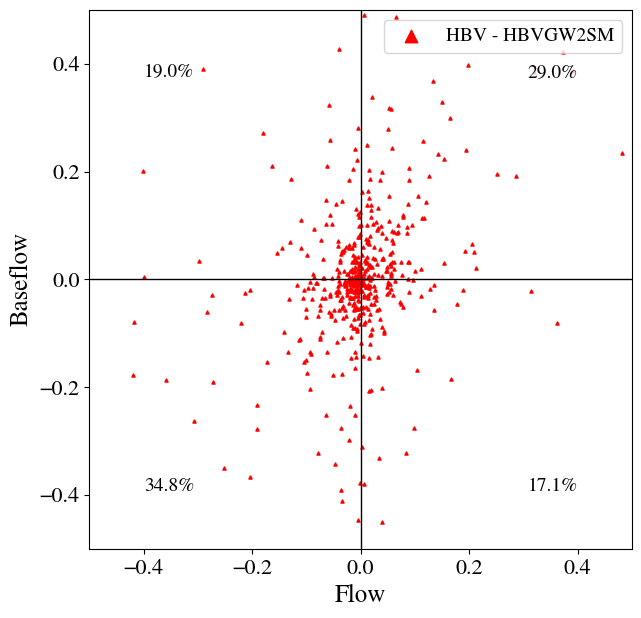

In [8]:
import pandas as pd
comp= pd.DataFrame()
comp['NSE-DeltaFlow']= tables[0]['NSE-Flow (Multi-Objective)']-tables[2]['NSE-Flow (Multi-Objective)']
comp['NSE-DeltaBaseflow']= tables[0]['NSE-Baseflow (Multi-Objective)']-tables[2]['NSE-Baseflow (Multi-Objective)']
comp

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Calculate total points and percentages
total_points = len(comp)

q1_pct = (
    len(
        comp[
            (comp['NSE-DeltaFlow'] > 0) & (comp['NSE-DeltaBaseflow'] > 0)
        ]
    )
    / total_points
    * 100
)
q2_pct = (
    len(
        comp[
            (comp['NSE-DeltaFlow'] < 0) & (comp['NSE-DeltaBaseflow'] > 0)
        ]
    )
    / total_points
    * 100
)
q3_pct = (
    len(
        comp[
            (comp['NSE-DeltaFlow'] < 0) & (comp['NSE-DeltaBaseflow'] < 0)
        ]
    )
    / total_points
    * 100
)
q4_pct = (
    len(
        comp[
            (comp['NSE-DeltaFlow'] > 0) & (comp['NSE-DeltaBaseflow'] < 0)
        ]
    )
    / total_points
    * 100
)

# Create figure
plt.figure(figsize=(7, 7))

plt.scatter(
    comp['NSE-DeltaFlow'],
    comp['NSE-DeltaBaseflow'],
    label='HBV - HBVGW2SM',
    marker='^',
    color='red',
    s=5,
)
plt.axhline(0, color='black', linestyle='-', linewidth=1)
plt.axvline(0, color='black', linestyle='-', linewidth=1)
plt.xlim(-0.5, 0.5)
plt.ylim(-0.5, 0.5)
plt.legend(markerscale=4, fontsize=14, loc='upper right')

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel('Flow', fontsize=18)
plt.ylabel('Baseflow', fontsize=18)

# Add percentage annotations to each quadrant
# Coordinates (x, y) can be adjusted based on your preference
plt.text(
    0.4,
    0.4,
    f'{q1_pct:.1f}%',
    fontsize=14,
    ha='right',
    va='top',
    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec='none'),
)
plt.text(
    -0.4,
    0.4,
    f'{q2_pct:.1f}%',
    fontsize=14,
    ha='left',
    va='top',
    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec='none'),
)
plt.text(
    -0.4,
    -0.4,
    f'{q3_pct:.1f}%',
    fontsize=14,
    ha='left',
    va='bottom',
    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec='none'),
)
plt.text(
    0.4,
    -0.4,
    f'{q4_pct:.1f}%',
    fontsize=14,
    ha='right',
    va='bottom',
    bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec='none'),
)

plt.show()

HUC2 CRS before assignment: None
HUC2 bounds before transformation:
[-7783576.02289802  2187575.63815253  3619690.05690435 10257816.27458091]
HUC2 CRS after assignment: EPSG:26915
HUC2 CRS after transformation: EPSG:4326
HUC2 bounds after transformation:
[-179.96928239   17.67456073  179.91556688   71.39676244]

HUC2 columns:
['HUC2', 'COUNT', 'REG_NAME', 'ACRES', 'geometry']

Using HUC2 column: HUC2

HUC2 codes found:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']

The following HUC2 regions were not assigned:
['19', '20', '21']

PUR REGION SUMMARY
   PUR_region                                           geometry
0           1  MULTIPOLYGON (((-75.90469 37.11406, -75.91338 ...
1           2  MULTIPOLYGON (((-83.07339 29.09564, -83.07442 ...
2           3  MULTIPOLYGON (((-77.85699 41.82669, -77.85942 ...
3           4  POLYGON ((-105.67422 40.27259, -105.6871 40.28...
4           5  MULTIPOLYGON (((-97.2193

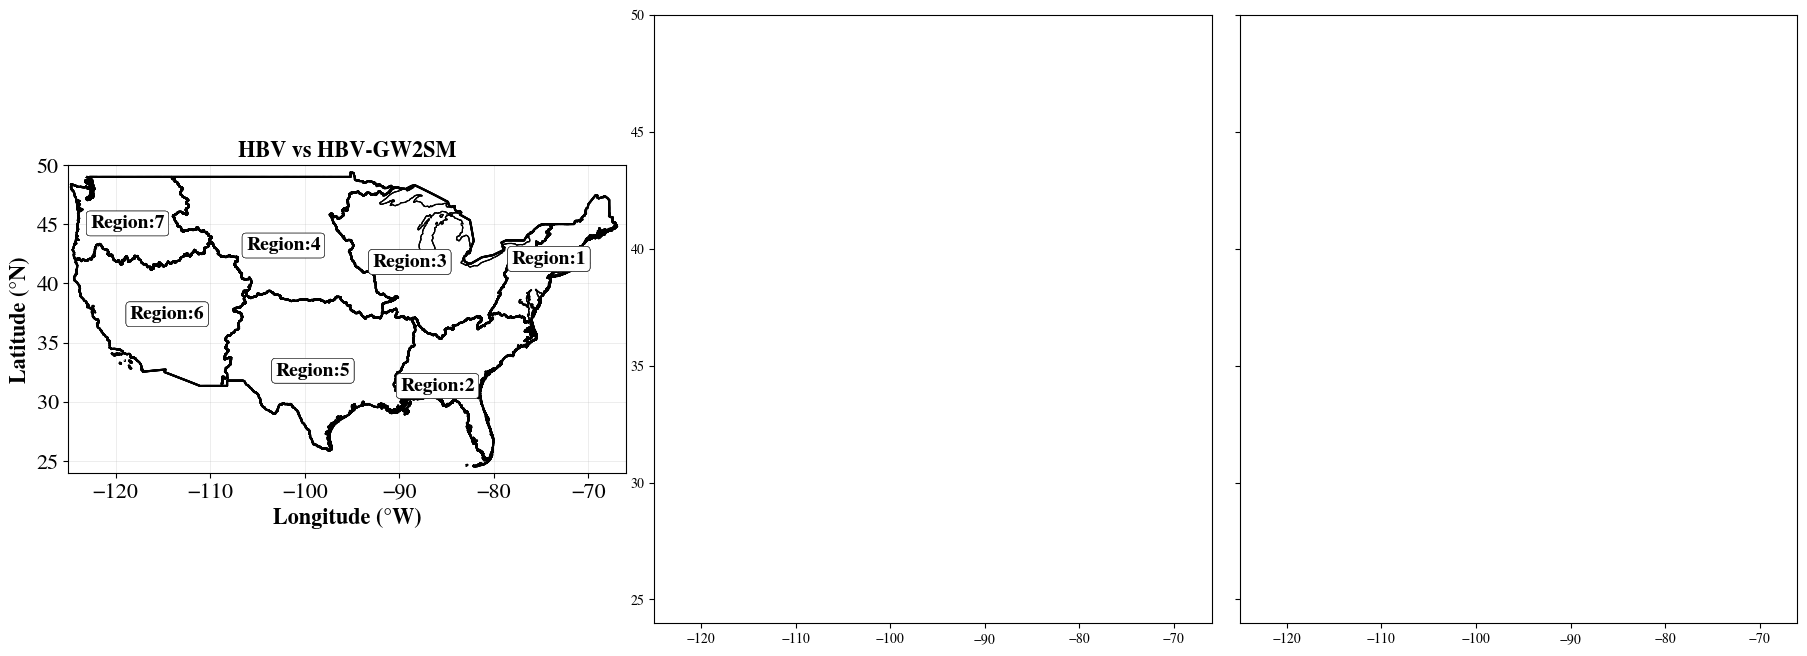

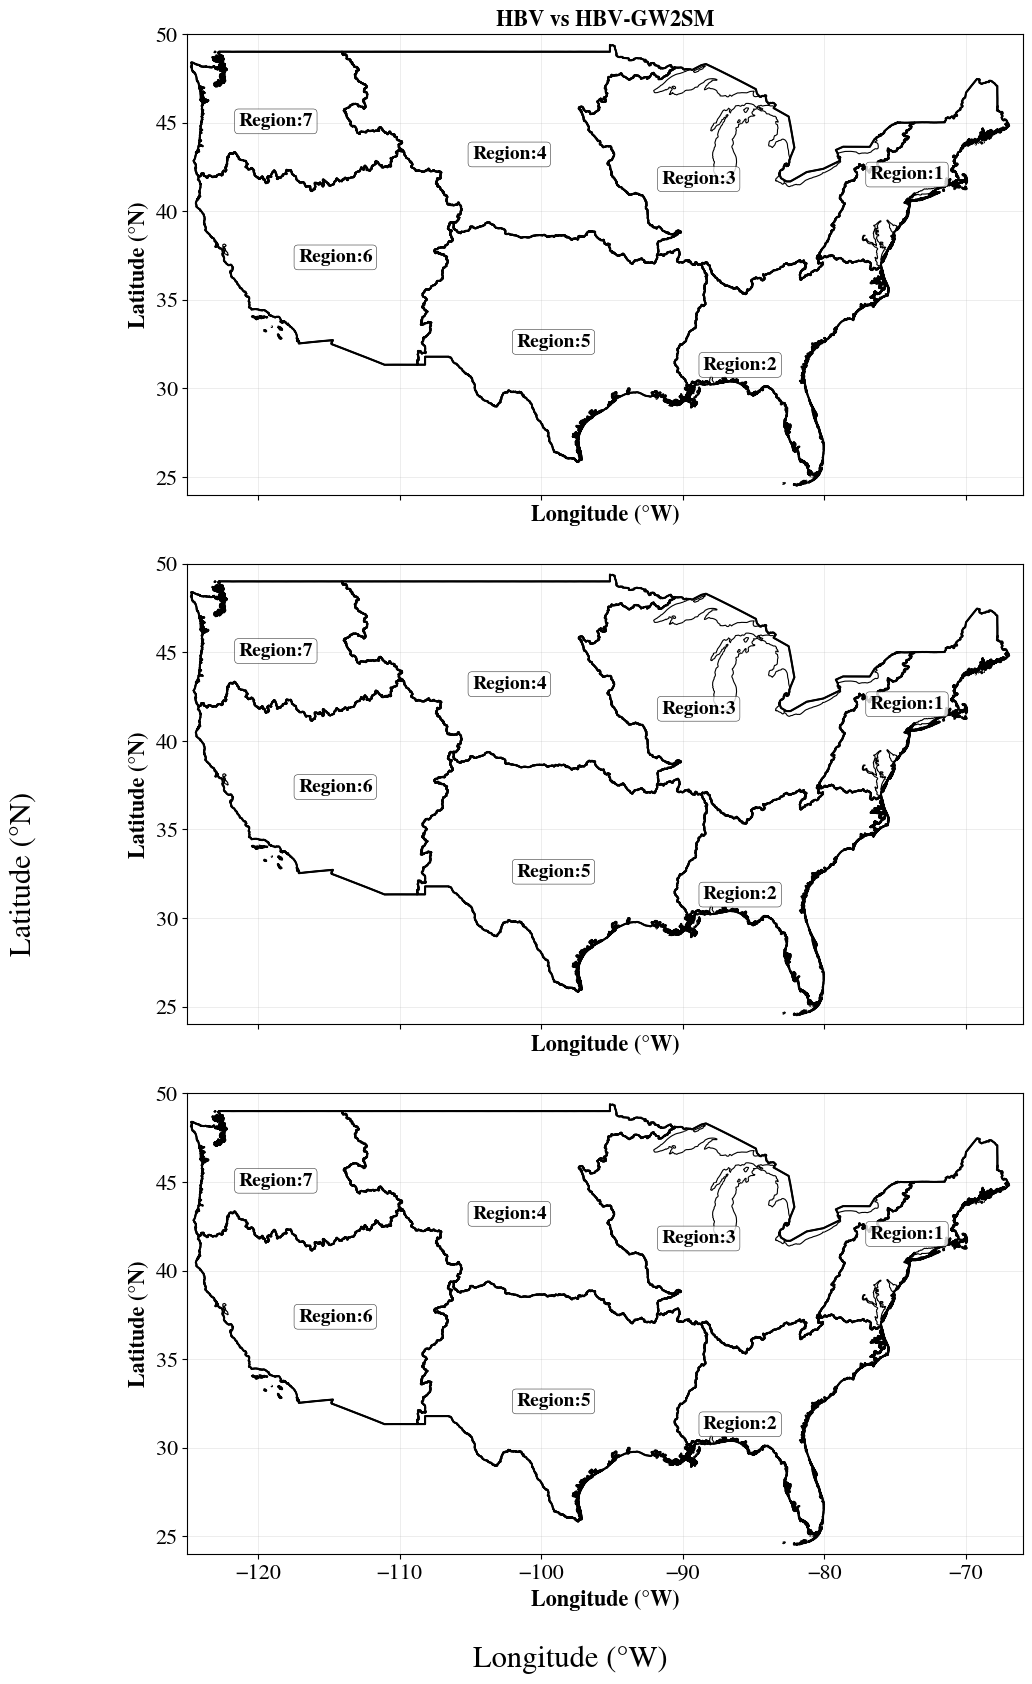

In [8]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

# ============================================================
# FUNCTION TO PLOT PUR REGIONS AND REGION NUMBERS
# ============================================================
loss= 'NSE'

def add_pur_regions(ax, gdf_pur_regions):

    # Plot PUR region boundaries
    gdf_pur_regions.boundary.plot(
        ax=ax,
        edgecolor="black",
        linewidth=1.5,
        zorder=3
    )

    # Add region numbers
    for _, row in gdf_pur_regions.iterrows():

        label_point = row.geometry.representative_point()

        ax.text(
            label_point.x,
            label_point.y,
            f"Region:{int(row['PUR_region'])}",
            fontsize=14,
            fontweight='bold',
            ha="center",
            va="center",
            color="black",
            zorder=5,
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                linewidth=0.4,
                alpha=0.8,
                boxstyle="round,pad=0.2"
            )
        )


plt.rcParams['font.family']= 'Nimbus Roman'

gdf = gpd.read_file("/scratch/data/cb_2018_us_nation_20m/cb_2018_us_nation_20m.shp")

# Make sure the layer is in geographic coordinates (WGS84)
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Define CONUS bounding box: minx, miny, maxx, maxy
conus_bbox = box(-125.0, 24.0, -66.5, 50.0)

# Clip the geodataframe to the bounding box
gdf_conus = gpd.clip(gdf, conus_bbox)


# ============================================================
# PUR REGION DEFINITION FROM FENG ET AL.
# ============================================================

pur_groups = {
    1: ['01', '02'],
    2: ['03', '06'],
    3: ['04', '05', '07'],
    4: ['09', '10'],
    5: ['08', '11', '12', '13'],
    6: ['14', '15', '16', '18'],
    7: ['17']
}

# [ [1,2], [3,6], [4,5,7], [9,10], [8,11,12,13], [14,15,16,18], [17] ]

# ------------------------------------------------------------
# Make sure HUC2 codes are strings with leading zero
# ------------------------------------------------------------

gdf_huc2 = gpd.read_file("/home/s0shar47/scratch/huc_02/huc_02.shp")

print("HUC2 CRS before assignment:", gdf_huc2.crs)
print("HUC2 bounds before transformation:")
print(gdf_huc2.total_bounds)
gdf_huc2 = gdf_huc2.set_crs(
    "EPSG:26915"
)

print("HUC2 CRS after assignment:", gdf_huc2.crs)


# ============================================================
# TRANSFORM HUC2 TO WGS84
# ============================================================

gdf_huc2 = gdf_huc2.to_crs(
    "EPSG:4326"
)

print("HUC2 CRS after transformation:", gdf_huc2.crs)
print("HUC2 bounds after transformation:")
print(gdf_huc2.total_bounds)


# ============================================================
# CHECK HUC2 COLUMNS
# ============================================================

print("\nHUC2 columns:")
print(gdf_huc2.columns.tolist())


possible_huc_columns = [
    "HUC2",
    "HUC_2",
    "HUC2_CODE",
    "HUC_02",
    "HUC_02_",
    "HUC2_",
    "HUC"
]

huc_column = None

for col in possible_huc_columns:

    if col in gdf_huc2.columns:
        huc_column = col
        break

if huc_column is None:

    raise ValueError(
        "\nCould not identify the HUC2 column.\n"
        "Available columns are:\n"
        + str(gdf_huc2.columns.tolist())
    )

print("\nUsing HUC2 column:", huc_column)


# ============================================================
# STANDARDIZE HUC2 CODES
# ============================================================

gdf_huc2["HUC2_CODE"] = (
    gdf_huc2[huc_column]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
    .str.zfill(2)
)

print("\nHUC2 codes found:")
print(
    sorted(
        gdf_huc2["HUC2_CODE"].unique()
    )
)


# ============================================================
# CREATE HUC2 -> PUR REGION LOOKUP
# ============================================================

huc_to_region = {}

for region, hucs in pur_groups.items():

    for huc in hucs:

        huc_to_region[huc] = region


# ============================================================
# ASSIGN PUR REGION
# ============================================================

gdf_huc2["PUR_region"] = (
    gdf_huc2["HUC2_CODE"]
    .map(huc_to_region)
)


# Check whether any HUC2 was not assigned
unassigned = gdf_huc2[
    gdf_huc2["PUR_region"].isna()
]

if len(unassigned) > 0:

    print("\nWARNING:")
    print("The following HUC2 regions were not assigned:")
    print(
        unassigned["HUC2_CODE"]
        .tolist()
    )


# ============================================================
# KEEP PUR REGIONS
# ============================================================

gdf_pur = gdf_huc2.dropna(
    subset=["PUR_region"]
).copy()

gdf_pur["PUR_region"] = (
    gdf_pur["PUR_region"]
    .astype(int)
)


# ============================================================
# DISSOLVE HUC2 INTO PUR REGIONS
# ============================================================

gdf_pur_regions = (
    gdf_pur
    .dissolve(
        by="PUR_region"
    )
    .reset_index()
)


print("\n" + "=" * 70)
print("PUR REGION SUMMARY")
print("=" * 70)

print(
    gdf_pur_regions[
        ["PUR_region", "geometry"]
    ]
)


# ============================================================
# CREATE BASIN POINTS
# ============================================================

print("\n" + "=" * 70)
print("CREATING BASIN POINTS")
print("=" * 70)


## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
# models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']
models= ['HBV']



if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'

# ============================================================
# CREATE BOTH 3 x 1 FIGURES BEFORE THE LOOPS
# ============================================================

fig_flow, axes_flow = plt.subplots(
    1, 3,
    figsize=(19, 8),
    sharex=True,
    sharey=True
)

fig_baseflow, axes_baseflow = plt.subplots(
    3, 1,
    figsize=(14, 20),
    sharex=True,
    sharey=True
)

scatter_flow = None
scatter_baseflow = None

# ============================================================
# YOUR 3 x 1 LOOPS
# ============================================================


for i,method in enumerate(methods):
    for j,model in enumerate(models):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,n):
        
            # print(f"Processing Region {region}")
        
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                )
            
            ob_flow = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/HBV_capillary/{region}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/HBV_capillary/{region}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)


        # ax = axes_flow[i, j]
        ax = axes_flow[0]

        # CONUS boundary
        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )

        
        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        gdf_pur_regions.boundary.plot(
                    ax=ax,
                    edgecolor="black",
                    linewidth=1.2,
                    zorder=3
                )
        if i == 0:
            # --------------------------------------------
            # Subplot title
            # --------------------------------------------
            ax.set_title(
                            f"{model_name} vs HBV-GW2SM",
                            fontsize=16,
                            fontweight='bold'
                        )
            # ax.set_title(
            #     f"{method} | {model_name}",
            #     fontsize=13,
            #     fontweight='bold'
            # )

        if j== 0:

            ax.set_ylabel(f"Latitude (°N)",
                                                fontsize=16,
                                                fontweight='bold')
            ax.set_xlabel(f"Longitude (°W)",
                                                fontsize=16,
                                                fontweight='bold')



        # --------------------------------------------
        # Map limits
        # --------------------------------------------

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        # --------------------------------------------
        # Grid
        # --------------------------------------------

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=16,
            which= 'major'
        )

        ax= axes_flow[1]
        ax.tick_params(
                    axis='both',
                    labelleft='False'
                )
        # ====================================================
        # FIGURE 2:
        # DELTA BASEFLOW NSE
        # ====================================================

        # ax = axes_baseflow[i, j]
        ax = axes_baseflow[i]

        # --------------------------------------------
        # CONUS boundary
        # --------------------------------------------

        gdf_conus.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=0.8,
            zorder=1
        )


        # ADD PUR REGIONS AND NUMBERS
        add_pur_regions(ax, gdf_pur_regions)

        # --------------------------------------------
        # PUR Region boundaries
        # --------------------------------------------

        gdf_pur_regions.boundary.plot(
            ax=ax,
            edgecolor="black",
            linewidth=1.2,
            zorder=3
        )

        

        if i == 0:
                    # --------------------------------------------
                    # Subplot title
                    # --------------------------------------------
                    ax.set_title(
                                    f"{model_name} vs HBV-GW2SM",
                                    fontsize=16,
                                    fontweight='bold'
                                )
                    # ax.set_title(
                    #     f"{method} | {model_name}",
                    #     fontsize=13,
                    #     fontweight='bold'
                    # )
        
        if j== 0:
        
                    ax.set_ylabel(f"Latitude (°N)",
                                    fontsize=16,
                                    fontweight='bold')
                    ax.set_xlabel(f"Longitude (°W)",
                                    fontsize=16,
                                    fontweight='bold')
        

        ax.set_xlim(-125, -66)
        ax.set_ylim(24, 50)

        ax.grid(
            True,
            linewidth=0.4,
            alpha=0.4
        )

        ax.tick_params(
            axis='both',
            labelsize=16,
            which= 'major'
        )

        print(i, j, method, model)


# ============================================================
# FIGURE 1 FORMATTING
# DELTA FLOW NSE
# ============================================================

# fig_flow.suptitle(
#     "Change in Streamflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


# ------------------------------------------------------------
# Shared X/Y labels
# ------------------------------------------------------------

# fig_flow.supxlabel(
#     "Longitude (°W)",
#     fontsize=22,
#     y=0.1
# )

# fig_flow.supylabel(
#     "Latitude (°N)",
#     fontsize=22,
#     x=0.1
# )


# ------------------------------------------------------------
# Make room for colorbar
# ------------------------------------------------------------

fig_flow.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.16,
    wspace=0.05,
    hspace=0.15
)


# ============================================================
# FIGURE 2 FORMATTING
# DELTA BASEFLOW NSE
# ============================================================

# fig_baseflow.suptitle(
#     "Change in Baseflow NSE: Multi-Objective − Single-Objective",
#     fontsize=20,
#     fontweight='bold',
#     y=0.98
# )


fig_baseflow.supxlabel(
    "Longitude (°W)",
    fontsize=22,
    y=0.1
)

fig_baseflow.supylabel(
    "Latitude (°N)",
    fontsize=22,
    x=0.1
)


fig_baseflow.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.16,
    wspace=0.05,
    hspace=0.15
)


# ============================================================
# SHOW ONLY AFTER ALL 9 SUBPLOTS HAVE BEEN CREATED
# ============================================================
# output_dir = "/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures/"

# fig_flow.savefig(
#     f"{output_dir}/Delta_Flow_NSE_HBV_vs_HBVgw2sm.jpg",
#     dpi=400,
#     bbox_inches="tight")

# fig_baseflow.savefig(
#     f"{output_dir}/Delta_Baseflow_NSE_HBV_vs_HBVgw2sm.jpg",
#     dpi=400,
#     bbox_inches="tight")

plt.show()

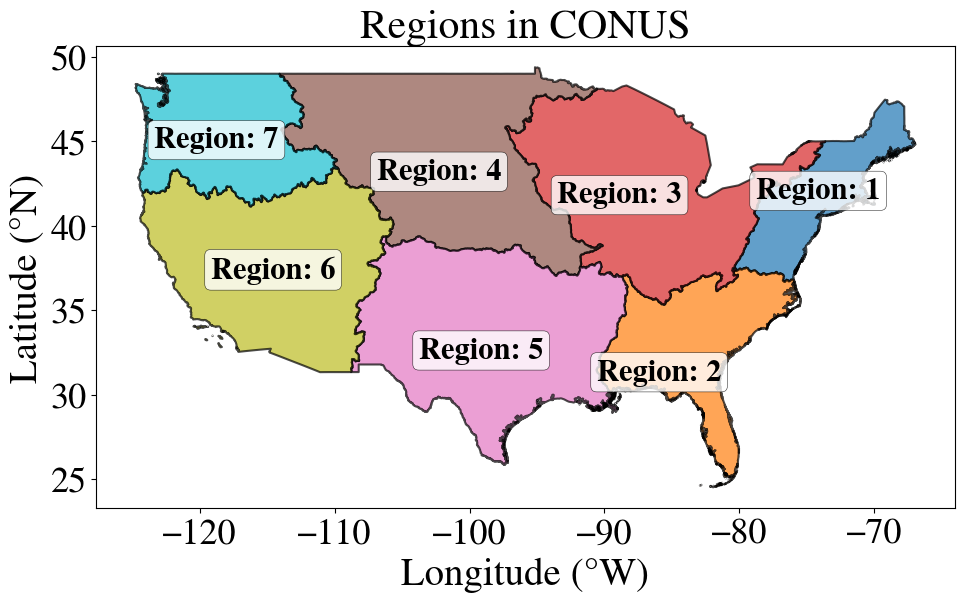

In [27]:
import matplotlib.pyplot as plt

def add_pur_regions(ax, gdf_pur_regions):
    # Plot filled PUR regions with a distinct color for each region
    gdf_pur_regions.plot(
        ax=ax,
        column='PUR_region',
        cmap='tab10',          # Qualitative colormap for distinct region colors
        edgecolor="black",
        linewidth=1.5,
        zorder=3,
        alpha=0.7              # Optional transparency so labels are easy to read
    )

    # Add region numbers using ax.text so they bind to the correct subplot
    for _, row in gdf_pur_regions.iterrows():
        label_point = row.geometry.representative_point()

        ax.text(
            label_point.x,
            label_point.y,
            f"Region: {int(row['PUR_region'])}",
            fontsize=22,
            fontweight='bold',
            ha="center",
            va="center",
            color="black",
            zorder=5,
            bbox=dict(
                facecolor="white",
                edgecolor="black",
                linewidth=0.4,
                alpha=0.8,
                boxstyle="round,pad=0.2"
            )
        )

# Create a figure with a single subplot
fig, ax = plt.subplots(1, 1, figsize=(14, 6))

# Plot on the axis
add_pur_regions(ax, gdf_pur_regions)
ax.set_title("Regions in CONUS", fontsize=30)


plt.ylabel(f"Latitude (°N)", fontsize=28) #, fontweight='bold')
plt.xlabel(f"Longitude (°W)", fontsize=28) #, fontweight='bold')
plt.xticks(fontsize=26)
plt.yticks(fontsize=26)
# Hide the axis frame and ticks for a clean map layout
# ax.axis('off')

# plt.tight_layout()
plt.show()

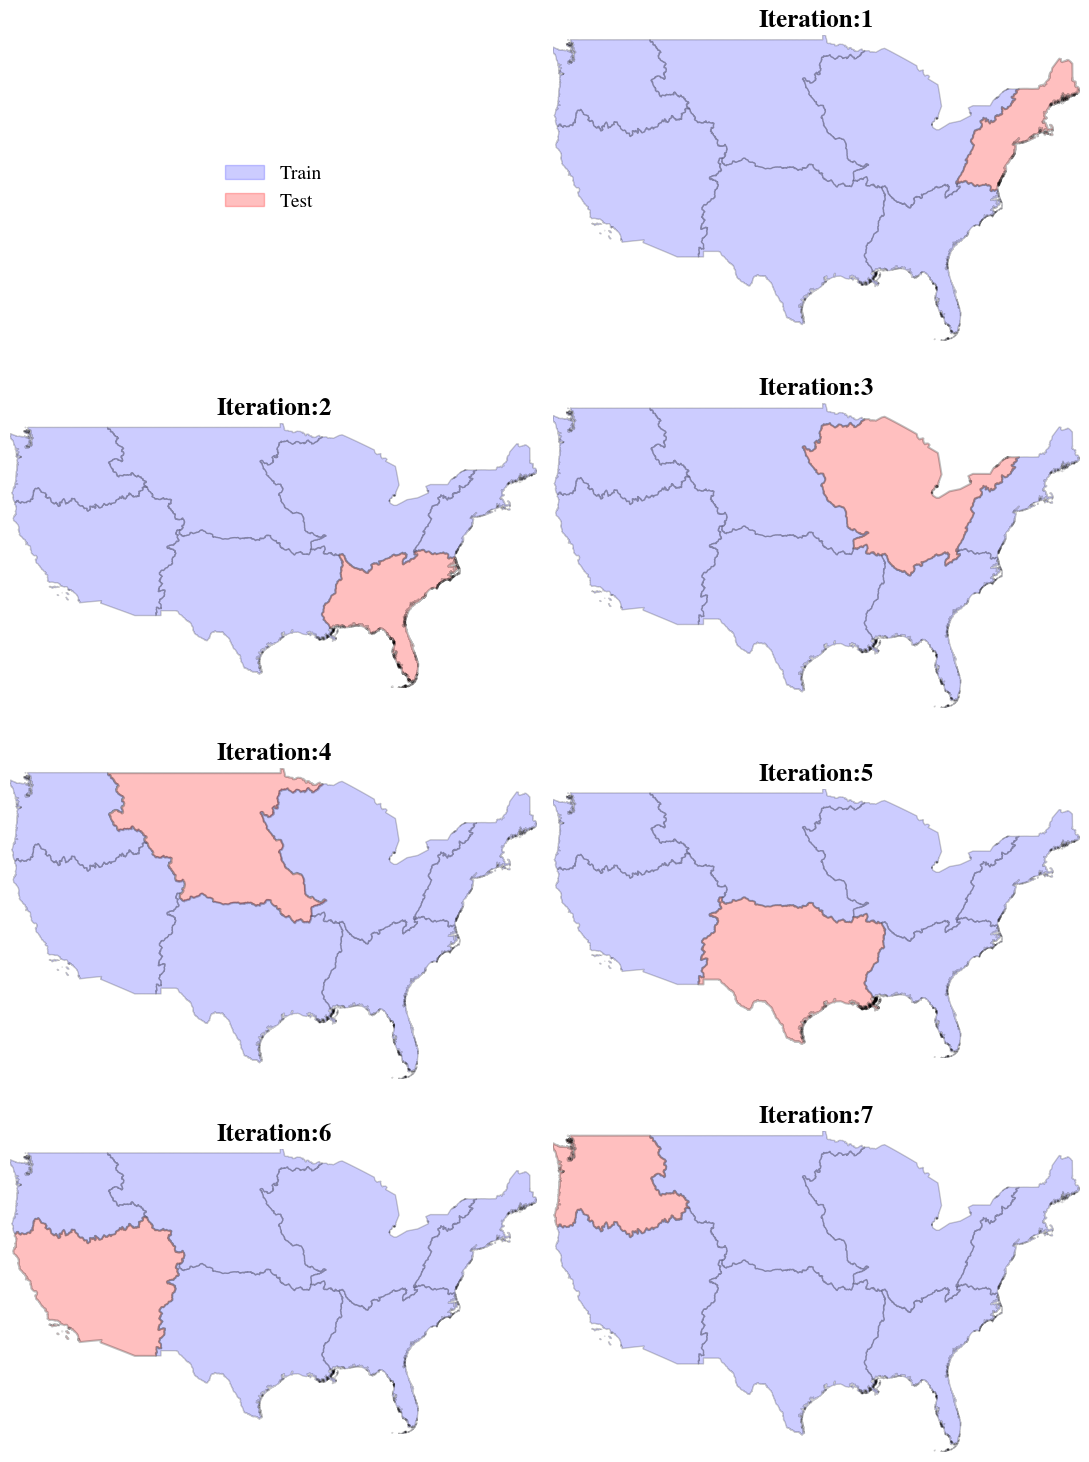

In [43]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import geopandas as gpd

# Limit to the first 7 regions (or however many you need)
num_regions = min(len(gdf_pur_regions), 7)

# Get the global bounding box of the entire dataset so all maps match perfectly
minx, miny, maxx, maxy = gdf_pur_regions.total_bounds

# Create a grid of subplots (4 rows, 2 columns = 8 total slots)
fig, axes = plt.subplots(4, 2, figsize=(11, 15))
axes = axes.flatten()  # Flatten the 2D array of axes into a 1D list

# 1. Place the legend in the very first slot (axes[0])
train_patch = mpatches.Patch(color='blue', alpha=0.2, label='Train')
test_patch = mpatches.Patch(color='red', alpha=0.25, label='Test')

axes[0].legend(
    handles=[train_patch, test_patch], 
    loc='center', 
    fontsize=14, 
    frameon=False
)
axes[0].axis('off')  # Hide the box border for the legend slot

# 2. Loop through the regions and plot them starting from index 1 (axes[1] to axes[7])
for i in range(num_regions):
    ax = axes[i + 1]  # Shift by +1 to leave axes[0] free for the legend
    target_idx = gdf_pur_regions.index[i]
    
    # Plot all OTHER regions in blue (Train)
    others = gdf_pur_regions.drop(target_idx)
    others.plot(
        ax=ax,
        color='blue',
        edgecolor='black',
        linewidth=1.0,
        alpha=0.2,
        zorder=2
    )
    
    # Plot the TARGET region in red (Test)
    target = gdf_pur_regions.loc[[target_idx]]
    target.plot(
        ax=ax,
        color='red',
        edgecolor='black',
        linewidth=1.5,
        alpha=0.25,
        zorder=3
    )
    
    # Force all subplots to share the exact same map boundaries and scale
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)
    
    # Title and cleanup
    region_num = int(target['PUR_region'].values[0])
    ax.set_title(f"Iteration:{region_num}", fontsize=18, fontweight='bold')
    ax.axis('off')

# Hide any remaining unused subplots
for j in range(num_regions + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [51]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

loss= 'NSE'
plt.rcParams['font.family']= 'Nimbus Roman'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

# method= 'LocalHYSEP'
methods= ['Eckhardt','Furey', 'LocalHYSEP']
# methods=['Eckhardt']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']

# models= ['HBV']


if test== 'PUB':
    n=11
if test== 'PUR':
    n=8


def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

if test=='PUB':
        time= '1989_1999'

if test=='PUR':
        time= '1989_1999'

if test=='Temporal':
        time= '1980_2014'


# ============================================================
# YOUR 3 x 3 LOOPS
# ============================================================

all_tables = {}
summary_metrics = []
tables = []
for i,model in enumerate(models):
   
    for j,method in enumerate(methods):
        if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

        if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'

        if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

        locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")
        
        metrics = {
                        "GageID": [],
                        "NSE-Flow (Single-Objective)": [],
                        "NSE-Flow (Multi-Objective)": [],
                        "NSE-Baseflow (Single-Objective)": [],
                        "NSE-Baseflow (Multi-Objective)": [],
                        "lat": [],
                        "lon": []
        }
        
        
        for r in range(1,8):
        
            # print(f"Processing Region {region}")
        
        # --------------------------------------------------
        # REGION SPECIFIC FORCING
        # --------------------------------------------------
            if test=='PUR':
                        region= f'Region_{r}'
            if test=='PUB':
                        region= r

            gauge = np.load(
                        f"/scratch/data/{test}_DATA/test/{region}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
                    )
            
            ob_flow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy"
                )
            
            sim_flow_old = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            sim_flow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy"
                )
            
            ob_baseflow = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy"
                )
            
            sim_gwflow_old = np.load(
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_gwflow_new = np.load(
                    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/{test}/{method}_Multi/{loss}/{model}/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"
                )
            
            sim_flow_old = np.squeeze(sim_flow_old)
            sim_flow_new = np.squeeze(sim_flow_new)
            sim_gwflow_old = np.squeeze(sim_gwflow_old)
            sim_gwflow_new = np.squeeze(sim_gwflow_new)
            

            # --------------------------------------------------------
            # Loop over basins
            # --------------------------------------------------------
            for k in range(ob_flow.shape[1]):

                gid = int(gauge[k, 0, -2])

                matching_row = locations[locations['GAGE_ID'] == gid]
                lat = matching_row['LAT'].item()
                lon = matching_row['LONG'].item()
                # lat= locations.loc[f'{gid}',['LAT']]
                # lon= locations.loc[f'{gid}',['LONG']]

                metrics["GageID"].append(gid)
                metrics["lat"].append(lat)
                metrics["lon"].append(lon)

                ## Baseflow
                obs = ob_baseflow[:, k]
                old = sim_gwflow_old[:, k]
                new = sim_gwflow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Baseflow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Baseflow (Multi-Objective)"].append(calc_nse(obs, new))

                ## Flow
                obs = ob_flow[:, k]
                old = sim_flow_old[:, k]
                new = sim_flow_new[:, k]

                # =====================================================
                # Overall metrics
                # =====================================================
                metrics["NSE-Flow (Single-Objective)"].append(calc_nse(obs, old))
                metrics["NSE-Flow (Multi-Objective)"].append(calc_nse(obs, new))
        table = pd.DataFrame(metrics)
        table['NSE-DeltaFlow']= table['NSE-Flow (Multi-Objective)'] - table['NSE-Flow (Single-Objective)']
        table['NSE-DeltaBaseflow']= table['NSE-Baseflow (Multi-Objective)'] - table['NSE-Baseflow (Single-Objective)']
        print(model, method)
        # display(table)

        # Number of entries
        n = len(table)

        # -----------------------------------------------------
        # Median changes
        # -----------------------------------------------------
        median_delta_flow = table['NSE-DeltaFlow'].median()
        median_delta_baseflow = table['NSE-DeltaBaseflow'].median()

        # -----------------------------------------------------
        # Four possible sign combinations
        # -----------------------------------------------------

        # Both improve
        both_positive = (
            (table['NSE-DeltaFlow'] > 0) &
            (table['NSE-DeltaBaseflow'] > 0)
        ).mean() * 100

        # Flow improves, Baseflow decreases
        flow_pos_base_neg = (
            (table['NSE-DeltaFlow'] > 0) &
            (table['NSE-DeltaBaseflow'] < 0)
        ).mean() * 100

        # Baseflow improves, Flow decreases
        base_pos_flow_neg = (
            (table['NSE-DeltaBaseflow'] > 0) &
            (table['NSE-DeltaFlow'] < 0)
        ).mean() * 100

        # Both decrease
        both_negative = (
            (table['NSE-DeltaFlow'] < 0) &
            (table['NSE-DeltaBaseflow'] < 0)
        ).mean() * 100

        # -----------------------------------------------------
        # Target met
        # Baseflow improvement > 0.02
        # while Streamflow degradation is no worse than -0.02
        # -----------------------------------------------------
        target_met = (
            (table['NSE-DeltaBaseflow'] > 0.02) &
            (table['NSE-DeltaFlow'] >= -0.02)
        ).mean() * 100

        # -----------------------------------------------------
        # Streamflow loss
        # -----------------------------------------------------
        streamflow_loss = (
            table['NSE-DeltaFlow'] < 0
        ).mean() * 100


        # Flow improves
        flow_pos = (
                    (table['NSE-DeltaFlow'] > 0)
                ).mean() * 100

        tol = 0.02
        d_b, d_q = table['NSE-DeltaBaseflow'], table['NSE-DeltaFlow']
        
        # target_met      = ((d_b > tol) & (d_q >= -tol)).mean() * 100
        # baseflow_gain   = (d_b > tol).mean() * 100      # meaningful baseflow improvement
        # baseflow_loss   = (d_b < -tol).mean() * 100     # meaningful baseflow degradation
        streamflow_loss = (d_q < -tol).mean() * 100     # meaningful streamflow degradation
        streamflow_gain = (d_q > tol).mean() * 100
        
        from scipy.stats import wilcoxon
        p_b = wilcoxon(d_b.dropna()).pvalue
        p_q = wilcoxon(d_q.dropna()).pvalue
        # -----------------------------------------------------
        # Save summary
        # -----------------------------------------------------

        def format_pvalue(p):
            if p < 0.001:
                return f"{p:.2e}"  # Scientific notation for tiny values
            else:
                return f"{p:.3f}"  # Standard 3 decimal places for normal values
            
        summary_metrics.append({
            'Model': model,
            'Method': method,
            'Median NSE-DeltaFlow': f"{median_delta_flow:.3f}",
            'Median NSE-DeltaBaseflow': f"{median_delta_baseflow:.3f}",
            'Both Positive (%)': f"{both_positive:.3f}",
            'Flow + / Baseflow - (%)': f"{flow_pos_base_neg:.3f}",
            'Baseflow + / Flow - (%)': f"{base_pos_flow_neg:.3f}",
            'Both Negative (%)': f"{both_negative:.3f}",
            'Target Met (%)': f"{target_met:.3f}",
            'Streamflow Loss (%)': f"{streamflow_loss:.3f}",
            'Streamflow Gain (%)': f"{streamflow_gain:.3f}",
            'P_B': format_pvalue(p_b),
            'P_Q': format_pvalue(p_q),
        })
# ============================================================
# FINAL SUMMARY TABLE
# ============================================================

summary_table = pd.DataFrame(summary_metrics)

# Round values for display
summary_table = summary_table.round({
    'Median NSE-DeltaFlow': 3,
    'Median NSE-DeltaBaseflow': 3,
    'Both Positive (%)': 1,
    'Flow + / Baseflow - (%)': 1,
    'Baseflow + / Flow - (%)': 1,
    'Both Negative (%)': 1,
    'Target Met (%)': 1,
    'Streamflow Loss (%)': 1
})

display(summary_table)
summary_table.to_csv("/home/s0shar47/scratch/somemetrics.csv", index=False)

HBV Eckhardt
HBV Furey
HBV LocalHYSEP
marrmot_PRMS Eckhardt
marrmot_PRMS Furey
marrmot_PRMS LocalHYSEP
HBV_capillary Eckhardt
HBV_capillary Furey
HBV_capillary LocalHYSEP


,Model,Method,Median NSE-DeltaFlow,Median NSE-DeltaBaseflow,Both Positive (%),Flow + / Baseflow - (%),Baseflow + / Flow - (%),Both Negative (%),Target Met (%),Streamflow Loss (%),Streamflow Gain (%),P_B,P_Q
0,HBV,Eckhardt,-0.002,0.143,42.938,5.838,33.522,17.702,51.224,38.983,35.593,9.96e-31,0.990
1,HBV,Furey,-0.006,0.163,40.490,7.533,35.217,16.761,50.471,38.041,36.911,1.74e-32,0.998
2,HBV,LocalHYSEP,-0.006,0.065,34.275,10.358,31.262,23.917,41.996,41.055,33.522,4.64e-13,0.186
3,marrmot_PRMS,Eckhardt,-0.011,0.210,36.347,8.286,39.736,15.631,44.256,44.821,36.158,2.06e-33,0.259
4,marrmot_PRMS,Furey,-0.011,0.284,38.418,6.591,40.678,14.313,48.211,42.373,35.970,3.54e-42,0.359
5,marrmot_PRMS,LocalHYSEP,-0.013,0.150,33.522,8.851,39.925,17.514,40.866,46.516,35.217,5.30e-26,0.100
6,HBV_capillary,Eckhardt,0.012,0.212,46.893,8.663,30.132,14.313,56.309,29.755,45.763,1.60e-26,2.22e-06
7,HBV_capillary,Furey,0.009,0.202,45.198,8.851,32.392,13.559,55.179,33.145,45.009,2.27e-29,1.93e-04
8,HBV_capillary,LocalHYSEP,0.010,0.230,41.996,12.053,33.145,12.618,51.601,32.203,45.763,2.38e-28,8.32e-05


In [29]:
table

tol = 0.02
d_b, d_q = table['NSE-DeltaBaseflow'], table['NSE-DeltaFlow']
 
target_met      = ((d_b > tol) & (d_q >= -tol)).mean() * 100
baseflow_gain   = (d_b > tol).mean() * 100      # meaningful baseflow improvement
baseflow_loss   = (d_b < -tol).mean() * 100     # meaningful baseflow degradation
streamflow_loss = (d_q < -tol).mean() * 100     # meaningful streamflow degradation
streamflow_gain = (d_q > tol).mean() * 100
 
from scipy.stats import wilcoxon
p_b = wilcoxon(d_b.dropna()).pvalue
p_q = wilcoxon(d_q.dropna()).pvalue

In [35]:
# Check for exact zeros or NaNs
print((table['NSE-DeltaFlow'] == 0).sum())
print(table['NSE-DeltaFlow'].isna().sum())

0
0


In [41]:
 # Flow improves
flow_pos = ((table['NSE-DeltaFlow'] > 0)).mean() * 100

flow_pos

np.float64(54.23728813559322)

In [42]:
streamflow_loss = (table['NSE-DeltaFlow'] < 0).mean() * 100
streamflow_loss

np.float64(45.76271186440678)

In [1]:
import geopandas as gpd

In [2]:
gdf_huc2 = gpd.read_file("/home/s0shar47/scratch/huc_02/huc_02.shp")
gdf_huc2

,HUC2,COUNT,REG_NAME,ACRES,geometry
0,1,236,New England Region,42274146.0,"MULTIPOLYGON (((2403392.27 4831645.414, 240327..."
1,2,237,Mid Atlantic Region,74596904.0,"MULTIPOLYGON (((2030065.356 4259083.812, 20300..."
2,3,847,South Atlantic-Gulf Region,176381467.0,"MULTIPOLYGON (((1760195.156 2840285.177, 17603..."
3,4,350,Great Lakes Region,115387093.0,"MULTIPOLYGON (((1314505.595 4706098.842, 13145..."
4,5,120,Ohio Region,105928558.0,"POLYGON ((1266769.778 4537710.939, 1267752.064..."
5,6,32,Tennessee Region,26518171.0,"POLYGON ((1005414.761 3819024.981, 1004554.112..."
6,7,131,Upper Mississippi Region,121505243.0,"POLYGON ((812216.911 4117750.424, 810665.767 4..."
7,8,362,Lower Mississippi Region,64813928.0,"MULTIPOLYGON (((744169.319 3235216.433, 744273..."
8,9,58,Souris-Red-Rainy Region,38069666.0,"POLYGON ((343136.281 5446139.082, 343215.167 5..."
9,10,311,Missouri Region,332782980.0,"POLYGON ((-577985.291 4534106.372, -578961.077..."


In [2]:
import pandas as pd

locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")

locations

,HUC_02,GAGE_ID,GAGE_NAME,LAT,LONG,DRAINAGE AREA (KM^2)
0,1,1013500,"Fish River near Fort Kent, Maine",47.23739,-68.58264,2252.70
1,1,1022500,"Narraguagus River at Cherryfield, M...",44.60797,-67.93524,573.60
2,1,1030500,"Mattawamkeag River near Mattawamkeag, M...",45.50097,-68.30596,3676.17
3,1,1031500,"Piscataquis River near Dover-Foxcroft, M...",45.17501,-69.31470,769.05
4,1,1047000,"Carrabassett River near North Anson, M...",44.86920,-69.95510,909.10
...,...,...,...,...,...,...
666,17,14309500,WEST FORK COW CREEK NEAR GLENDALE...,42.80400,-123.61091,224.92
667,17,14316700,STEAMBOAT CREEK NEAR GLIDE...,43.34984,-122.72894,587.90
668,17,14325000,SOUTH FORK COQUILLE RIVER AT POWERS...,42.89150,-124.07065,443.07
669,17,14362250,"STAR GULCH NEAR RUCH,...",42.15401,-123.07532,41.42


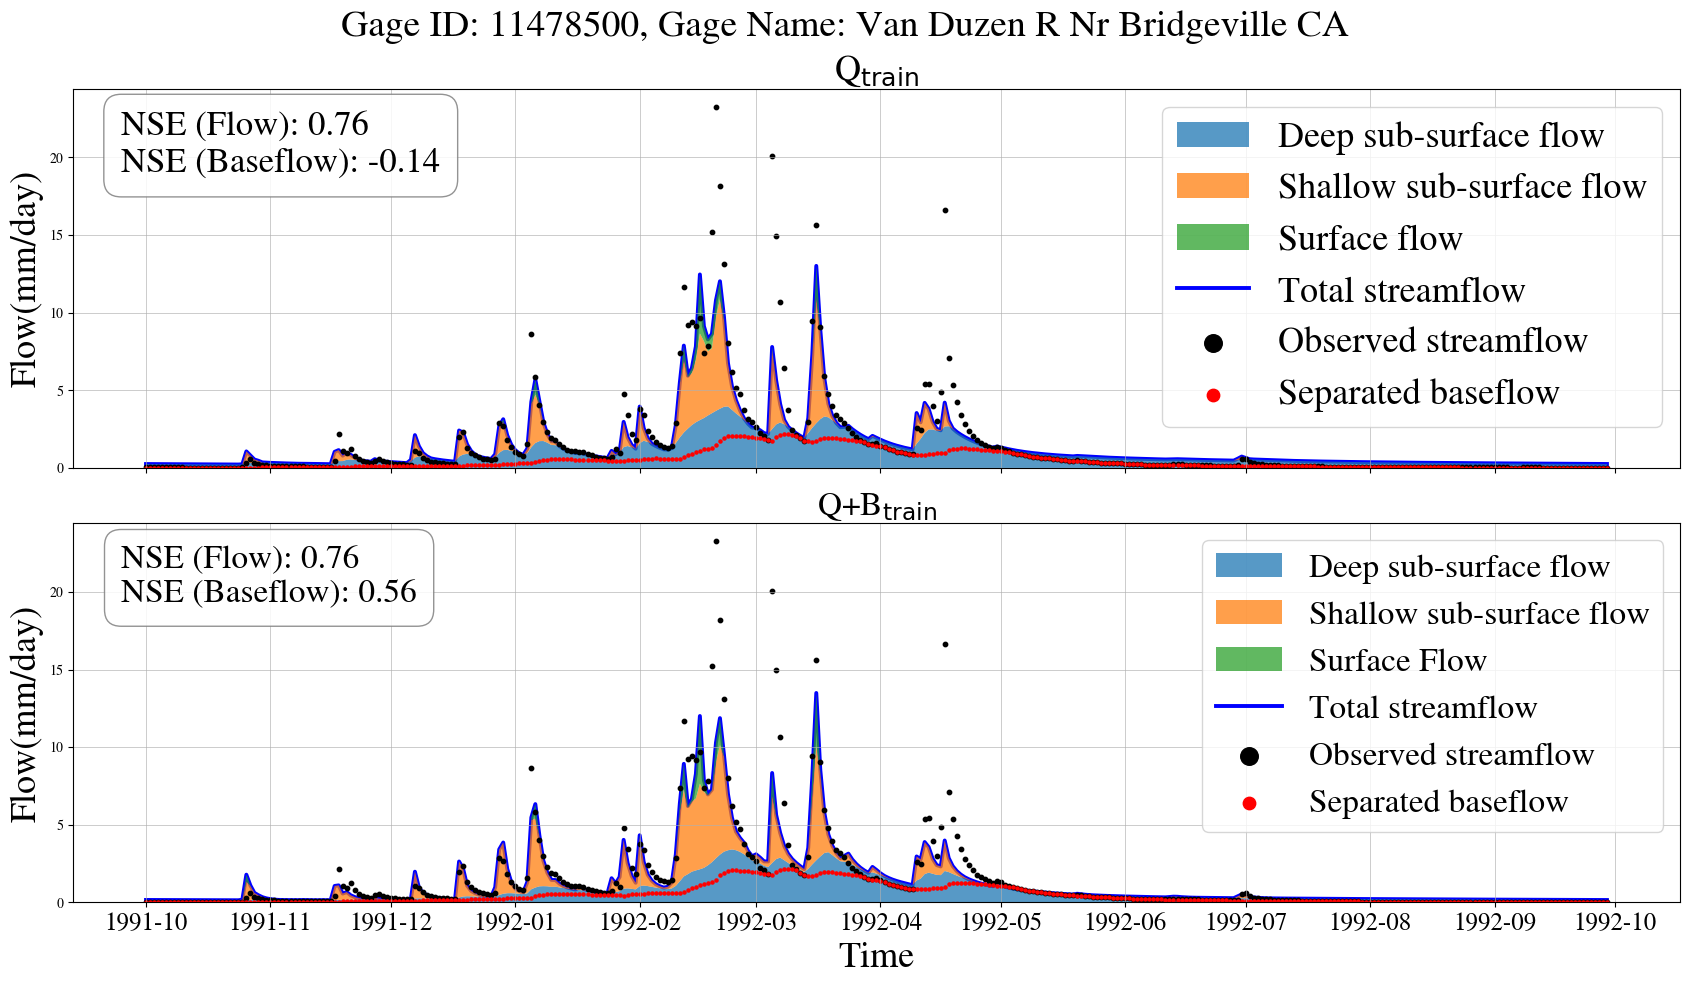

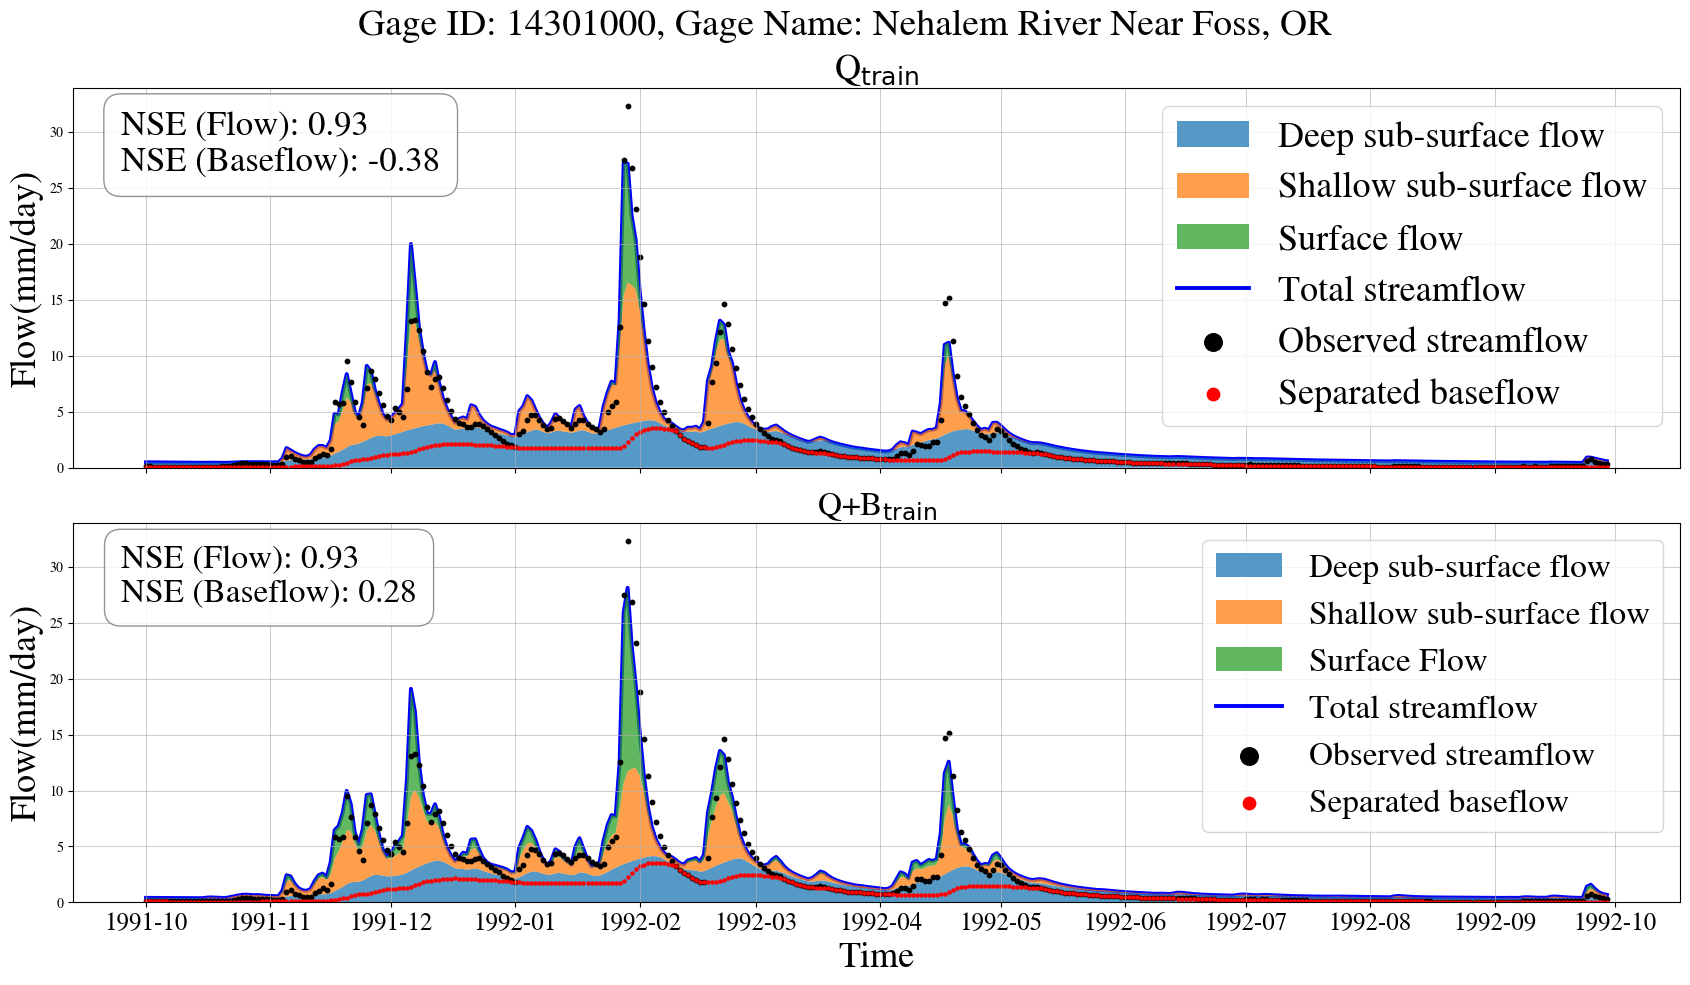

In [4]:
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

loss= 'NSE'
method= 'Furey'
model= 'HBV'
if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'
if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

# iss= ['2069700', '6903400', '12114500', '12186000', '13331500']

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

 
# iss= ['2178400']

# iss= ['14301000']

iss= ['11478500', '14301000']
# iss= ['1365000', '1439500', '5488200']
locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")

for k in range(1,8):
     folder= ("/home/s0shar47/scratch/OUTPUTS_Paper1v2/"
         f"PUR/{method}_Multi/{loss}/{model}/Region_{k}/"
         "LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111"
         f"/{dyn}/ts1989_1999/")
     sfolder= ("/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR"
         f"/Single/{loss}/{model}/Region_{k}/"
         f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111"
         f"/{dyn}/ts1989_1999/")
   
     obs_flow= np.load(os.path.join(folder,'00060_Mean.npy'))
 
     for i in range(obs_flow.shape[1]):
   
            gauge= np.load(f"/scratch/data/PUR_DATA/test/Region_{k}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
            gageid= gauge[i,0,14]
            gageid= str(int(gageid))
 
            if gageid in iss:
 
                gg= (gageid)
 
                obs_flow= np.load(os.path.join(folder,'00060_Mean.npy'))
                obs_flow= obs_flow[:,i]
 
                obs_baseflow= np.load(os.path.join(folder,'baseflow.npy'))
                obs_baseflow= obs_baseflow[:,i]
 
                single_flow= np.load(os.path.join(sfolder,'flow_sim.npy'))
                single_flow= single_flow.squeeze()
                single_flow= single_flow[:,i]
 
                multi_flow= np.load(os.path.join(folder,'flow_sim.npy'))
                multi_flow= multi_flow.squeeze()
                multi_flow= multi_flow[:,i]
 
                single_baseflow= np.load(os.path.join(sfolder,'gwflow.npy'))
                single_baseflow= single_baseflow.squeeze()
                single_baseflow= single_baseflow[:,i]
 
                multi_baseflow= np.load(os.path.join(folder,'gwflow.npy'))
                multi_baseflow= multi_baseflow.squeeze()
                multi_baseflow= multi_baseflow[:,i]
 
                surface_single= np.load(os.path.join(sfolder, 'srflow.npy'))
                surface_single= surface_single.squeeze()
                surface_single= surface_single[:,i]
 
                surface_multi= np.load(os.path.join(folder, 'srflow.npy'))
                surface_multi= surface_multi.squeeze()
                surface_multi= surface_multi[:,i]
 
                ssurface_single= np.load(os.path.join(sfolder, 'ssflow.npy'))
                ssurface_single= ssurface_single.squeeze()
                ssurface_single= ssurface_single[:,i]
 
                ssurface_multi= np.load(os.path.join(folder, 'ssflow.npy'))
                ssurface_multi= ssurface_multi.squeeze()
                ssurface_multi= ssurface_multi[:,i]
 
                df= pd.DataFrame({'Date':pd.date_range(start='1990-10-01', end='1999-09-29', freq='1D'),
                                'Observed Flow':obs_flow.tolist(),
                                'Simulated Flow (Single)':single_flow.tolist(),
                                'Simulated Flow (Multi)':multi_flow.tolist(),
                                'Observed Baseflow':obs_baseflow.tolist(),
                                'Simulated GW Flow (Single)': single_baseflow.tolist(),
                                'Simulated GW Flow (Multi)': multi_baseflow.tolist(),
                                'Simulated Surface Flow (Single)':surface_single.tolist(),
                                'Simulated Surface Flow (Multi)':surface_multi.tolist(),
                                'Simulated Sub-Surface Flow (Single)':ssurface_single.tolist(),
                                'Simulated Sub-Surface Flow (Multi)':ssurface_multi.tolist(),
                                })
                df.set_index('Date',inplace=True)


                # plt.figure(figsize=(9,5.5))

                # plt.scatter(df[920:1100].index,df[920:1100]['Observed Baseflow'],label='Separated Baseflow (mm/day)', color='red')
                # plt.plot(df[920:1100]['Simulated GW Flow (Single)'],label='Single-Objective GW Flow', color='black',linestyle='--')
                # plt.plot(df[920:1100]['Simulated GW Flow (Multi)'],label='Multi-Objective GW Flow', color='blue',linestyle='-')
                # plt.legend(fontsize=18,loc='upper right')
                # plt.xlabel("Time", fontsize=18)
                # plt.xticks(fontsize=15)
                # plt.yticks(fontsize=15)
                # plt.ylabel("Baseflow (mm/day)", fontsize=18)
                # plt.grid()
                # plt.show()
 
 
                # ============================================================
                # DATA
                # ============================================================
 
                d = df.iloc[365:730].copy()

                
                # d= df.copy()
                # ------------------------------------------------------------
                # SINGLE-OBJECTIVE
                # ------------------------------------------------------------
                # ob_streamflow = d['Observed Flow'].values
                # ob_baseflow = d['Observed Baseflow'].values
                gw_single = d['Simulated GW Flow (Single)'].values
                subsurface_single = d['Simulated Sub-Surface Flow (Single)'].values
                surface_single = d['Simulated Surface Flow (Single)'].values
 
                # Total flow
                total_single = d['Simulated Flow (Single)'].values
 
                # (    gw_single +
                #     subsurface_single +  surface_single)
 
                # ------------------------------------------------------------
                # MULTI-OBJECTIVE
                # ------------------------------------------------------------
                gw_multi = d['Simulated GW Flow (Multi)'].values
                subsurface_multi = d['Simulated Sub-Surface Flow (Multi)'].values
                surface_multi = d['Simulated Surface Flow (Multi)'].values
 
                # Total flow
                total_multi= d['Simulated Flow (Multi)'].values
                # total_multi = (
                #     gw_multi +
                #     subsurface_multi +
                #     surface_multi
                # )

                # ============================================================
                # CALCULATE NSE METRICS
                # ============================================================
                obs_flow_arr = d["Observed Flow"].values
                obs_base_arr = d["Observed Baseflow"].values

                nse_flow_single = calc_nse(obs_flow_arr, total_single)
                nse_flow_multi = calc_nse(obs_flow_arr, total_multi)
                nse_baseflow_single = calc_nse(obs_base_arr, gw_single)
                nse_baseflow_multi = calc_nse(obs_base_arr, gw_multi)

                # Common style for the text box background
                bbox_props = dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.85, edgecolor="gray")

                # ============================================================
                # FIGURE
                # ============================================================
 
                plt.rcParams['font.family'] = 'Nimbus Roman'
 
                fig, axes = plt.subplots(
                    2, 1,
                    figsize=(17, 10),
                    sharex=True
                )
 
                # ============================================================
                # SINGLE-OBJECTIVE
                # ============================================================
 
                ax = axes[0]
 
                ax.stackplot(
                    d.index,
                    gw_single,
                    subsurface_single,
                    surface_single,
                    labels=[
                        r'Deep sub-surface flow',
                        r'Shallow sub-surface flow',
                        r'Surface flow'
                    ],
                    alpha=0.75
                )
 
                # Total discharge
                ax.plot(
                    d.index,
                    total_single,
                    color='blue',
                    linewidth=2.8,
                    # label=r'Total streamflow$_{\mathrm{(Q)train}}$',
                    label='Total streamflow', 
                    zorder=0
                )
 
                ax.scatter(d.index,d['Observed Flow'], color='black', s=10, zorder=1, label= 'Observed streamflow')
                ax.scatter(d.index,d['Observed Baseflow'], color='red', s=5, zorder=1, label= 'Separated baseflow')
 
                ax.set_ylabel('Flow(mm/day)', fontsize=26)
                # ax.set_title(
                #     'Single-objective simulation',
                #     fontsize=18
                # )

                ax.set_title(
                            r'Q$_{\mathrm{train}}$',
                            fontsize=26
                            )
 
                ax.grid(
                    True,
                    which='major',
                    axis='both',
                    linestyle='-',
                    linewidth=0.5,
                    alpha=0.9
                )
 
                ax.legend(
                    fontsize=26,
                    loc='upper right',
                    frameon=True, markerscale=4.0
                )


                text_single = (
                    f"NSE (Flow): {nse_flow_single:.2f}\n"
                    f"NSE (Baseflow): {nse_baseflow_single:.2f}"
                )
                ax.text(
                    0.03,
                    0.94,
                    text_single,
                    transform=ax.transAxes,
                    fontsize=25,
                    verticalalignment="top",
                    bbox=bbox_props,
                )
                # ax.set_ylim(0,5)
                # ============================================================
                # MULTI-OBJECTIVE
                # ============================================================
 
                ax = axes[1]
 
                ax.stackplot(
                    d.index,
                    gw_multi,
                    subsurface_multi,
                    surface_multi,
                    labels=[
                        r'Deep sub-surface flow',
                        r'Shallow sub-surface flow',
                        r'Surface Flow'
                    ],
                    alpha=0.75
                )
 
                # Total discharge
                ax.plot(
                    d.index,
                    total_multi,
                    color='blue',
                    linewidth=2.8,
                    # label=r'Total streamflow$_{\mathrm{(Q+B)train}}$',
                    label='Total streamflow',
                    zorder= 0
                )
 
                ax.scatter(d.index,d['Observed Flow'], color='black', s=10, zorder=1, label= 'Observed streamflow')
                ax.scatter(d.index,d['Observed Baseflow'], color='red', s=5, zorder=1, label= 'Separated baseflow')
 
                ax.set_ylabel('Flow(mm/day)', fontsize=26)
                ax.set_xlabel('Time', fontsize=26)
 
                # ax.set_title(
                #     '\nMulti-objective simulation',
                #     fontsize=18
                # )
                ax.set_title(
                                    r'Q+B$_{\mathrm{train}}$',
                                    fontsize=24
                                )
                ax.grid(
                    True,
                    which='major',
                    axis='both',
                    linestyle='-',
                    linewidth=0.5,
                    alpha=0.9
                )
 
                ax.legend(
                    fontsize=24,
                    loc='upper right',
                    frameon=True, markerscale=4.0
                )

                text_multi = (
                    f"NSE (Flow): {nse_flow_multi:.2f}\n"
                    f"NSE (Baseflow): {nse_baseflow_multi:.2f}"
                )
                ax.text(
                    0.03,
                    0.94,
                    text_multi,
                    transform=ax.transAxes,
                    fontsize=24,
                    verticalalignment="top",
                    bbox=bbox_props,
                )
                # ax.set_ylim(0,5)
                # ============================================================
                # X-AXIS FORMATTING
                # ============================================================
 
                ax.xaxis.set_major_locator(mdates.MonthLocator())
                ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
 
                plt.setp(
                    axes[-1].get_xticklabels(),
                    rotation=0,
                    ha='center',
                    fontsize=18
                )
 
                # ============================================================
                # OVERALL TITLE
                # ============================================================
                search_id = str(int(gageid)).zfill(8)

                matched_loc = locations[locations["GAGE_ID"].astype(str).str.zfill(8) == search_id]

                if not matched_loc.empty:
                    title = matched_loc["GAGE_NAME"].iloc[0].strip()
                # Capitalize the last 2 characters (state code) if the title is long enough
                if len(title) >= 2:
                    title = title[:-2].title() + title[-2:].upper()
                else:
                    title = "Gage Name Not Found"
                # plt.suptitle(f"Gage ID: {gg}\n{title}", fontsize=21, y=0.97)                
                plt.suptitle(
                    f"Gage ID: {gg}, Gage Name: {title}",
                    fontsize=27,
                    y=0.98
                )
 
                plt.tight_layout(rect=[0, 0, 1, 1])
                # plt.savefig(f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/Figures_NSE/{loss}_loss_{gg}_flowpartition.jpg", dpi= 400)
 
                plt.show()

In [125]:
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

loss= 'NSE'
method= 'Furey'
model= 'HBV'
if model=='HBV':
                dyn= 'parBETA_parBETAET_'
                model_name='HBV'

if model=='marrmot_PRMS':
                dyn= 'alpha_cgw_scx_tt_'
                model_name='PRMS'
if model=='HBV_capillary':
                dyn= 'parBETA_parBETAET_parK0_parUZL_'
                model_name= 'HBV-GW2SM'

iss= []
 
for k in range(1,8):
     folder= ("/home/s0shar47/scratch/OUTPUTS_Paper1v2/"
         f"PUR/{method}_Multi/{loss}/{model}/Region_{k}/"
         "LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111"
         f"/{dyn}/ts1989_1999/")
     sfolder= ("/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR"
         f"/Single/{loss}/{model}/Region_{k}/"
         f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111"
         f"/{dyn}/ts1989_1999/")
   
     obs_flow= np.load(os.path.join(folder,'00060_Mean.npy'))
 
     for i in range(obs_flow.shape[1]):
   
                gauge= np.load(f"/scratch/data/PUR_DATA/test/Region_{k}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
                gageid= gauge[i,0,14]
                gageid= (int(gageid))
 
            # if gageid in iss:
 
                gg= str(gageid)
 
                obs_flow= np.load(os.path.join(folder,'00060_Mean.npy'))
                obs_flow= obs_flow[:,i]
 
                obs_baseflow= np.load(os.path.join(folder,'baseflow.npy'))
                obs_baseflow= obs_baseflow[:,i]
 
                single_flow= np.load(os.path.join(sfolder,'flow_sim.npy'))
                single_flow= single_flow.squeeze()
                single_flow= single_flow[:,i]
 
                multi_flow= np.load(os.path.join(folder,'flow_sim.npy'))
                multi_flow= multi_flow.squeeze()
                multi_flow= multi_flow[:,i]
 
                single_baseflow= np.load(os.path.join(sfolder,'gwflow.npy'))
                single_baseflow= single_baseflow.squeeze()
                single_baseflow= single_baseflow[:,i]
 
                multi_baseflow= np.load(os.path.join(folder,'gwflow.npy'))
                multi_baseflow= multi_baseflow.squeeze()
                multi_baseflow= multi_baseflow[:,i]
 
                surface_single= np.load(os.path.join(sfolder, 'srflow.npy'))
                surface_single= surface_single.squeeze()
                surface_single= surface_single[:,i]
 
                surface_multi= np.load(os.path.join(folder, 'srflow.npy'))
                surface_multi= surface_multi.squeeze()
                surface_multi= surface_multi[:,i]
 
                ssurface_single= np.load(os.path.join(sfolder, 'ssflow.npy'))
                ssurface_single= ssurface_single.squeeze()
                ssurface_single= ssurface_single[:,i]
 
                ssurface_multi= np.load(os.path.join(folder, 'ssflow.npy'))
                ssurface_multi= ssurface_multi.squeeze()
                ssurface_multi= ssurface_multi[:,i]
 
                df= pd.DataFrame({'Date':pd.date_range(start='1990-10-01', end='1999-09-29', freq='1D'),
                                'Observed Flow':obs_flow.tolist(),
                                'Simulated Flow (Single)':single_flow.tolist(),
                                'Simulated Flow (Multi)':multi_flow.tolist(),
                                'Observed Baseflow':obs_baseflow.tolist(),
                                'Simulated GW Flow (Single)': single_baseflow.tolist(),
                                'Simulated GW Flow (Multi)': multi_baseflow.tolist(),
                                'Simulated Surface Flow (Single)':surface_single.tolist(),
                                'Simulated Surface Flow (Multi)':surface_multi.tolist(),
                                'Simulated Sub-Surface Flow (Single)':ssurface_single.tolist(),
                                'Simulated Sub-Surface Flow (Multi)':ssurface_multi.tolist(),
                                })
                df.set_index('Date',inplace=True)

                d = df.iloc[365:730].copy()

                gw_single = d['Simulated GW Flow (Single)'].values
                subsurface_single = d['Simulated Sub-Surface Flow (Single)'].values
                surface_single = d['Simulated Surface Flow (Single)'].values
 
                # Total flow
                total_single = d['Simulated Flow (Single)'].values
 
                # (    gw_single +
                #     subsurface_single +  surface_single)
 
                # ------------------------------------------------------------
                # MULTI-OBJECTIVE
                # ------------------------------------------------------------
                gw_multi = d['Simulated GW Flow (Multi)'].values
                subsurface_multi = d['Simulated Sub-Surface Flow (Multi)'].values
                surface_multi = d['Simulated Surface Flow (Multi)'].values
 
                # Total flow
                total_multi= d['Simulated Flow (Multi)'].values
                # total_multi = (
                #     gw_multi +
                #     subsurface_multi +
                #     surface_multi
                # )

                # ============================================================
                # CALCULATE NSE METRICS
                # ============================================================
                obs_flow_arr = d["Observed Flow"].values
                obs_base_arr = d["Observed Baseflow"].values

                nse_flow_single = calc_nse(obs_flow_arr, total_single)
                nse_flow_multi = calc_nse(obs_flow_arr, total_multi)
                nse_baseflow_single = calc_nse(obs_base_arr, gw_single)
                nse_baseflow_multi = calc_nse(obs_base_arr, gw_multi)

                if abs((nse_flow_multi-nse_flow_single))<0.005:
                    if nse_baseflow_multi>0.2:
                        if (nse_baseflow_multi-nse_baseflow_single)>0.5:
                            iss.append(str(gageid))

                # if abs((df['Observed Flow'].corr(df['Simulated Flow (Single)']))-(df['Observed Flow'].corr(df['Simulated Flow (Multi)'])))<0.0005:
                #         if ((df['Observed Baseflow'].corr(df['Simulated GW Flow (Multi)']))-(df['Observed Baseflow'].corr(df['Simulated GW Flow (Single)'])))>0.1:
                #             iss.append(str(gageid))
print(iss)
print(len(iss))

['2096846', '2430085', '3281500', '4213000', '7291000', '11478500', '14301000']
7


In [ ]:
['11478500', '14301000']

In [1]:
#!/usr/bin/env python
"""
Lower-tail analysis of streamflow: single-objective vs multi-objective (flow + baseflow)
3 models x 3 baseflow-separation methods, PUR (7 held-out regions pooled).

Two kinds of "lower tail" are produced:
  A) Low-flow tail of the flow-duration curve (FDC) per basin:
       FLV30 / FLV10 / FLV5  -> % bias of lowest 30/10/5 % of flows (hydroDL convention)
       FLV30_log             -> Yilmaz et al. (2008) log-space low-segment bias
       Q90 / Q95 / Q99 bias  -> % bias at exceedance prob. 90/95/99 %
     + pooled lower-tail FDC plot (exceedance 70-100 %)
  B) Lower tail of the across-basin CDF of NSE / KGE / logNSE (worst basins),
     with 5th / 10th / 25th percentiles tabulated.

Outputs (OUT_DIR):
  per_basin_metrics.csv     long table: model, method, run(single/multi), region, basin_idx, metrics
  summary_table.csv         medians, tail percentiles, % basins improved, Wilcoxon p-values
  fig_cdf_<metric>.png/pdf  3x3 grid (rows = separation method, cols = model) of CDFs
  fig_fdc_lowtail.png/pdf   pooled low-flow FDC (median across basins of Q/Q_obs_median)
"""

import glob
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
matplotlib.rcParams["pdf.fonttype"] = 42   # TrueType fonts in PDFs (journal-friendly)
matplotlib.rcParams["ps.fonttype"] = 42
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

plt.rcParams['font.family']= 'Nimbus Roman'

# =============================================================================
# CONFIG  -- edit here
# =============================================================================
MULTI_ROOT  = "/scratch/s0shar47/Paper1/PUR"             # {MULTI_ROOT}/{Method}_Multi/NSE/{ModelDir}/Region_r/...
SINGLE_ROOT = "/scratch/s0shar47/Paper1/OUTPUTS_PUR_Single"  # {SINGLE_ROOT}/Region_r/LSTM_{Tag}_E50.../...
# OUT_DIR     = os.path.join(os.path.dirname(os.path.abspath(__file__)), "LowTail_out")  # next to this script

OUT_DIR = "/home/s0shar47/scratch/LowTail_out_rmse"
os.makedirs(OUT_DIR, exist_ok=True)


REGIONS   = range(1, 8)
TEST_DIR  = "ts1989_1999"
LOSS_DIR  = "RMSE"
METHODS   = ["Furey", "Eckhardt", "LocalHYSEP"]

# display name -> (model folder under {Method}_Multi/NSE, tag in "LSTM_{tag}_E50...")
# !! check the folder names for HBV-GW2SM and PRMS in the multi tree !!
MODELS = {
    "HBV":        ("HBV",           "HBV"),
    "HBV-GW2SM":  ("HBV_capillary", "HBV_capillary"),
    "PRMS":       ("marrmot_PRMS",  "marrmot_PRMS"),
}
RUN_SUFFIX = "_E50_R365_B100_H256_tr1989_1999_n16_111111"   # part of the LSTM_* folder name
# --- streamflow-only (single-objective) run layout -----------------------------------------
# "flat"  : {SINGLE_ROOT}/Region_r/LSTM_{tag}.../*/ts...                     (old RMSE single runs)
# "nested": {MULTI_ROOT}/Single/{SINGLE_LOSS_DIR}/{model_dir}/Region_r/LSTM_{tag}.../*/ts...
# "auto"  : nested if {MULTI_ROOT}/Single/{SINGLE_LOSS_DIR} exists, else flat (choice is printed)
SINGLE_LAYOUT   = "auto"
SINGLE_LOSS_DIR = None          # None -> same as LOSS_DIR, so single and multi use the SAME loss


# candidate file names inside ts1989_1999 (first match wins)
SIM_CANDIDATES = ["flow_sim.npy"] #["flow_sim.npy", "Qs.npy", "flow_sim.csv", "pred.npy", "sim.npy"]
OBS_CANDIDATES = ["00060_Mean.npy"] #["00060_Mean.npy", "flow_obs.npy", "obs.npy", "Qobs.npy", "flow_obs.csv", "target.npy"]

WARMUP_DAYS  = 0      # set >0 if the saved series still contain spin-up days
MIN_VALID    = 365    # min. number of valid obs days to keep a basin
EPS          = 1e-6   # floor for log-based metrics
N_DAYS_HINT  = None   # e.g. 4018; used to identify the time axis (else longer axis = time)

COLORS = {"single": "0.35", "multi": "#1f77b4"}
BIAS_XLIM = (-100, 300)   # x-window (%) for low-flow bias CDFs

# =============================================================================
# I/O
# =============================================================================
def find_one(pattern):
    hits = sorted(glob.glob(pattern))
    if not hits:
        return None
    if len(hits) > 1:
        warnings.warn(f"{len(hits)} matches for {pattern}; using {hits[0]}")
    return hits[0]



_SINGLE_INFO_PRINTED = False
def _single_pattern(model_dir, tag, region, suffix):
    """Glob pattern for a streamflow-only run, honoring SINGLE_LAYOUT."""
    global _SINGLE_INFO_PRINTED
    loss = SINGLE_LOSS_DIR or LOSS_DIR
    nested_root = os.path.join(MULTI_ROOT, "Single", loss)
    layout = SINGLE_LAYOUT
    if layout == "auto":
        layout = "nested" if os.path.isdir(nested_root) else "flat"
    if not _SINGLE_INFO_PRINTED:
        where = nested_root if layout == "nested" else SINGLE_ROOT
        print(f"[info] streamflow-only runs: layout={layout}, root={where}, multi loss={LOSS_DIR}")
        if layout == "flat" and loss != "RMSE":
            print("[warn] flat single-objective folder is the RMSE run, but LOSS_DIR="
                  f"{LOSS_DIR}: single and multi losses differ!")
        _SINGLE_INFO_PRINTED = True
    if layout == "nested":
        return os.path.join(nested_root, model_dir, f"Region_{region}", f"LSTM_{tag}{suffix}", "*", TEST_DIR)
    return os.path.join(SINGLE_ROOT, f"Region_{region}", f"LSTM_{tag}{suffix}", "*", TEST_DIR)


def single_dir(model_dir, tag, region):
    d = find_one(_single_pattern(model_dir, tag, region, RUN_SUFFIX))
    if d is None:   # tolerate a different hyper-parameter suffix in the folder name
        d = find_one(_single_pattern(model_dir, tag, region, "_E*"))
    return d


def test_dir_multi(method, model_dir, tag, region):
    pat = os.path.join(MULTI_ROOT, f"{method}_Multi", LOSS_DIR, model_dir,
                       f"Region_{region}", f"LSTM_{tag}{RUN_SUFFIX}", "*", TEST_DIR)
    return find_one(pat)


def test_dir_single(model_dir, tag, region):
    return single_dir(model_dir, tag, region)


def _read_array(path):
    if path.endswith(".npy"):
        a = np.load(path, allow_pickle=False)
    else:
        a = pd.read_csv(path, header=None).values
    a = np.asarray(a, dtype=float).squeeze()
    if a.ndim == 1:
        a = a[:, None]
    if a.ndim != 2:
        raise ValueError(f"{path}: expected 2-D after squeeze, got shape {a.shape}")
    # orient to [time, basin]
    if N_DAYS_HINT is not None:
        if a.shape[1] == N_DAYS_HINT and a.shape[0] != N_DAYS_HINT:
            a = a.T
    elif a.shape[1] > a.shape[0]:
        a = a.T
    return a[WARMUP_DAYS:]


def load_pair(folder):
    """Return (obs, sim) arrays [time, basin] from a ts folder."""
    def pick(cands, kind):
        for c in cands:
            p = os.path.join(folder, c)
            if os.path.exists(p):
                return p
        raise FileNotFoundError(
            f"No {kind} file in {folder}.\nContents: {sorted(os.listdir(folder))}\n"
            f"-> add the right name to {kind.upper()}_CANDIDATES")
    obs = _read_array(pick(OBS_CANDIDATES, "obs"))
    sim = _read_array(pick(SIM_CANDIDATES, "sim"))
    if obs.shape != sim.shape:
        n = min(len(obs), len(sim))
        obs, sim = obs[-n:], sim[-n:]
        if obs.shape != sim.shape:
            raise ValueError(f"{folder}: obs {obs.shape} vs sim {sim.shape}")
    # unit sanity check: obs and sim must be in the same units
    ratio = np.nanmedian(np.nanmean(sim, 0) / np.nanmean(obs, 0))
    if not (0.33 < ratio < 3.0):
        warnings.warn(f"{folder}: median mean(sim)/mean(obs) = {ratio:.3g} -- "
                      "obs and sim are probably in different units (e.g. ft3/s vs mm/day)")
    return obs, sim

# =============================================================================
# Metrics (one basin, 1-D arrays)
# =============================================================================
def _flv_frac(o, s, frac):
    """hydroDL-style low-flow bias: independently sorted, lowest `frac` of flows."""
    os_, ss_ = np.sort(o), np.sort(s)
    k = max(int(round(frac * len(os_))), 1)
    lo, ls = os_[:k], ss_[:k]
    den = np.sum(lo)
    return np.nan if den <= 0 else 100.0 * np.sum(ls - lo) / den


def _flv_yilmaz(o, s, frac=0.3):
    """Yilmaz et al. (2008) FLV in log space (positive = sim overestimates low flows)."""
    lo = np.log(np.maximum(np.sort(o)[::-1], EPS))
    ls = np.log(np.maximum(np.sort(s)[::-1], EPS))
    k0 = int(round((1 - frac) * len(lo)))
    lo, ls = lo[k0:], ls[k0:]
    so = np.sum(lo - lo[-1])
    ss = np.sum(ls - ls[-1])
    return np.nan if so == 0 else -100.0 * (ss - so) / so


def _q_bias(o, s, exc):
    """% bias at exceedance probability `exc` (e.g. 0.95 -> Q95, a low flow)."""
    qo = np.quantile(o, 1 - exc)
    qs = np.quantile(s, 1 - exc)
    return np.nan if qo <= 0 else 100.0 * (qs - qo) / qo


def _nse(o, s):
    return 1 - np.sum((s - o) ** 2) / np.sum((o - o.mean()) ** 2)


def _kge(o, s):
    r = np.corrcoef(o, s)[0, 1]
    return 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)


def basin_metrics(o, s):
    m = np.isfinite(o) & np.isfinite(s)
    if m.sum() < MIN_VALID:
        return None
    o, s = o[m], s[m]
    lo, ls = np.log(np.maximum(o, EPS)), np.log(np.maximum(s, EPS))
    return {
        "NSE": _nse(o, s),
        "KGE": _kge(o, s),
        "logNSE": _nse(lo, ls),
        "FLV30": _flv_frac(o, s, 0.30),
        "FLV10": _flv_frac(o, s, 0.10),
        "FLV5":  _flv_frac(o, s, 0.05),
        "FLV30_log": _flv_yilmaz(o, s, 0.30),
        "Q90_bias": _q_bias(o, s, 0.90),
        "Q95_bias": _q_bias(o, s, 0.95),
        "Q99_bias": _q_bias(o, s, 0.99),
    }

METRICS = ["NSE", "KGE", "logNSE", "FLV30", "FLV10", "FLV5",
           "FLV30_log", "Q90_bias", "Q95_bias", "Q99_bias"]
SKILL   = {"NSE", "KGE", "logNSE"}          # higher is better; others: |x| smaller is better

# low-tail FDC (exceedance 0.70 .. 0.999), normalized by obs median of each basin
EXC_GRID = np.linspace(0.70, 0.999, 120)

def fdc_lowtail(o, s):
    m = np.isfinite(o) & np.isfinite(s)
    if m.sum() < MIN_VALID:
        return None
    o, s = o[m], s[m]
    med = np.median(o)
    if med <= 0:
        return None
    return (np.quantile(o, 1 - EXC_GRID) / med, np.quantile(s, 1 - EXC_GRID) / med)

# =============================================================================
# Collect
# =============================================================================
def collect():
    rows, fdc = [], {}          # fdc[(model, method, run)] -> list of normalized curves; obs under run="obs"
    missing = []

    for mname, (mdir, tag) in MODELS.items():
        # --- single (one baseline per model, reused for each method) ---
        single = {}
        for r in REGIONS:
            d = test_dir_single(mdir, tag, r)
            if d is None:
                missing.append(f"single {mname} Region_{r}")
                continue
            single[r] = load_pair(d)

        for meth in METHODS:
            for r in REGIONS:
                d = test_dir_multi(meth, mdir, tag, r)
                if d is None:
                    missing.append(f"multi {meth} {mname} Region_{r}")
                    continue
                if r not in single:
                    continue
                obs_m, sim_m = load_pair(d)
                obs_s, sim_s = single[r]
                if obs_m.shape[1] != obs_s.shape[1]:
                    warnings.warn(f"{mname} {meth} R{r}: basin count differs "
                                  f"(single {obs_s.shape[1]}, multi {obs_m.shape[1]}) -- skipped")
                    continue
                n = min(len(obs_m), len(obs_s))
                obs_m, sim_m, obs_s, sim_s = obs_m[-n:], sim_m[-n:], obs_s[-n:], sim_s[-n:]
                if not np.allclose(np.nan_to_num(obs_m), np.nan_to_num(obs_s), rtol=1e-3, atol=1e-4):
                    warnings.warn(f"{mname} {meth} R{r}: obs differ between single and multi "
                                  "-- check basin order / units")
                obs = obs_s   # common observation for the paired comparison

                for b in range(obs.shape[1]):
                    for run, sim in (("single", sim_s), ("multi", sim_m)):
                        met = basin_metrics(obs[:, b], sim[:, b])
                        if met is None:
                            continue
                        rows.append(dict(model=mname, method=meth, run=run,
                                         region=r, basin_idx=b, **met))
                        f = fdc_lowtail(obs[:, b], sim[:, b])
                        if f is not None:
                            fdc.setdefault((mname, meth, run), []).append(f[1])
                            if run == "single":
                                fdc.setdefault((mname, meth, "obs"), []).append(f[0])

    if missing:
        print("Missing folders:\n  " + "\n  ".join(missing))
    if not rows:
        sys.exit("No data loaded -- check paths / MODELS / SIM_CANDIDATES.")
    return pd.DataFrame(rows), fdc

# =============================================================================
# Summary
# =============================================================================
def summarize(df):
    out = []
    for (mname, meth), g in df.groupby(["model", "method"], sort=False):
        s = g[g.run == "single"].set_index(["region", "basin_idx"])
        m = g[g.run == "multi"].set_index(["region", "basin_idx"])
        idx = s.index.intersection(m.index)
        s, m = s.loc[idx], m.loc[idx]
        for k in METRICS:
            a, b = s[k].values, m[k].values
            ok = np.isfinite(a) & np.isfinite(b)
            a, b = a[ok], b[ok]
            if len(a) < 5:
                continue
            if k in SKILL:
                sa, sb = a, b                       # higher = better
                better = np.mean(b > a) * 100
                stat = "value"
            else:
                sa, sb = np.abs(a), np.abs(b)       # smaller |bias| = better
                better = np.mean(sb < sa) * 100
                stat = "|value|"
            try:
                p = wilcoxon(sa, sb).pvalue
            except ValueError:
                p = np.nan
            out.append(dict(
                model=mname, method=meth, metric=k, n_basins=len(a), stat_for_test=stat,
                single_median=np.median(a), multi_median=np.median(b),
                single_abs_median=np.median(np.abs(a)), multi_abs_median=np.median(np.abs(b)),
                single_p05=np.percentile(a, 5),  multi_p05=np.percentile(b, 5),
                single_p10=np.percentile(a, 10), multi_p10=np.percentile(b, 10),
                single_p25=np.percentile(a, 25), multi_p25=np.percentile(b, 25),
                pct_basins_improved=better, wilcoxon_p=p))
    return pd.DataFrame(out)

# =============================================================================
# Plots
# =============================================================================
def ecdf(x):
    x = np.sort(x[np.isfinite(x)])
    return x, np.arange(1, len(x) + 1) / len(x)


from matplotlib.ticker import FormatStrFormatter
RUN_LABELS = {"single": r"$Q_{\mathrm{training}}$", "multi": r"$(Q+B)_{\mathrm{training}}$"}
FS = 1.25                      # font scale (+25 %)


def plot_cdf_grid(df, metric, xlim=None, lower_tail=None, fname=None):
    """CDF grid. With lower_tail (e.g. 0.30) the legend reports the median of the lowest
    30 % of basins for each run (= the 15th percentile), matching the part of the CDF shown."""
    models = list(MODELS)
    rc = {"font.size": 12 * FS, "axes.titlesize": 12 * FS, "axes.labelsize": 12 * FS,
          "xtick.labelsize": 12 * FS * 1.1, "ytick.labelsize": 12 * FS * 1.1}
    with plt.rc_context(rc):
        fig, axes = plt.subplots(len(METHODS), len(models),
                                 figsize=(3.6 * len(models), 3.0 * len(METHODS)),
                                 sharex=True, sharey=True, squeeze=False)
        for i, meth in enumerate(METHODS):
            for j, mname in enumerate(models):
                ax = axes[i, j]
                g = df[(df.model == mname) & (df.method == meth)]
                for run in ("single", "multi"):
                    x, y = ecdf(g.loc[g.run == run, metric].values)
                    if len(x):
                        if metric in SKILL and lower_tail:
                            tail = x[: max(1, int(np.ceil(lower_tail * len(x))))]
                            lab = f"{RUN_LABELS[run]} \n(med={np.median(tail):.2f})"
                        else:
                            lab = f"{RUN_LABELS[run]} \n(med={np.median(x):.2f})"
                        ax.step(x, y, where="post", color=COLORS[run], lw=1.6, label=lab)
                if metric in SKILL and lower_tail:
                    ax.set_ylim(0, lower_tail)
                elif metric not in SKILL:
                    ax.axvline(0, color="k", lw=0.6, ls=":")
                if xlim:
                    ax.set_xlim(*xlim)
                    v = g[metric].values
                    v = v[np.isfinite(v)]
                    out = np.mean((v < xlim[0]) | (v > xlim[1])) * 100 if len(v) else 0
                    if out > 0:
                        ax.text(0.98, 0.35 if metric not in SKILL else 0.04,
                                f"{out:.1f}% of basins\noutside x-range", transform=ax.transAxes,
                                ha="right", va="bottom", fontsize=12 * FS, color="0.3")
                ax.grid(alpha=0.3)
                ax.xaxis.set_major_formatter(FormatStrFormatter("%g"))   # -1, -0.5, 0 ... (no overlap)
                ax.legend(fontsize=12 * FS, loc="lower right" if metric not in SKILL else "upper left",
                          frameon=False, handlelength=1.5, borderaxespad=0.3)
                if i == 0:
                    ax.set_title(mname)
                if j == 0:
                    ax.set_ylabel(f"{meth}\nCDF")
                if i == len(METHODS) - 1:
                    ax.set_xlabel(metric)
        # if metric in SKILL and lower_tail:
        #     fig.text(0.5, 0.0, f"Legend: median {metric} of the lowest {lower_tail:.0%} of withheld basins",
        #              ha="center", va="bottom", fontsize=8 * FS, color="0.3")
        fig.tight_layout(h_pad=0.4, w_pad=0.7, rect=(0, 0.02 if lower_tail else 0, 1, 1))
        for ext in ("png", "pdf"):
            fig.savefig(os.path.join(OUT_DIR, f"{fname or 'fig_cdf_' + metric}.{ext}"), dpi=300)
        plt.close(fig)


def plot_fdc_lowtail(fdc):
    models = list(MODELS)
    fig, axes = plt.subplots(len(METHODS), len(models),
                             figsize=(3.6 * len(models), 3.0 * len(METHODS)),
                             sharex=True, sharey=True, squeeze=False)
    for i, meth in enumerate(METHODS):
        for j, mname in enumerate(models):
            ax = axes[i, j]
            for run, c, ls in (("obs", "k", "-"), ("single", COLORS["single"], "--"),
                               ("multi", COLORS["multi"], "-")):
                curves = fdc.get((mname, meth, run))
                if not curves:
                    continue
                arr = np.vstack(curves)
                med = np.nanmedian(arr, axis=0)
                ax.plot(EXC_GRID * 100, np.maximum(med, EPS), color=c, ls=ls, lw=1.6, label=run)
                if run != "obs":
                    q25, q75 = np.nanpercentile(arr, [25, 75], axis=0)
                    ax.fill_between(EXC_GRID * 100, np.maximum(q25, EPS), np.maximum(q75, EPS),
                                    color=c, alpha=0.12, lw=0)
            ax.set_yscale("log")
            ax.grid(alpha=0.3, which="both")
            if i == 0:
                ax.set_title(mname)
                if j == 0:
                    ax.legend(fontsize=7, frameon=False)
            if j == 0:
                ax.set_ylabel(f"{meth}\nQ / median(Q_obs)")
            if i == len(METHODS) - 1:
                ax.set_xlabel("Exceedance probability (%)")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        print(os.path.join(OUT_DIR, f"fig_fdc_lowtail.{ext}"))
        fig.savefig(os.path.join(OUT_DIR, f"fig_fdc_lowtail.{ext}"), dpi=300)
    plt.show(fig)

# =============================================================================
if __name__ == "__main__":
    os.makedirs(OUT_DIR, exist_ok=True)
    df, fdc = collect()
    df.to_csv(os.path.join(OUT_DIR, "per_basin_metrics.csv"), index=False)

    summ = summarize(df)
    summ.to_csv(os.path.join(OUT_DIR, "summary_table.csv"), index=False, float_format="%.4f")

    # A) low-flow bias CDFs
    # % biases explode where observed low flows are ~0 (intermittent basins), so use a fixed,
    # interpretable window; the share of basins beyond it is printed in each panel.
    for k in ["FLV30", "FLV10", "FLV5", "FLV30_log", "Q90_bias", "Q95_bias", "Q99_bias"]:
        plot_cdf_grid(df, k, xlim=BIAS_XLIM)
    # B) lower tail of skill CDFs (worst 30 % of basins)
    for k in ["NSE", "KGE", "logNSE"]:
        plot_cdf_grid(df, k, xlim=(-1, 1), lower_tail=0.30, fname=f"fig_cdf_{k}_lowtail")
        plot_cdf_grid(df, k, xlim=(-1, 1), fname=f"fig_cdf_{k}")
    plot_fdc_lowtail(fdc)

    pd.set_option("display.width", 200)
    cols = ["model", "method", "metric", "n_basins", "single_median", "multi_median",
            "single_p10", "multi_p10", "pct_basins_improved", "wilcoxon_p"]
    print(summ[summ.metric.isin(["NSE", "FLV30", "FLV5", "Q95_bias"])][cols].to_string(index=False))
    print(f"\nSaved to {OUT_DIR}")

[info] streamflow-only runs: layout=nested, root=/scratch/s0shar47/Paper1/PUR/Single/RMSE, multi loss=RMSE
/home/s0shar47/scratch/LowTail_out_rmse/fig_fdc_lowtail.png
/home/s0shar47/scratch/LowTail_out_rmse/fig_fdc_lowtail.pdf


TypeError: _Backend.show() takes 1 positional argument but 2 were given

In [ ]:
"""
Regional heatmaps of the median change in NSE from joint training (Q+B vs Q), for streamflow
and baseflow, by PUR region (rows) and model structure x separation method (columns).
* = paired Wilcoxon signed-rank test p < 0.05 within the region.

Styling matches the updated CDF figures (fonts +25 %, Q_training / (Q+B)_training naming,
model order HBV, HBV-GW2SM, PRMS), so panels can be combined with the other figures.

Input : per_basin_dNSE_NSE.csv from summary_table_q_b.py (NSE-loss runs, all three models)
        columns used: model, method, region, nseQ_single, nseQ_multi, nseB_single, nseB_multi
Output: fig_regional_dnse_flow.(png|pdf)       streamflow panel alone
        fig_regional_dnse_baseflow.(png|pdf)   baseflow panel alone
        fig_regional_dnse.(png|pdf)            both panels side by side, labelled (a), (b)
        regional_dnse_values.csv               numbers behind the cells
"""
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

plt.rcParams['font.family']= 'Nimbus Roman'

# ----------------------------------------------------------------------------- config
IN_CSV  = "/scratch/Farshid/tmp_dirs/baseflow/Paper1/Analysis/SummaryTable/per_basin_dNSE_NSE.csv"
OUT_DIR = "/home/s0shar47/scratch/RegionalHeatmap"
# OUT_DIR = "/scratch/Farshid/tmp_dirs/baseflow/Paper1/Analysis/RegionalHeatmap"
MODELS  = ["HBV", "HBV-GW2SM", "PRMS"]          # same order as the CDF figures
METHODS = ["Furey", "Eckhardt", "LocalHYSEP"]
TARGETS = {"flow":     ("nseQ_single", "nseQ_multi", "Streamflow"),
           "baseflow": ("nseB_single", "nseB_multi", "Baseflow")}
# fixed, symmetric colour limits (None = from data). Fixed limits keep figures comparable.
CLIM    = {"flow": 0.05, "baseflow": 0.35}
ALPHA   = 0.05
MIN_N   = 5
FS      = 1.25                                   # font scale (+25 %)
CMAP    = "RdBu"
DPI     = 300

# ----------------------------------------------------------------------------- stats
def cell_table(df):
    rows = []
    for tg, (cs, cm, _) in TARGETS.items():
        for (mo, me, rg), g in df.groupby(["model", "method", "region"]):
            g = g[[cs, cm]].dropna()
            d = g[cm] - g[cs]
            p = wilcoxon(g[cm], g[cs]).pvalue if len(g) >= MIN_N and (d != 0).any() else np.nan
            rows.append(dict(target=tg, model=mo, method=me, region=int(rg), n=len(g),
                             median_dNSE=d.median(), pct_improved=100 * (d > 0).mean(),
                             wilcoxon_p=p))
    return pd.DataFrame(rows)

# ----------------------------------------------------------------------------- one panel
def draw_panel(ax, t, tg, cax=None, label=None):
    s = t[t.target == tg]
    cols = [(mo, me) for mo in MODELS for me in METHODS
            if ((s.model == mo) & (s.method == me)).any()]
    regions = sorted(s.region.unique())
    M = np.full((len(regions), len(cols)), np.nan)
    P = np.full_like(M, np.nan)
    for j, (mo, me) in enumerate(cols):
        for i, rg in enumerate(regions):
            v = s[(s.model == mo) & (s.method == me) & (s.region == rg)]
            if len(v):
                M[i, j], P[i, j] = v.median_dNSE.item(), v.wilcoxon_p.item()
    lim = CLIM.get(tg) or np.nanmax(np.abs(M))
    im = ax.imshow(M, cmap=CMAP, vmin=-lim, vmax=lim, aspect="auto")

    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]):
                star = "*" if P[i, j] < ALPHA else ""
                dark = abs(M[i, j]) > 0.6 * lim
                txt = f"{M[i, j]:+.2f}".replace("-", "\u2212")
                if txt in ("+0.00", "\u22120.00"):
                    txt = "0.00"
                ax.text(j, i, f"{txt}{star}", ha="center", va="center",
                        fontsize=7.5 * FS, color="white" if dark else "black")

    # method names on the x axis, model names as group headers above the panel
    ax.set_xticks(range(len(cols)), [me for _, me in cols], rotation=45, ha="right",
                  fontsize=8 * FS)
    ns = s.groupby("region").n.max()
    ax.set_yticks(range(len(regions)), [f"R{r} (n={ns[r]})" for r in regions], fontsize=8.5 * FS)
    for k, mo in enumerate(m for m in MODELS if any(c[0] == m for c in cols)):
        js = [j for j, c in enumerate(cols) if c[0] == mo]
        ax.text(np.mean(js), -0.75, mo, ha="center", va="bottom", fontsize=9 * FS,
                fontweight="bold", transform=ax.transData, clip_on=False)
        if k:
            ax.axvline(js[0] - 0.5, color="k", lw=1.2)
    ax.tick_params(length=0)
    ax.set_title(f"{TARGETS[tg][2]}", fontsize=10 * FS, pad=26 * FS)
    if label:
        ax.text(-0.02, 1.02, label, transform=ax.transAxes, ha="right", va="bottom",
                fontsize=11 * FS, fontweight="bold")
    cb = plt.colorbar(im, cax=cax, ax=None if cax is not None else ax, shrink=0.85, pad=0.02)
    cb.set_label(r"Median $\Delta$NSE  [$(Q+B)_{\mathrm{training}} - Q_{\mathrm{training}}$]",
                 fontsize=8 * FS)
    cb.ax.tick_params(labelsize=8 * FS)
    return M

# ----------------------------------------------------------------------------- figures
def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(OUT_DIR, f"{name}.{ext}"), dpi=DPI, bbox_inches="tight")
    plt.close(fig)


def main():
    os.makedirs(OUT_DIR, exist_ok=True)
    df = pd.read_csv(IN_CSV)
    missing = set(MODELS) - set(df.model.unique())
    if missing:
        print(f"[warn] models not in {IN_CSV}: {missing}  (found {sorted(df.model.unique())})")
    t = cell_table(df)
    t.to_csv(os.path.join(OUT_DIR, "regional_dnse_values.csv"), index=False, float_format="%.4g")

    w = 0.62 * 9 + 2.0                                  # width for 9 columns + labels/colorbar
    for tg in TARGETS:                                  # single panels
        fig, ax = plt.subplots(figsize=(w, 5.2))
        draw_panel(ax, t, tg)
        save(fig, f"fig_regional_dnse_{tg}")

    fig, axes = plt.subplots(1, 2, figsize=(2 * w, 5.4))  # combined
    for ax, tg, lab in zip(axes, TARGETS, ("(a)", "(b)")):
        draw_panel(ax, t, tg, label=lab)
    fig.text(0.5, -0.02, f"* paired Wilcoxon signed-rank test, p < {ALPHA}", ha="center",
             fontsize=8 * FS, color="0.3")
    fig.tight_layout(w_pad=2.0)
    save(fig, "fig_regional_dnse")

    pd.set_option("display.width", 250)
    for tg in TARGETS:
        print(f"\n=== median ΔNSE, {tg} ===")
        print(t[t.target == tg].pivot_table(index="region", columns=["model", "method"],
                                            values="median_dNSE")[MODELS].round(3).to_string())
    print(f"\nSaved to {OUT_DIR}")


if __name__ == "__main__":
    main()


=== median ΔNSE, flow ===
model       HBV                   HBV-GW2SM                       PRMS                  
method Eckhardt  Furey LocalHYSEP  Eckhardt  Furey LocalHYSEP Eckhardt  Furey LocalHYSEP
region                                                                                  
1         0.008  0.002      0.001     0.003  0.001     -0.011    0.014  0.011     -0.005
2        -0.011 -0.009      0.005     0.000 -0.008      0.002   -0.022 -0.013     -0.021
3        -0.003 -0.003     -0.007    -0.008 -0.009     -0.011   -0.024 -0.024     -0.025
4         0.025  0.017      0.012    -0.003 -0.038     -0.007   -0.019 -0.022     -0.026
5         0.013  0.012      0.002     0.021  0.004      0.036   -0.026 -0.047     -0.018
6         0.013  0.013      0.004     0.002  0.002     -0.001    0.003  0.014     -0.005
7         0.006  0.008      0.007     0.022  0.019      0.024   -0.011  0.001     -0.003

=== median ΔNSE, baseflow ===
model       HBV                   HBV-GW2SM         

In [51]:
import pandas as pd

methods= ['Furey', 'Eckhardt', 'LocalHYSEP']

obj= ['single', 'multi']

models= ['HBV', 'PRMS', 'HBV-GW2SM']


for m in methods:

    for model in models:

        for o in obj:

            df= pd.read_csv("/home/s0shar47/scratch/LowTail_out_rmse/per_basin_metrics.csv")

            df= df[df['run']==o]

            df= df[df['method']==m]

            df= df[df['model']==model]

            print(len(df))

            df= df.reset_index(drop=True)

            print(m, model, o)
            print(round(df['FLV30'].median(), 3))
            print("=====================")
            

531
Furey HBV single
12.434
531
Furey HBV multi
5.296
531
Furey PRMS single
12.208
531
Furey PRMS multi
18.108
531
Furey HBV-GW2SM single
15.83
531
Furey HBV-GW2SM multi
5.675
531
Eckhardt HBV single
12.434
531
Eckhardt HBV multi
1.928
531
Eckhardt PRMS single
12.208
531
Eckhardt PRMS multi
16.269
531
Eckhardt HBV-GW2SM single
15.83
531
Eckhardt HBV-GW2SM multi
4.627
531
LocalHYSEP HBV single
12.434
531
LocalHYSEP HBV multi
5.638
531
LocalHYSEP PRMS single
12.208
531
LocalHYSEP PRMS multi
24.496
531
LocalHYSEP HBV-GW2SM single
15.83
531
LocalHYSEP HBV-GW2SM multi
8.67
